# Spaceflight effects on the mouse liver transcriptome (NASA OSDR OSD-245, Rodent Research-6)

**Course:** MSB1014 Scientific Programming, MSc Systems Biology & Bioinformatics
**Author:** Noah van Rossum
**Date:** October 2026

## Research question
**How does spaceflight change gene expression in the mouse liver, and does that response persist after return to Earth?**

To answer this, we address three sub-questions:
1. How much of the variation in this dataset is technical (sequencing depth, RNA quality) rather than biological, and how can it be corrected without removing the biological signal?
2. Which genes and pathways respond to spaceflight in mice dissected on orbit (ISS-T) and in mice returned alive to Earth (LAR)?
3. Is the spaceflight response shared between the two mission arms, or does it reverse after return?

## Dataset
- **Source:** [NASA OSDR OSD-245](https://osdr.nasa.gov/bio/repo/data/studies/OSD-245): liver of female C57BL/6NTac mice from the Rodent Research-6 mission
- **Design:** 59 samples; Flight, Ground Control and Baseline groups, each split by return location (LAR vs ISS-T)
- **Files used:** RSEM unnormalized gene counts, sample metadata (`s_OSD-245.txt`), and per-sample QC metrics, all as published on the GeneLab Repo

## Analysis overview
0. **Setup**: imports, paths and constants
1. **Data loading and initial checks**: counts, metadata and QC metrics
2. **Raw data exploration**: library sizes, exploratory PCA and hierarchical clustering
3. **Data cleaning and filtering**: integrity checks and CPM-based low-expression filtering
4. **Normalization**: median-of-ratios normalization and variance-stabilizing transformation (VST)
5. **Technical variation**: linking the PCA to sequencing depth and other QC metrics
6. **Correcting the technical batch effect**: comparing group-protected covariate corrections
7. **ASCA+**: variance explained by spaceflight, mission arm and their interaction; choice of technical covariates
8. **Differential expression (PyDESeq2)**: DEGs per mission arm, robustness checks and comparison between arms
9. **Network and pathway analysis**: export to STRING / Cytoscape and pathway enrichment

## Reproducibility
- **Environment:** package versions are pinned in `requirements.txt` (Python 3.13). Install with `pip install -r requirements.txt`, or with conda via `conda env create -f environment.yml`, which installs the same pinned packages.
- **Data:** all paths are relative to the repository; the input files from OSDR go in `data/` (see README).
- **Randomness:** a fixed random seed (`SEED = 42`) is used for PCA, k-means and the permutation tests.
- **Running:** run the notebook top to bottom with a fresh kernel (*Restart & Run All*). Figures are saved to `results/figures/` and tables to `results/tables/`.
- **Internet access** is needed for the gene-symbol lookup (MyGene.info) and the Enrichr enrichment in Section 5.4.
- **Not automated:** the network construction and pathway enrichment in Cytoscape (Section 9.2) are manual steps; they are documented step by step with the exact settings.

## 0. Setup
Imports and project-wide variable constants. All paths are defined relative to the `notebooks/` folder so the notebook runs on any machine after cloning the repo. `SEED` fixes randomness (e.g. k-means, PCA solvers) so results are reproducible.

In [1]:
# Standard libraries
import contextlib
import io
import re
from pathlib import Path

# Data handling
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics & machine learning
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from scipy import stats
import statsmodels.formula.api as smf

# RNA-seq differential expression & enrichment
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
import gseapy as gp               # Enrichr API for GO enrichment
import mygene

# Parallel computing
from joblib import Parallel, delayed

# Project paths & constants (relative to notebooks/)
DATA_DIR  = Path("../data")         # raw OSDR input files
FIG_DIR   = Path("../results/figures")   # saved figures
TABLE_DIR = Path("../results/tables")    # saved result tables
SEED      = 42                           # fixed random seed for reproducibility

# Create the output folders if they don't exist yet (e.g. on a fresh clone)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)

## 1. Data loading and initial checks
Three files from OSD-245 are loaded:

| File | Content | Shape |
|---|---|---|
| RSEM unnormalized counts | genes × samples, raw read counts | rows = Ensembl gene IDs |
| `s_OSD-245.txt` | sample metadata (group, mission location, etc.) | rows = samples |
| QC metrics | per-sample sequencing/RNA quality (read depth, RIN, mapping rate, …) | rows = samples |

We start from **raw counts** rather than GeneLab's normalized table so that we control every preprocessing step (filtering, normalization, transformation) ourselves. The checks below confirm that the dimensions are as expected and that all three tables use the same sample names.

In [2]:
# Load the raw unnormalized count matrix (https://osdr.nasa.gov/bio/repo/data/studies/OSD-245)
# Setting index_col=0 ensures the Gene IDs become the row labels
raw_counts_file =  DATA_DIR / "GLDS-245_rna_seq_RSEM_Unnormalized_Counts_GLbulkRNAseq.csv"
counts_df = pd.read_csv(raw_counts_file, index_col=0) # Setting the index_col to 0 will make sure Gene IDs become row labels

# Load the corresponding metadata of the dataset
metadata_file = DATA_DIR / "s_OSD-245.txt"
metadata_df = pd.read_csv(metadata_file, sep='\t')
metadata_df = metadata_df.set_index('Sample Name')

# Load the QC metrics of each sample (from the same OSDR study)
qc_file =  DATA_DIR / "GLDS-245_rna_seq_qc_metrics_GLbulkRNAseq.csv"
qc_df = pd.read_csv(qc_file, index_col='sample')

# Data Check
print(f"Counts Matrix Dimensions: {counts_df.shape[0]} genes, {counts_df.shape[1]} samples")
display(counts_df.head())

print(f"\nMetadata Dimensions: {metadata_df.shape[0]} samples, {metadata_df.shape[1]} attributes")
display(metadata_df.head())

print(f"QC Dimensions: {qc_df.shape[0]} samples, {qc_df.shape[1]} metrics")
display(qc_df.head())

Counts Matrix Dimensions: 57278 genes, 59 samples


,Mmus_C57-6T_LVR_BSL_LAR_Rep1_B2,Mmus_C57-6T_LVR_BSL_LAR_Rep2_B4,Mmus_C57-6T_LVR_BSL_LAR_Rep3_B5,Mmus_C57-6T_LVR_BSL_LAR_Rep4_B10,Mmus_C57-6T_LVR_BSL_LAR_Rep5_B6,Mmus_C57-6T_LVR_BSL_LAR_Rep6_B7,Mmus_C57-6T_LVR_BSL_LAR_Rep7_B8,Mmus_C57-6T_LVR_BSL_LAR_Rep8_B9,Mmus_C57-6T_LVR_BSL_LAR_Rep9_B1,Mmus_C57-6T_LVR_BSL_LAR_Rep10_B3,...,Mmus_C57-6T_LVR_FLT_ISS-T_Rep1_F5,Mmus_C57-6T_LVR_FLT_ISS-T_Rep2_F8,Mmus_C57-6T_LVR_FLT_ISS-T_Rep3_F9,Mmus_C57-6T_LVR_FLT_ISS-T_Rep4_F10,Mmus_C57-6T_LVR_FLT_ISS-T_Rep5_F7,Mmus_C57-6T_LVR_FLT_ISS-T_Rep6_F1,Mmus_C57-6T_LVR_FLT_ISS-T_Rep7_F2,Mmus_C57-6T_LVR_FLT_ISS-T_Rep8_F3,Mmus_C57-6T_LVR_FLT_ISS-T_Rep9_F4,Mmus_C57-6T_LVR_FLT_ISS-T_Rep10_F6
ENSMUSG00000000001,5083.0,5179.0,1775.0,3508.0,5928.0,4879.0,6038.0,4780.0,5236.0,6248.0,...,7728.0,6799.0,5824.0,8660.0,8051.0,10465.0,12769.0,13801.0,8041.0,10962.0
ENSMUSG00000000003,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ENSMUSG00000000028,55.0,111.0,19.0,59.0,65.0,49.0,56.0,57.0,47.0,68.0,...,121.0,67.0,47.0,77.0,71.0,26.0,47.0,62.0,43.0,48.0
ENSMUSG00000000031,19.0,42.0,3.0,12.0,43.0,75.0,48.0,37.0,40.0,45.0,...,3894.0,9.0,3531.0,16.0,48.0,14.0,14.0,9.0,6.0,25.0
ENSMUSG00000000037,5.0,3.0,3.0,5.0,4.0,6.0,8.0,5.0,4.0,6.0,...,7.0,5.0,5.0,3.0,9.0,10.0,12.0,6.0,9.0,12.0



Metadata Dimensions: 59 samples, 63 attributes


,Source Name,Characteristics[Organism],Term Source REF,Term Accession Number,Characteristics[Strain],Term Source REF.1,Term Accession Number.1,Characteristics[Animal Source],Characteristics[Sex],Term Source REF.2,...,Unit.4,Term Source REF.14,Term Accession Number.14,Comment[ALSDA Sample Name],Comment[Launch Date],Comment[Euthanasia Date],Comment[Dissection Date],Comment[ALSDA Source Name],Comment[ALSDA Biospecimen Subject ID],Comment[ALSDA Biospecimen ID]
Sample Name,,,,,,,,,,,,,,,,,,,,,
Mmus_C57-6T_LVR_BSL_LAR_Rep1_B2,LAR Baseline 2,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6NTac,MEDO,http://www.ebi.ac.uk/efo/medo/MEDO_0000006,Taconic Biosciences,Female,MESH,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Liver LAR-Base 2,09-Dec-2017,09-Dec-2017,09-Dec-2017,5854,598,5904
Mmus_C57-6T_LVR_BSL_LAR_Rep2_B4,LAR Baseline 4,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6NTac,MEDO,http://www.ebi.ac.uk/efo/medo/MEDO_0000006,Taconic Biosciences,Female,MESH,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Liver LAR-Base 4,09-Dec-2017,09-Dec-2017,09-Dec-2017,7870,598,5904
Mmus_C57-6T_LVR_BSL_LAR_Rep3_B5,LAR Baseline 5,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6NTac,MEDO,http://www.ebi.ac.uk/efo/medo/MEDO_0000006,Taconic Biosciences,Female,MESH,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Liver LAR-Base 5,09-Dec-2017,09-Dec-2017,09-Dec-2017,7318,598,5904
Mmus_C57-6T_LVR_BSL_LAR_Rep4_B10,LAR Baseline 10,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6NTac,MEDO,http://www.ebi.ac.uk/efo/medo/MEDO_0000006,Taconic Biosciences,Female,MESH,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Liver LAR-Base 10,09-Dec-2017,09-Dec-2017,09-Dec-2017,6B5B,598,5904
Mmus_C57-6T_LVR_BSL_LAR_Rep5_B6,LAR Baseline 6,Mus musculus,NCBITAXON,http://purl.bioontology.org/ontology/NCBITAXON...,C57BL/6NTac,MEDO,http://www.ebi.ac.uk/efo/medo/MEDO_0000006,Taconic Biosciences,Female,MESH,...,degree Celsius,UO,http://purl.obolibrary.org/obo/UO_0000027,Liver LAR-Base 6,09-Dec-2017,09-Dec-2017,09-Dec-2017,347F,598,5904


QC Dimensions: 59 samples, 117 metrics


,osd_num,organism,tissue,sequencing_instrument,library_selection,library_layout,strandedness,read_depth,read_length,rrna_contamination,...,tss_up_5kb_10kb_pct,tes_down_1kb_pct,tes_down_1kb_5kb_pct,tes_down_5kb_10kb_pct,other_intergenic_pct,num_uniquely_aligned,pct_uniquely_aligned,pct_multi_aligned,pct_filtered,pct_unalignable
sample,,,,,,,,,,,,,,,,,,,,,
Mmus_C57-6T_LVR_BSL_LAR_Rep1_B2,OSD-245,Mus musculus,Liver,Illumina NovaSeq 6000,ribo-depletion,PAIRED,STRANDED,98104565,149,0.47,...,0.039198,0.142775,0.117579,0.039575,3.579522,51244772,60.816364,31.151881,0.0,8.031755
Mmus_C57-6T_LVR_BSL_LAR_Rep2_B4,OSD-245,Mus musculus,Liver,Illumina NovaSeq 6000,ribo-depletion,PAIRED,STRANDED,128795399,149,2.40,...,0.131042,0.124941,0.147611,0.055339,2.548990,69029698,60.923710,34.007567,0.0,5.068724
Mmus_C57-6T_LVR_BSL_LAR_Rep3_B5,OSD-245,Mus musculus,Liver,Illumina NovaSeq 6000,ribo-depletion,PAIRED,STRANDED,115445332,149,2.08,...,0.097221,0.086175,0.105092,0.042765,3.989219,38767635,38.441789,50.019825,0.0,11.538386
Mmus_C57-6T_LVR_BSL_LAR_Rep4_B10,OSD-245,Mus musculus,Liver,Illumina NovaSeq 6000,ribo-depletion,PAIRED,STRANDED,112909560,149,0.95,...,0.055789,0.114538,0.120395,0.046347,2.438845,48924933,49.421802,39.045617,0.0,11.532581
Mmus_C57-6T_LVR_BSL_LAR_Rep5_B6,OSD-245,Mus musculus,Liver,Illumina NovaSeq 6000,ribo-depletion,PAIRED,STRANDED,110673114,149,1.11,...,0.038486,0.133260,0.156208,0.034847,2.663657,60834488,62.463417,33.930373,0.0,3.606210


## 2. Raw data exploration

### 2.1 Library size per sample
Library size (total read count per sample) differs between samples for purely technical reasons, such as sequencing depth or RNA input. Large differences have two consequences: normalization is required before samples can be compared, and samples with very low depth may behave differently in downstream analyses. Bars are coloured by experimental group so we can see whether low-depth samples are spread randomly or concentrated in particular groups.

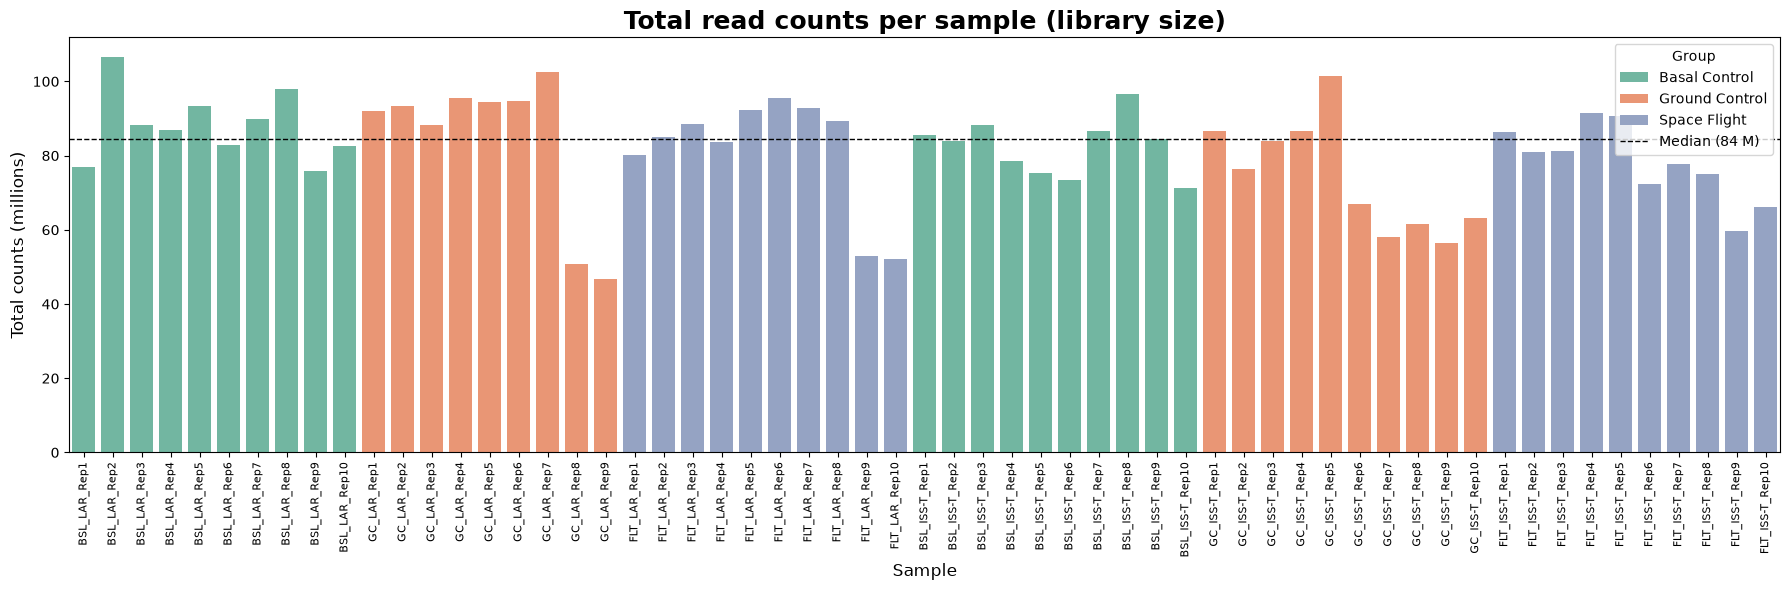

Library size range: 46.7 – 106.6 M (2.3-fold difference)


In [3]:
# Library size = total number of reads assigned to genes in each sample
sample_totals = counts_df.sum(axis=0)

# Shorten sample names for readability: "Mmus_C57-6T_LVR_FLT_LAR_Rep9_F4" -> "FLT_LAR_Rep9"
short_names = sample_totals.index.str.split("_").str[3:6].str.join("_")

lib_df = pd.DataFrame({
    "sample": short_names,
    "total_counts_M": sample_totals.values / 1e6,              # in millions of reads
    "group": metadata_df.loc[sample_totals.index, "Factor Value[Spaceflight]"].values,
})

fig, ax = plt.subplots(figsize=(18, 6))
sns.barplot(data=lib_df, x="sample", y="total_counts_M", hue="group",
            dodge=False, palette="Set2", ax=ax)
ax.axhline(lib_df["total_counts_M"].median(), color="black", ls="--", lw=1,
           label=f"Median ({lib_df['total_counts_M'].median():.0f} M)")
ax.set_title("Total read counts per sample (library size)", fontweight="bold", fontsize=18)
ax.set_ylabel("Total counts (millions)", fontsize=12)
ax.set_xlabel("Sample", fontsize=12)
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(title="Group", loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_library_sizes.png", dpi=300)
plt.show()

print(f"Library size range: {lib_df.total_counts_M.min():.1f} – {lib_df.total_counts_M.max():.1f} M "
      f"({lib_df.total_counts_M.max() / lib_df.total_counts_M.min():.1f}-fold difference)")

**Observation:** library sizes range from  46.7 to 106.6 million reads, about a two-fold difference. The lowest-depth libraries are not spread randomly across samples. They are concentrated in the higher replicate numbers (Rep6–10) of the Ground Control and Flight groups, which points to a technical batch effect (e.g. library preparation or sequencing run) rather than biology.

**Next step:** an exploratory PCA on log-transformed raw counts, to check whether these low-depth samples also separate from the others in overall expression.

### 2.2 Exploratory PCA on raw counts
Before any filtering or normalization, we run a quick PCA to see the dominant structure in the data. Counts are log(x+1)-transformed (RNA-seq counts are strongly right-skewed) and each gene is standardized to mean 0 and variance 1, so that highly expressed genes do not dominate.

At this stage all genes are included, so lowly expressed, noisy genes get the same weight as informative ones. This PCA is exploratory only and will be repeated after filtering and normalization.

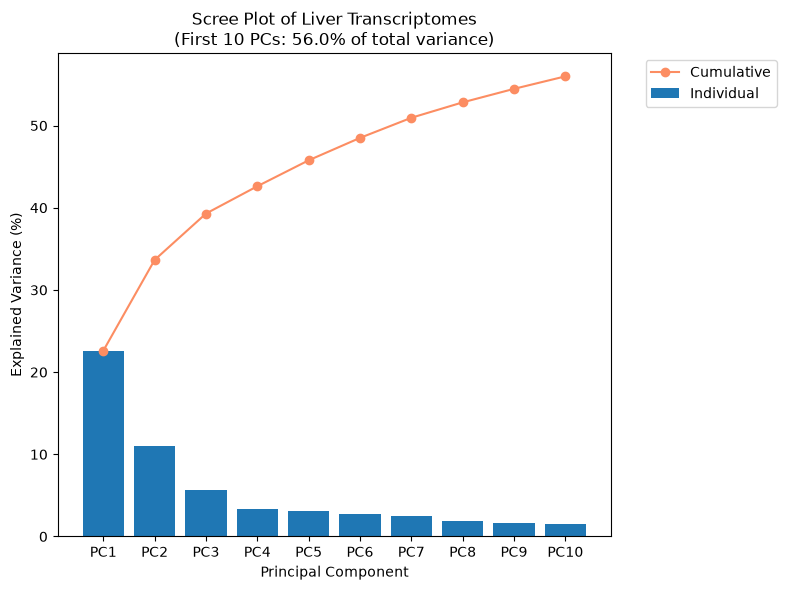

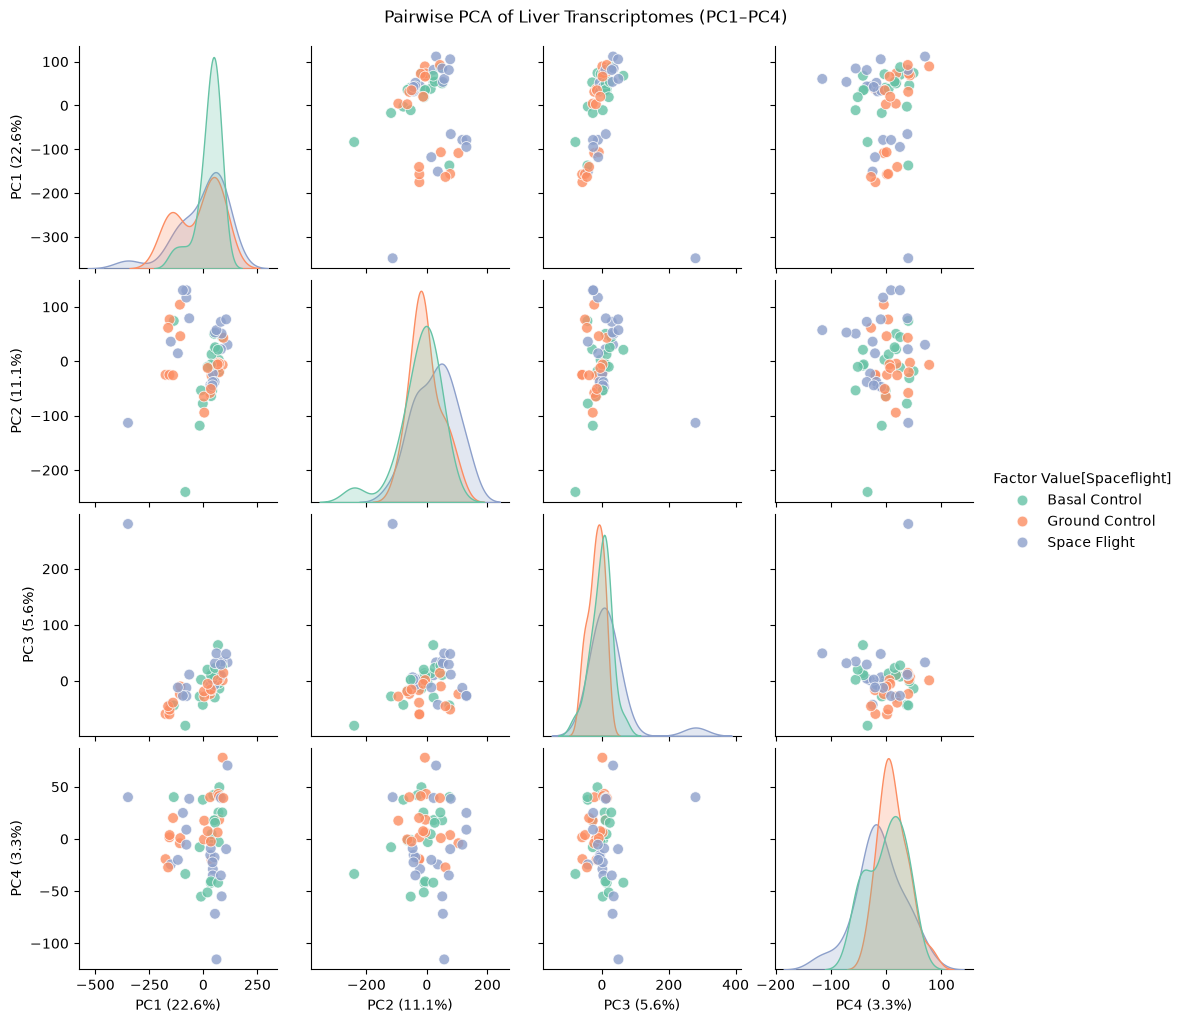

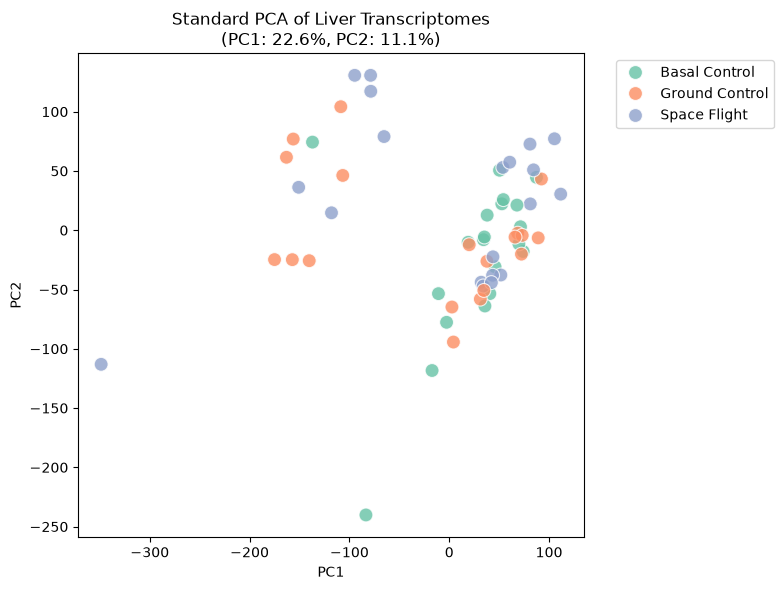

In [4]:
# RNA-seq data is highly skewed, so we apply a log(x+1) transform before PCA
log_counts = np.log1p(counts_df)   # log(x+1); log1p is more numerically precise for small x
log_counts = log_counts.T          # transpose; samples as rows, genes as columns (required for PCA)

# Standardize the features (genes) to have mean=0 and variance=1 before PCA
scaled_counts = StandardScaler().fit_transform(log_counts)

# Compute the first 10 principal components
n_components = 10
pca = PCA(n_components=n_components, random_state=SEED)
pca_result = pca.fit_transform(scaled_counts)

# Initialise a list of principal component names to be used as DataFrame columns
pc_cols = []
for i in range(n_components):
    pc_cols.append(f'PC{i+1}')     # 'PC1', 'PC2', ...

# Prepare a dataframe for plotting the PCs
pca_df = pd.DataFrame(pca_result, columns=pc_cols, index=counts_df.columns)

# Map the metadata group names
group_col = 'Factor Value[Spaceflight]'
pca_df = pca_df.merge(metadata_df[[group_col]],
                      left_index=True, right_index=True)

# ==========
# Scree plot: variance explained per PC
var_exp = pca.explained_variance_ratio_ * 100
plt.figure(figsize=(8, 6))
plt.bar(pc_cols, var_exp, label='Individual')
plt.plot(pc_cols, var_exp.cumsum(), marker='o', color=sns.color_palette('Set2')[1], label='Cumulative')
plt.xlabel('Principal Component')
plt.ylabel('Explained Variance (%)')
plt.title(f"Scree Plot of Liver Transcriptomes\n(First {n_components} PCs: {var_exp.sum():.1f}% of total variance)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / "02_scree_raw.png", dpi=300, bbox_inches='tight')     # NEW
plt.show()

# ==========
# Pairwise plots of the first 4 PCs
pcs_to_show = pc_cols[:4]          # only show the first 4 PCs for now
g = sns.pairplot(pca_df, vars=pcs_to_show, hue=group_col, palette='Set2',
                 plot_kws={'s': 60, 'alpha': 0.8}, diag_kind='kde')
# Add the % explained variance to each axis label, e.g. "PC1 (22.6%)"
for ax in g.axes.flatten():
    if ax is not None:
        for label_setter, label_getter in [(ax.set_xlabel, ax.get_xlabel), (ax.set_ylabel, ax.get_ylabel)]:
            lbl = label_getter()
            if lbl in pc_cols:
                label_setter(f"{lbl} ({pca.explained_variance_ratio_[pc_cols.index(lbl)]*100:.1f}%)")
g.fig.suptitle("Pairwise PCA of Liver Transcriptomes (PC1–PC4)", y=1.02)
g.savefig(FIG_DIR / "03_pairplot_raw.png", dpi=300, bbox_inches='tight')    # NEW (pairplot uses g.savefig)
plt.show()

# ==========
# PC1 vs PC2
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue=group_col, s=100, palette='Set2', alpha=0.8)
plt.title(f"Standard PCA of Liver Transcriptomes\n(PC1: {pca.explained_variance_ratio_[0]*100:.1f}%, PC2: {pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / "04_pca_raw.png", dpi=300, bbox_inches='tight')       # NEW
plt.show()

**Observation:**
- PC1 explains 22.6% of the variance and PC2 11.1%, followed by a sharp drop (PC3 5.6%). The first 10 PCs together explain 56%.
- The samples split into two clusters along PC1: a large main cluster and a smaller group of roughly 12 samples at negative PC1 values.
- The experimental groups (Basal Control, Ground Control, Space Flight) are mixed within both clusters, so the main source of variation is not the spaceflight condition. The smaller cluster consists almost entirely of Ground Control and Space Flight samples, the same groups that contain the low-depth libraries.
- Two individual outliers stand out: one Space Flight sample (far left on PC1, and on its own driving PC3) and one Basal Control sample (bottom of PC2).

### 2.3 Hierarchical clustering of highly variable genes (batch-effect check)
Batch effects are technical variations unrelated to the study factors of interest. They can dilute biological signal, reduce statistical power, or produce misleading results (Yu et al., 2024). Unsupervised methods such as PCA and hierarchical clustering are a common way to assess them. If samples cluster mainly by experimental group, the dominant signal is biological. If they cluster by something unrelated to the design, for example processing batch or sequencing depth, a technical factor is driving the variation. We cluster the samples on the 1000 most variable genes and mark each sample's experimental group with a colour bar. This also serves as an independent check of the two-cluster structure seen in the PCA.

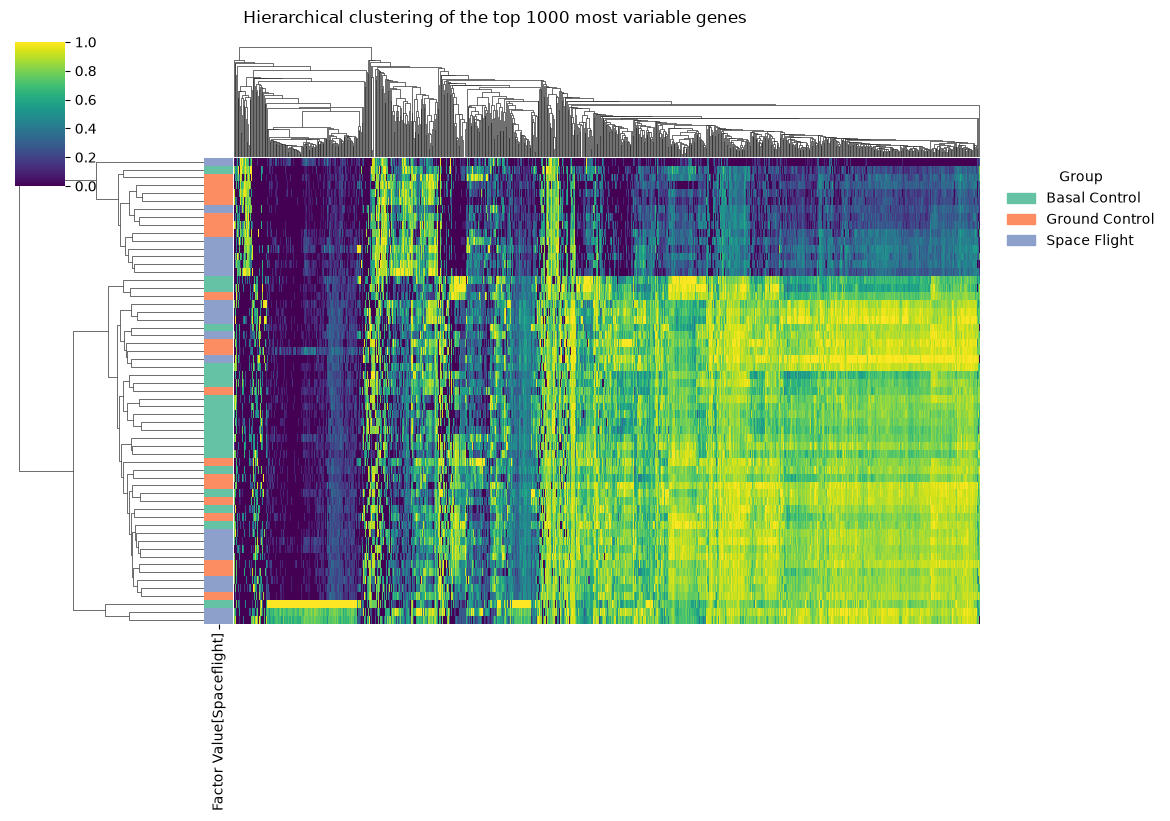

In [5]:
# Top 1000 highly variable genes (HVGs) on the log-transformed raw counts
gene_variances = log_counts.var(axis=0)
top_genes = gene_variances.nlargest(1000).index
hvg_data = log_counts[top_genes]

# Colour bar next to each row (sample) showing its experimental group
group_labels = metadata_df.loc[hvg_data.index, "Factor Value[Spaceflight]"]
lut = dict(zip(group_labels.unique(), sns.color_palette("Set2", group_labels.nunique())))
row_colors = group_labels.map(lut)

# Hierarchical clustering of samples (rows) and genes (columns)
g = sns.clustermap(hvg_data,
                   row_colors=row_colors,
                   cmap="viridis",
                   figsize=(10, 8),
                   standard_scale=1,                       # scale each gene to 0–1 for contrast
                   yticklabels=False, xticklabels=False)

# Manual legend for the group colours (clustermap doesn't create one)
from matplotlib.patches import Patch
handles = [Patch(color=c, label=grp) for grp, c in lut.items()]
g.ax_heatmap.legend(handles=handles, title="Group",
                    bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
g.fig.suptitle("Hierarchical clustering of the top 1000 most variable genes", y=1.02)
g.savefig(FIG_DIR / "05_hca_raw.png", dpi=300)
plt.show()

**Observation:** the clustering reproduces the PCA result. The sample dendrogram splits first into a small group (top), mostly Ground Control and Space Flight samples, and a large group in which all three experimental groups are mixed. The small group has a clearly different expression pattern across a large block of genes. Because the samples do not cluster by experimental group, this is a first indication of a batch effect: a technical factor, not spaceflight, drives the largest differences between samples. One sample at the bottom forms its own branch, consistent with the outliers seen in the PCA.

**Next step:** the dominant structure in the raw data does not follow the experimental design, and it plausibly matches the low-depth libraries. Before investigating this further, we first clean the count matrix: check for duplicates and missing values, then remove lowly expressed genes that only add noise.

## 3. Data cleaning and filtering

### 3.1 Data integrity checks
Before transforming the data we check for duplicated gene IDs, missing values, and samples that appear in only one of the counts and metadata tables. The count columns are then put in the same order as the metadata rows, so that every later step matching samples to their metadata is guaranteed to be correct.

In [6]:
# Data integrity checks on the raw count matrix
print(f"Duplicate gene IDs: {counts_df.index.duplicated().sum()} | "
      f"NaN values: {counts_df.isna().sum().sum()} | "
      f"Samples in counts but not metadata: {len(set(counts_df.columns) - set(metadata_df.index))} | "
      f"Samples in metadata but not counts: {len(set(metadata_df.index) - set(counts_df.columns))}")

# Drop duplicated gene rows if they exist (keep the first occurrence)
counts_clean = counts_df[~counts_df.index.duplicated(keep='first')]

# Fill any accidental NaN values with 0
counts_clean = counts_clean.fillna(0)

# Align column order of counts with row order of metadata
counts_clean = counts_clean[metadata_df.index]

Duplicate gene IDs: 0 | NaN values: 0 | Samples in counts but not metadata: 0 | Samples in metadata but not counts: 0


**Observation:** no duplicates, no missing values, and all 59 samples match between counts and metadata.

### 3.2 Low-expression filtering (CPM)
Most of the 57,278 annotated genes are barely expressed in liver. Their counts mainly reflect sampling noise and contain little biological signal. Keeping them adds noise to PCA and clustering and increases the multiple-testing burden in differential expression.

Raw counts depend on library size, which differs about two-fold between samples, as we established earlier. We therefore filter on counts per million (CPM), which corrects for depth: CPM = (gene count / total sample count) × 10⁶. A gene is kept if it has CPM > 1 in at least 9 samples, the size of the smallest experimental subgroup (Ground Control LAR, n = 9). This way a gene that is expressed in only one condition is not removed.

A CPM of 1 means one read per million sequenced reads. With our library sizes of roughly 45–105 million reads, that corresponds to about 45–105 raw reads per gene in a sample, so a gene that passes is clearly detected, not just a few stray reads A CPM > 1 is quite strict; but this is chosen to focus on only robustly expressed genes, ebcause this dataset already shows strong technical variation and low-count genes are most affected by differences in sequencing depth. Looking at the expression histogram below, we can also see that the threshold falls where the peak of the non-expressed genes end and the shoulder of the expressed genes begins.

Genes before: 57278 | after CPM filtering: 13078 (22.8% retained, 44200 removed)


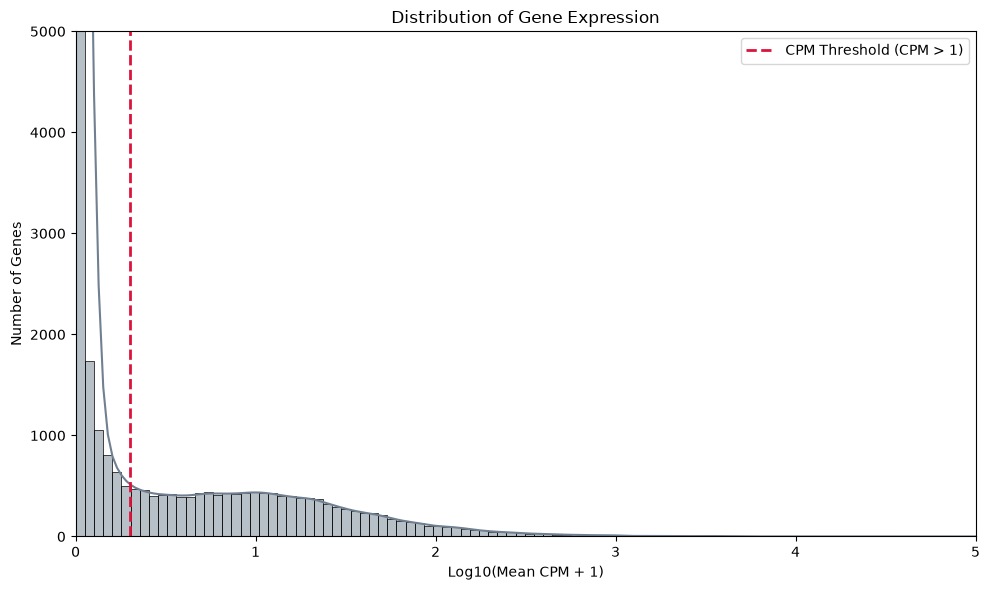

In [7]:
# Calculate CPM (Counts Per Million)
cpm_df = counts_clean.div(counts_clean.sum(axis=0), axis=1) * 1e6

# Keep genes with CPM > 1 in at least 9 samples = size of the smallest experimental subgroup
# (Ground Control LAR, n=9), so a gene expressed in only one subgroup is still retained
min_samples = 9
counts_filtered_cpm = counts_clean[(cpm_df > 1).sum(axis=1) >= min_samples]

n_before, n_after = counts_clean.shape[0], counts_filtered_cpm.shape[0]
print(f"Genes before: {n_before} | after CPM filtering: {n_after} "
     f"({n_after / n_before:.1%} retained, {n_before - n_after} removed)")

# Calculate the mean CPM for every single gene
mean_cpm = cpm_df.mean(axis=1)

# Log10 transform the means (adding 1 to safely handle zeros)
log10_mean_cpm = np.log10(mean_cpm + 1)

# Calculate where a CPM of 1 lands on this log10(x+1) scale
# log10(1 + 1) = log10(2) ≈ 0.301
cpm_threshold_log = np.log10(1 + 1)

# Plot the Bimodal Histogram
plt.figure(figsize=(10, 6))
sns.histplot(log10_mean_cpm, bins=100, color='slategray', kde=True)

# Add a vertical red line for your CPM threshold
plt.axvline(x=cpm_threshold_log, color='crimson', linestyle='--', linewidth=2,
            label='CPM Threshold (CPM > 1)')

plt.title("Distribution of Gene Expression")
plt.xlabel("Log10(Mean CPM + 1)")
plt.ylabel("Number of Genes")
plt.xlim(0, 5) # Adjusted to fit standard CPM ranges
plt.ylim(0, 5000)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_cpm_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:** 13,078 of 57,278 genes (22.8%) pass the filter. The distribution of mean expression shows the expected shape: a large peak of genes with near-zero expression (not expressed in liver; the y-axis is truncated at 5,000 for visual purposes) and a broad shoulder of expressed genes. The threshold (red line) separates the two.

**Next step:** the filtered raw counts are normalized for library size, so that expression values can be compared between samples.

## 4. Normalization

### 4.1 Median-of-ratios normalization
Even after filtering, raw counts are not comparable between samples, because each sample was sequenced to a different depth. We use the median-of-ratios method from DESeq2 (Anders & Huber, 2010), implemented here from scratch to make each step explicit:

1. For every gene, compute a pseudo-reference: its geometric mean across all samples.
2. For every sample, divide each gene's count by that reference.
3. The sample's size factor is the median of these ratios.
4. Divide all counts in the sample by its size factor.

Using the *median* makes the method robust: a few strongly differentially expressed genes do not shift the size factor, unlike simple total-count scaling (CPM). This is why median-of-ratios is preferred over CPM for normalization, even though CPM was fine for *filtering*.

The normalized counts are then log2(x+1)-transformed and a PCA is repeated, to see whether normalization removes the two-cluster structure found in Section 2.

Median-of-ratios normalization complete. Matrix shape: (13078, 59)
Size factors range: 0.40 – 1.56 | correlation with library size: r = 0.721


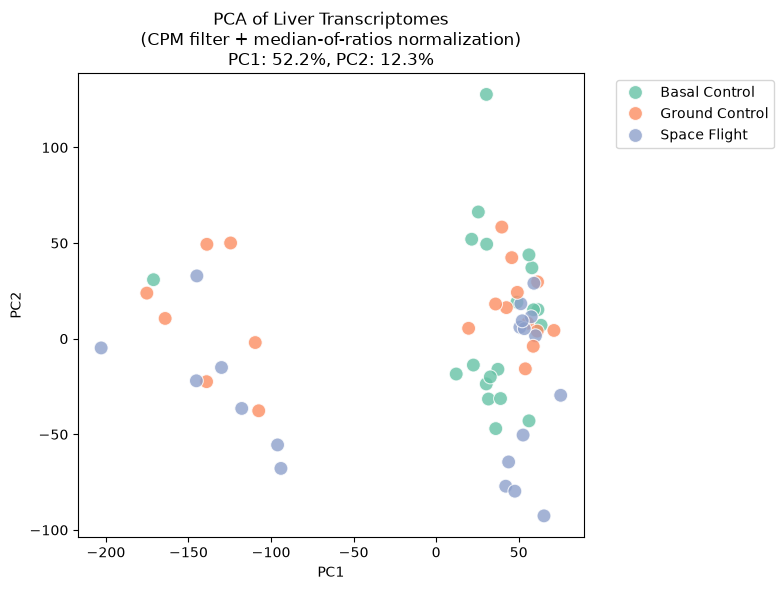

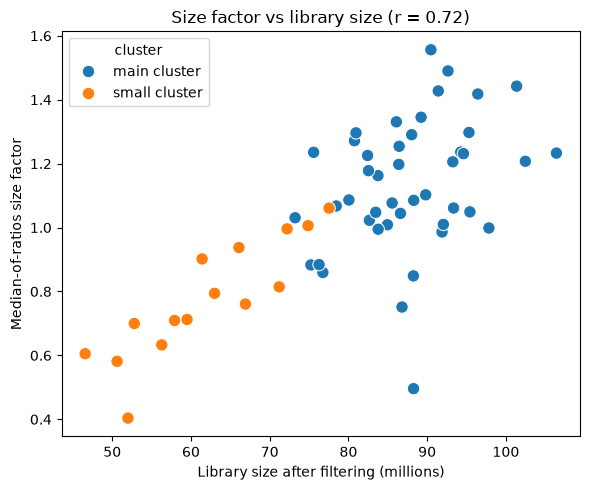

In [8]:
def median_of_ratios(counts):
    """DESeq2-style median-of-ratios normalization (Anders & Huber, 2010).

    1. Pseudo-reference per gene = geometric mean across samples (genes with a zero in any sample are excluded)
    2. For each sample: ratio of each gene's count to the reference
    3. Size factor = median of these ratios (robust to a few highly differentially expressed genes)
    4. Normalized counts = raw counts / size factor
    """
    pos = (counts > 0).all(axis=1)                                   # genes detected in ALL samples
    logc = np.log(counts[pos])
    size_factors = np.exp(logc.sub(logc.mean(axis=1), axis=0).median(axis=0))
    return counts.div(size_factors, axis=1), size_factors

# Apply the normalization to the CPM-filtered raw counts
deseq_normalized_counts, size_factors = median_of_ratios(counts_filtered_cpm)

# Log2(x+1) transformation for PCA
log2_deseq_empirical = np.log2(deseq_normalized_counts + 1)

print(f"Median-of-ratios normalization complete. Matrix shape: {log2_deseq_empirical.shape}")

# Sanity check, size factors should track library size
lib_size = counts_filtered_cpm.sum(axis=0)
print(f"Size factors range: {size_factors.min():.2f} – {size_factors.max():.2f} | "
      f"correlation with library size: r = {np.corrcoef(size_factors, lib_size)[0, 1]:.3f}")


# ======
# PCA on normalized, log-transformed data
# Standardize genes (mean 0, variance 1)
scaled_deseq_counts = StandardScaler().fit_transform(log2_deseq_empirical.T)

# Fit the PCA model
pca_deseq = PCA(n_components=2, random_state=SEED)
pca_result_deseq = pca_deseq.fit_transform(scaled_deseq_counts)

# Build the plotting dataframe
group_col = 'Factor Value[Spaceflight]'
pca_df_deseq = pd.DataFrame(pca_result_deseq, columns=['PC1', 'PC2'], index=log2_deseq_empirical.columns)
pca_df_deseq = pca_df_deseq.merge(metadata_df[[group_col]],
                                  left_index=True, right_index=True)

# Scatter plot
plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df_deseq, x='PC1', y='PC2', hue=group_col, s=100, palette='Set2', alpha=0.8)
pc1_var = pca_deseq.explained_variance_ratio_[0] * 100
pc2_var = pca_deseq.explained_variance_ratio_[1] * 100
plt.title(f"PCA of Liver Transcriptomes\n(CPM filter + median-of-ratios normalization)\n"
          f"PC1: {pc1_var:.1f}%, PC2: {pc2_var:.1f}%")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / "07_pca_normalized.png", dpi=300, bbox_inches='tight')
plt.show()

# Size factor vs library size
# Do the samples whose size factor deviates from library size fall in the small PCA cluster?
sf_df = pd.DataFrame({"size_factor": size_factors,
                      "lib_size_M": lib_size / 1e6,
                      "cluster": np.where(pca_df_deseq["PC1"] < -50, "small cluster", "main cluster")})
plt.figure(figsize=(6, 5))
sns.scatterplot(data=sf_df, x="lib_size_M", y="size_factor", hue="cluster", s=80)
plt.xlabel("Library size after filtering (millions)")
plt.ylabel("Median-of-ratios size factor")
plt.title(f"Size factor vs library size (r = {np.corrcoef(size_factors, lib_size)[0, 1]:.2f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "08_sizefactor_vs_libsize.png", dpi=300, bbox_inches="tight")
plt.show()

**Observation:**
- Size factors range from 0.40 to 1.56, while library sizes differ only about 2-fold, and the two are only moderately correlated (r = 0.72). So the size factors do more than correct for sequencing depth. They also correct for differences in library composition, where a few highly abundant genes take up a different share of the reads in some samples.
- After filtering and normalization, the two-cluster split along PC1 remains, and becomes even more dominant: PC1 now explains 52.2% of the variance (22.6% before filtering). Removing ~44,000 noisy low-count genes made the main structure in the data sharper rather than weaker.
- The smaller cluster (about 15 samples) again contains mainly Ground Control and Space Flight samples, with all groups mixed in the large cluster. The two extreme outliers from the raw PCA are no longer extreme; they were driven by noisy low-count genes that the filter removed.
- The size factor plot shows that the small cluster consists exactly of the lowest-depth libraries (all below ~78 M reads).

Normalization corrects for how many reads a sample has, but the split remains. So the difference between the clusters is not simply a scaling difference in depth: the low-depth samples also differ in the composition of their expression profile, for example due to RNA quality or a separate library-preparation or sequencing batch. This fits the batch-effect hypothesis from earlier.

**Next step:** log2(x+1) does not fully stabilize the variance of low counts, so they can still distort a PCA. We therefore apply DESeq2's variance-stabilizing transformation (VST) and check whether the two clusters are still present.

### 4.2 Variance-stabilizing transformation (VST)
In count data the variance depends on the mean. log2(x+1) only partly fixes this. For low counts, small random differences still become large differences on the log scale, so noisy low-count genes can still dominate a PCA. DESeq2's variance-stabilizing transformation (VST) models this mean–variance relationship and transforms the counts so that variance is roughly constant across expression levels (Love et al., 2014).

Blind VST (`design = "~1"`): the transformation does not know the experimental groups, so it cannot bias this exploratory step towards the expected result.

For the PCA, genes are only centred, not scaled to unit variance, because VST has already put all genes on a comparable variance scale.

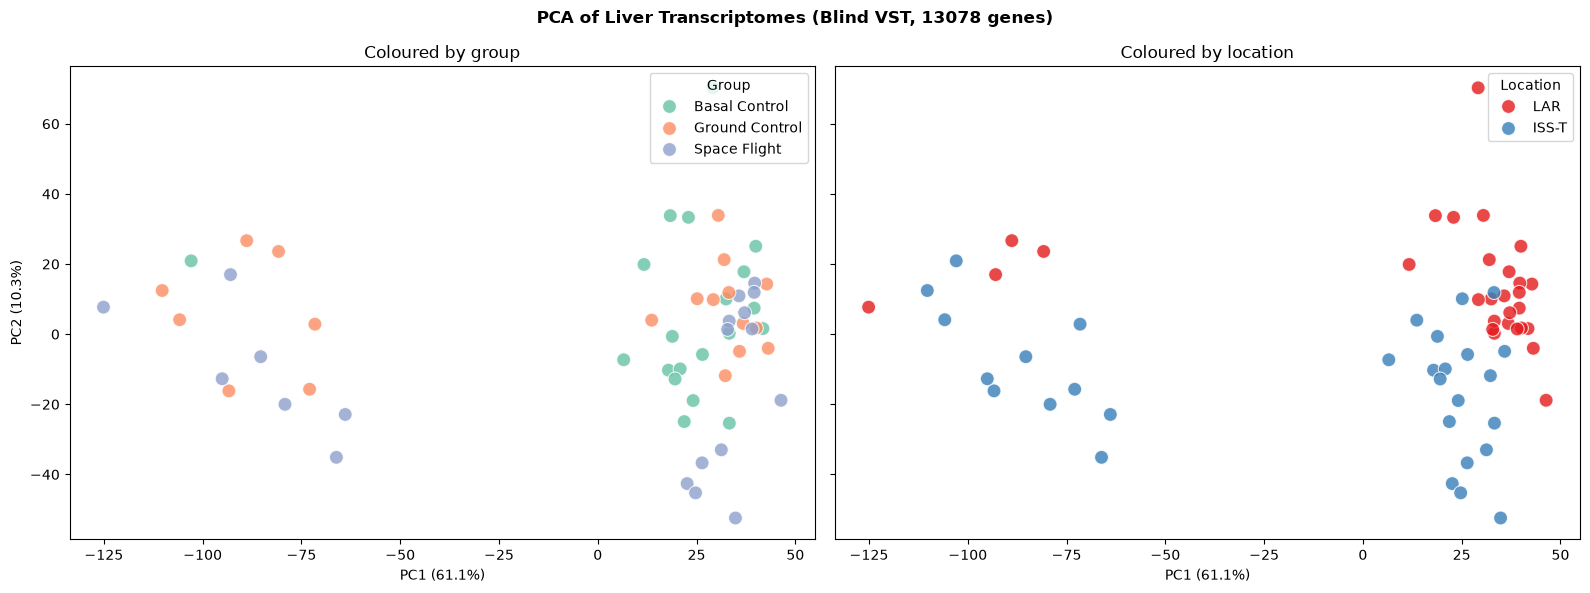

In [9]:
# VST needs raw integer counts; RSEM gives expected (non-integer) counts, so round first
vst_input_counts = counts_filtered_cpm.T.round().astype(int)       # samples x genes

# Blind VST: design="~1" means the transformation does not see the experimental groups
dds_vst = DeseqDataSet(counts=vst_input_counts,
                       metadata=metadata_df.loc[vst_input_counts.index],
                       design="~1",
                       quiet=True)
dds_vst.vst()                                                       # fits size factors + dispersion trend, then transforms

vst_df = pd.DataFrame(dds_vst.layers['vst_counts'],
                      index=dds_vst.obs_names, columns=dds_vst.var_names)   # samples x genes

# PCA on all genes: centred but not scaled, since VST already stabilizes the variance
X_vst = vst_df - vst_df.mean(axis=0)
pca_vst_raw = PCA(n_components=2, random_state=SEED).fit(X_vst)
pca_df_vst_raw = pd.DataFrame(pca_vst_raw.transform(X_vst), columns=['PC1', 'PC2'], index=vst_df.index)

# Add experimental group and mission location (LAR = Live Animal Return, ISS-T = ISS Terminal)
pca_df_vst_raw['Group'] = metadata_df.loc[pca_df_vst_raw.index, 'Factor Value[Spaceflight]']
pca_df_vst_raw['Location'] = metadata_df.loc[pca_df_vst_raw.index, 'Source Name'].apply(
    lambda x: 'LAR' if 'LAR' in str(x) else ('ISS-T' if 'ISS-T' in str(x) else 'Other'))

# Same PCA side by side, coloured by group (left) and by location (right)
ev = pca_vst_raw.explained_variance_ratio_ * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, hue, palette in zip(axes, ['Group', 'Location'], ['Set2', 'Set1']):
    sns.scatterplot(data=pca_df_vst_raw, x='PC1', y='PC2', hue=hue,
                    s=100, palette=palette, alpha=0.8, ax=ax)
    ax.set_title(f"Coloured by {hue.lower()}")
    ax.set_xlabel(f"PC1 ({ev[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({ev[1]:.1f}%)")
    ax.legend(title=hue, loc='upper right')
fig.suptitle(f"PCA of Liver Transcriptomes (Blind VST, {vst_df.shape[1]} genes)", fontweight='bold')
plt.tight_layout()
plt.savefig(FIG_DIR / "09_pca_vst_group_location.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- The two-cluster split along PC1 remains after VST and is now even more dominant (PC1: 61.1%, PC2: 10.3%). The split is therefore not an artefact of the log transformation.
- Colouring by mission location reveals that within the main cluster, LAR samples (Live Animal Return, dissected after return to Earth) lie at positive PC2 and ISS-T samples (ISS Terminal, dissected on orbit) at negative PC2. The small cluster consists mostly of ISS-T samples.
- The experimental groups remain mixed along PC1, so the spaceflight effect is still not the dominant signal.

**Next step:** the PC1 split has persited after filtering, normalization and variance stabilization, and it matches the low-depth libraries. To find out which technical factor drives it, we compare the PCA with the per-sample QC metrics provided by NASA's GeneLab.

## 5. Technical variation: linking the PCA to QC metrics

### 5.1 Sequencing depth
The two-cluster split along PC1 that survives filtering, normalization and VST, and that does not follow the experimental groups needs to be further explored using QC metrics. GeneLab provides per-sample QC metrics, which let us test directly which technical factor drives it. We start with the most likely candidate, sequencing depth, by colouring the PCA with read depth and labelling the 10 shallowest libraries.

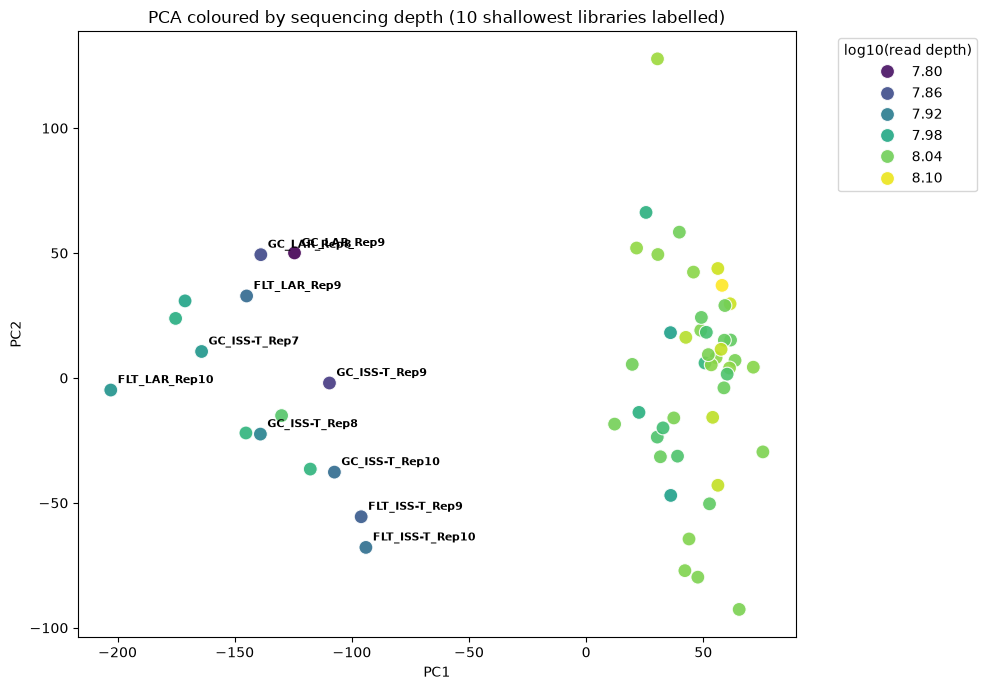

In [10]:
# PCA (coloured by sequencing depth
pca_df_deseq['read_depth'] = qc_df.loc[pca_df_deseq.index, 'read_depth'].astype(float)
pca_df_deseq['log10_read_depth'] = np.log10(pca_df_deseq['read_depth'])

plt.figure(figsize=(10, 7))
ax = sns.scatterplot(data=pca_df_deseq, x='PC1', y='PC2',
                     hue='log10_read_depth', palette='viridis', s=100, alpha=0.9)

# Label the 10 shallowest libraries, e.g. "FLT_ISS-T_Rep9"
shallow_samples = pca_df_deseq.nsmallest(10, 'read_depth')
for sample, row in shallow_samples.iterrows():
    short_name = "_".join(sample.split('_')[3:6])
    ax.annotate(short_name, (row['PC1'], row['PC2']),
                xytext=(5, 5), textcoords='offset points', fontsize=8, fontweight='bold')

plt.title("PCA coloured by sequencing depth (10 shallowest libraries labelled)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="log10(read depth)")
plt.tight_layout()
plt.savefig(FIG_DIR / "10_pca_read_depth.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:** all 10 shallowest libraries fall in the small cluster, and the small cluster contains no deep libraries. Depth alone does not explain the split, however: normalization should have removed a pure depth effect. We therefore check whether the low-depth samples also differ in other quality metrics.

### 5.2 Other QC metrics
We overlay seven QC metrics on the same PCA, covering sequencing (depth, duplicates, GC content), alignment (uniquely mapped reads, rRNA contamination), RNA quality (RIN) and library complexity (genes detected).

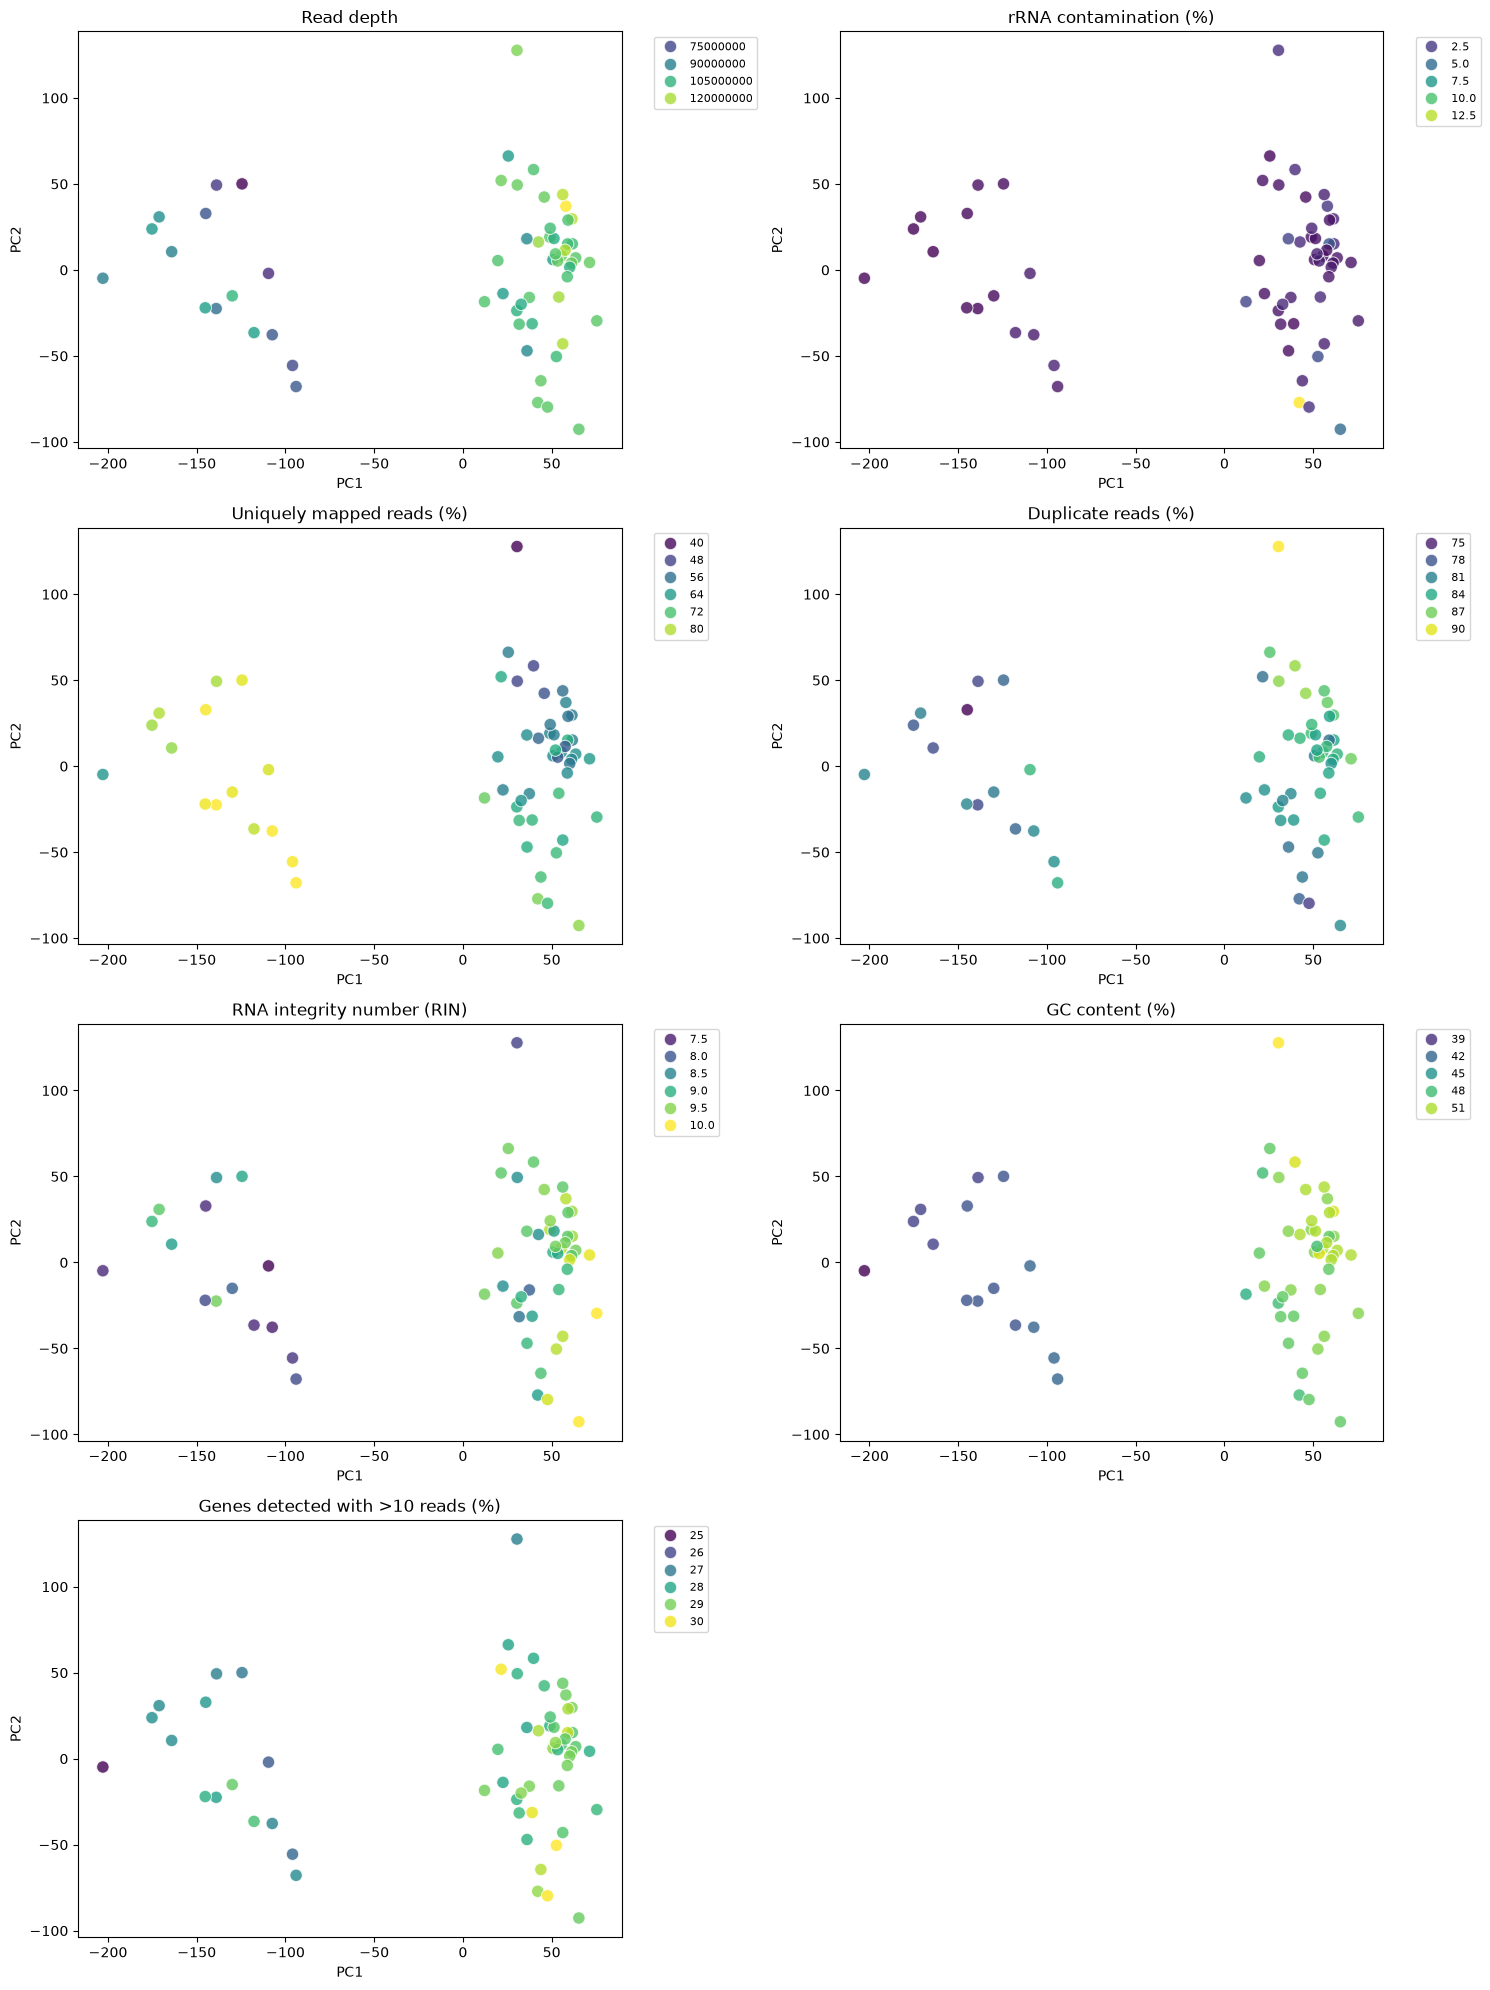

In [11]:
# QC metrics to overlay on the PCA, with readable names for the plot titles
qc_metrics = {
    'read_depth':               'Read depth',
    'rrna_contamination':       'rRNA contamination (%)',
    'uniquely_mapped_percent':  'Uniquely mapped reads (%)',
    'raw_percent_duplicates_f': 'Duplicate reads (%)',
    'rin':                      'RNA integrity number (RIN)',
    'raw_percent_gc_f':         'GC content (%)',
    'gene_detected_gt10_pct':   'Genes detected with >10 reads (%)',
}

# Separate plotting dataframe, so pca_df_deseq itself is not modified
pca_qc_plot_df = pca_df_deseq[['PC1', 'PC2']].join(
    qc_df[list(qc_metrics)].apply(pd.to_numeric, errors='coerce'))

# One PCA panel per QC metric (7 metrics in a 4 x 2 grid)
fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15, 20))
axes = axes.flatten()
for ax, (col, label) in zip(axes, qc_metrics.items()):
    sns.scatterplot(data=pca_qc_plot_df, x='PC1', y='PC2',
                    hue=col, palette='viridis', s=80, alpha=0.8, ax=ax)
    ax.set_title(label)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
axes[-1].set_visible(False)                                        # hide the unused 8th panel

plt.tight_layout()
plt.savefig(FIG_DIR / "11_pca_qc_metrics.png", dpi=300, bbox_inches='tight')
plt.show()

In [12]:
# Median QC values per PCA cluster (small cluster = PC1 < -50)
qc_by_cluster = pca_qc_plot_df.groupby(np.where(pca_qc_plot_df.PC1 < -50, 'small cluster', 'main cluster')).median().drop(columns=['PC1', 'PC2']).T
qc_by_cluster.to_csv(TABLE_DIR / "qc_medians_per_cluster.csv")
display(qc_by_cluster.round(2))

,main cluster,small cluster
read_depth,1.107811e+08,85083522.00
rrna_contamination,1.380000e+00,0.61
uniquely_mapped_percent,6.158000e+01,83.53
raw_percent_duplicates_f,8.403000e+01,80.60
rin,9.300000e+00,7.90
raw_percent_gc_f,5.000000e+01,41.00
gene_detected_gt10_pct,2.881000e+01,27.38


**Observation:** several QC metrics separate the two clusters, not just depth:

| Metric | Small cluster | Main cluster |
|---|---|---|
| Read depth (millions) | 85.1 | 110.8 |
| Uniquely mapped reads (%) | 83.5| 61.6 |
| GC content (%) | 41 | 50 |
| Duplicate reads (%) | 80.6 | 84.0 |
| RIN | 7.9 | 9.3 |
| Genes detected with >10 reads (%) | 27.4 | 28.8 |
| rRNA contamination (%) | 0.6 | 1.4 |

The small-cluster samples thus differ systematically in several independent aspects of library quality at once. That is the typical signature of a separate library-preparation or sequencing batch, not of random sample-to-sample variation, and it agrees with the replicate pattern seen in earlier steps.

**Next step:** if these QC covariates explain the split, removing their effect from the expression data should make the two clusters disappear. As a first, quick test we regress the main covariates (depth, RIN, mapping rate) out of the VST data and repeat the PCA.

### 5.3 Regressing out QC covariates (exploratory)
If the PC1 split is caused by technical factors, removing their effect should make it disappear. For each gene we fit a linear regression of its VST expression on the QC covariates and keep only the residuals, i.e. the part of the expression that the covariates do not explain. We then repeat the PCA on these residuals, first with depth only, then with depth + RIN + mapping rate (the three metrics that differed most between the clusters).

This is a naive regression. Because the small cluster consists mainly of Ground Control and Space Flight samples, the covariates are partly confounded with the experimental groups, so regressing them out may also remove some real biological signal. A group-protected version of this correction will follow in downstream analyses. --> It is purely exploratory.

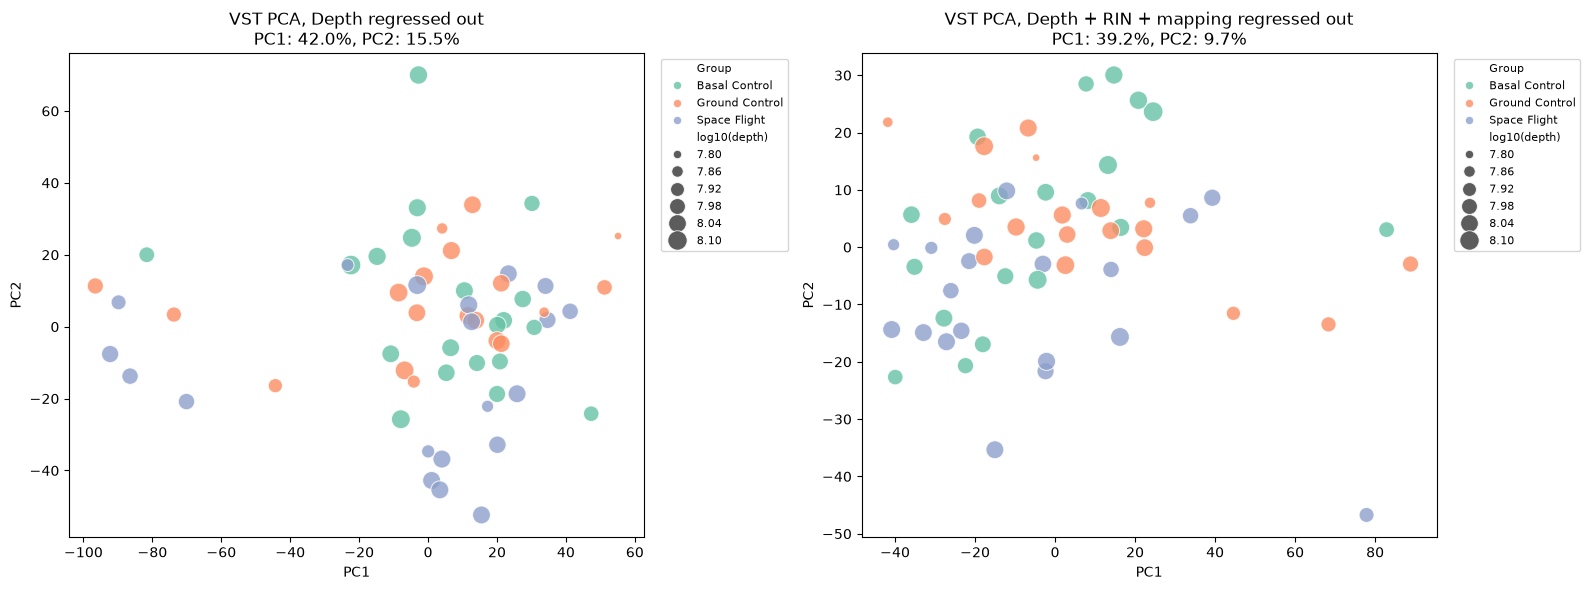

In [13]:
# Quick exploratory check to see wether regressing out QC metrics removes the two clusters or not
qc_cov = qc_df.loc[vst_df.index, ['read_depth', 'rin', 'uniquely_mapped_percent']].astype(float)
qc_cov['log10_read_depth'] = np.log10(qc_cov['read_depth'])

covariate_sets = {
    'Depth regressed out': ['log10_read_depth'],
    'Depth + RIN + mapping regressed out': ['log10_read_depth', 'rin', 'uniquely_mapped_percent'],
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (title, covs) in zip(axes, covariate_sets.items()):
    X = qc_cov[covs].values
    resid = vst_df.values - LinearRegression().fit(X, vst_df.values).predict(X)   # remove covariate effect per gene
    pca_tmp = PCA(n_components=2, random_state=SEED).fit(resid)
    scores = pd.DataFrame(pca_tmp.transform(resid), columns=['PC1', 'PC2'], index=vst_df.index)
    scores['Group'] = metadata_df.loc[scores.index, 'Factor Value[Spaceflight]']
    scores['log10(depth)'] = qc_cov['log10_read_depth']
    sns.scatterplot(data=scores, x='PC1', y='PC2', hue='Group',
                    size='log10(depth)', sizes=(30, 200), palette='Set2', alpha=0.8, ax=ax)
    ev = pca_tmp.explained_variance_ratio_ * 100
    ax.set_title(f"VST PCA, {title}\nPC1: {ev[0]:.1f}%, PC2: {ev[1]:.1f}%")
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "12_pca_qc_regressed.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- **Depth only:** the split weakens (PC1 drops from 61.1% to 42.0%), but a group of samples still separates along PC1. Depth alone does not explain the structure.
- **Depth + RIN + mapping rate:** the two-cluster structure disappears. The samples form one continuous cloud, and the experimental groups start to become visible instead (Basal Control mostly at positive PC2, Space Flight mostly at negative PC2).

This confirms that the dominant PC1 split is a technical effect, explained by a combination of sequencing depth, RNA integrity and mapping rate, and not by spaceflight. Once it is removed, biological structure starts to show.

**Next step:** before formally correcting for this effect, we look at which samples and which genes drive PC1, to check whether it has a biological signature that could be mistaken for a spaceflight effect.

### 5.4 Which genes drive PC1?
If PC1 were biological, we would expect a specific set of genes with large loadings that share a function. If it is technical, we expect a broad shift spread across many genes without a common biological theme. We look at the 20 genes with the largest PC1 loadings, show them in a biplot, and test both sides of PC1 for GO enrichment with Enrichr (Kuleshov et al., 2016), via the GSEApy package (Fang et al., 2023).

Largest |loading|: 0.0120 | even spread over 13078 genes would give 1/sqrt(n) = 0.0087


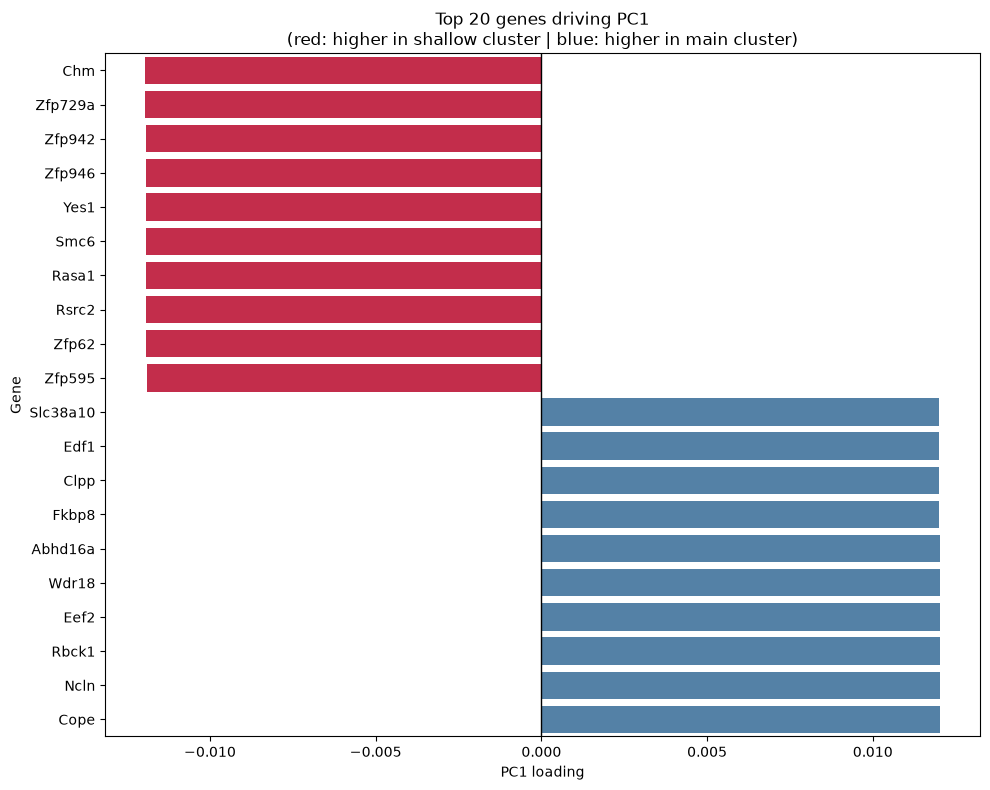

In [14]:
# PC1 loadings of the normalized PCA one weight per gene
loadings_df = pd.DataFrame({'Gene_ID': log2_deseq_empirical.index,
                            'PC1_Loading': pca_deseq.components_[0]})

# Top 10 negative (higher in the shallow cluster, negative PC1) and top 10 positive (higher in the main cluster)
top_negative = loadings_df.nsmallest(10, 'PC1_Loading')
top_positive = loadings_df.nlargest(10, 'PC1_Loading').iloc[::-1]
top_pc1_genes = pd.concat([top_negative, top_positive])

# Look up gene symbols for the top genes (Ensembl ID -> symbol, needs internet)
hits = mygene.MyGeneInfo().querymany(list(top_pc1_genes['Gene_ID']), scopes='ensembl.gene',
                                     fields='symbol', species='mouse', as_dataframe=True, verbose=False)
hits = hits[~hits.index.duplicated()]
ensembl_to_symbol = hits['symbol'].dropna().to_dict()
top_pc1_genes['Symbol'] = top_pc1_genes['Gene_ID'].map(ensembl_to_symbol).fillna(top_pc1_genes['Gene_ID'])

# How special are the top genes --> Compare with an even spread over all genes
print(f"Largest |loading|: {loadings_df.PC1_Loading.abs().max():.4f} | "
      f"even spread over {len(loadings_df)} genes would give 1/sqrt(n) = {1/np.sqrt(len(loadings_df)):.4f}")

plt.figure(figsize=(10, 8))
sns.barplot(data=top_pc1_genes, x='PC1_Loading', y='Symbol',
            palette=['crimson'] * 10 + ['steelblue'] * 10)
plt.axvline(0, color='black', linewidth=1)
plt.title("Top 20 genes driving PC1\n(red: higher in shallow cluster | blue: higher in main cluster)")
plt.xlabel("PC1 loading")
plt.ylabel("Gene")
plt.tight_layout()
plt.savefig(FIG_DIR / "13_pc1_top_loadings.png", dpi=300, bbox_inches='tight')
plt.show()

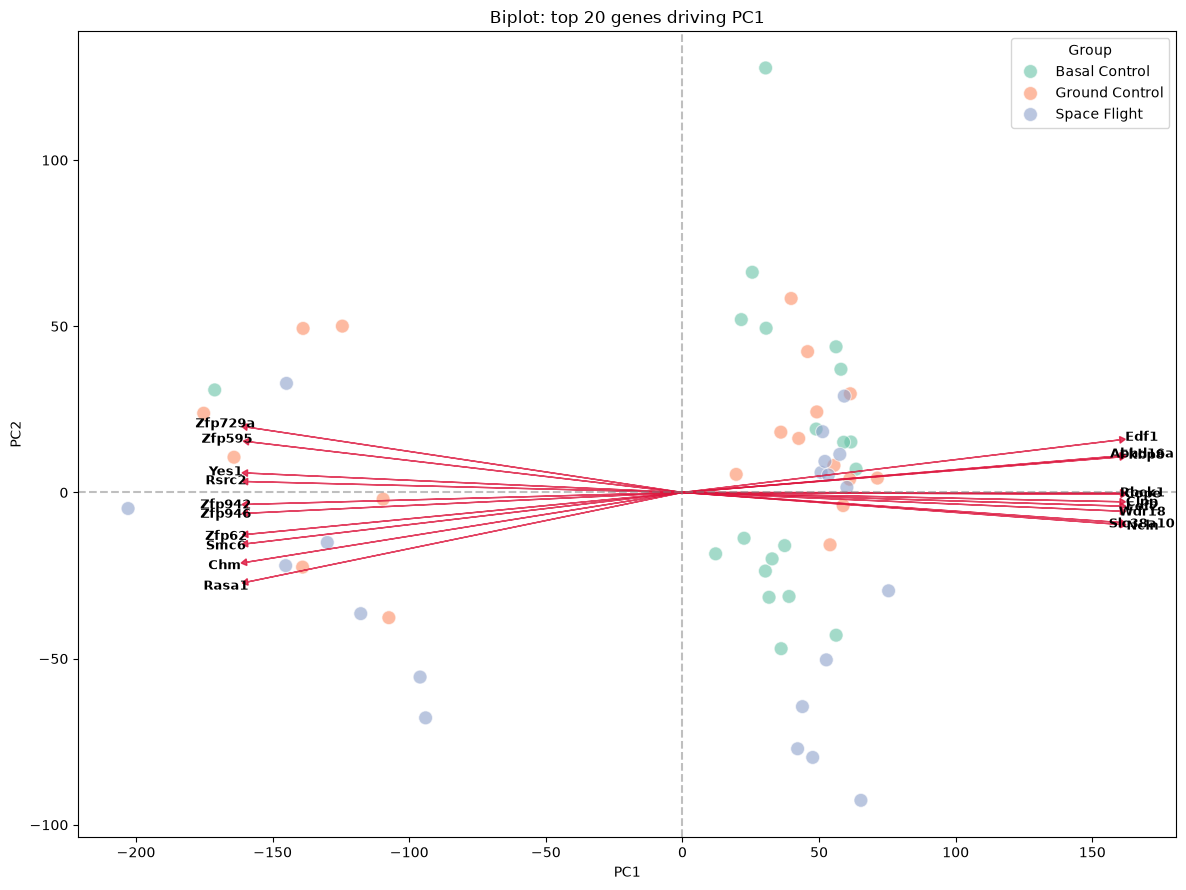

In [15]:
# Biplot: samples (dots) and the 20 top-loading genes (arrows) in the same PCA space
plt.figure(figsize=(12, 9))
sns.scatterplot(data=pca_df_deseq, x='PC1', y='PC2', hue='Factor Value[Spaceflight]',
                palette='Set2', s=100, alpha=0.6)

# Scale arrows to the range of the sample scores so both fit in one plot
top_loadings = pca_deseq.components_.T
scale_factor = max(pca_df_deseq['PC1'].max(), pca_df_deseq['PC2'].max()) / pca_deseq.components_.max()
stretch_multiplier = 2.5

for gene_id, symbol in zip(top_pc1_genes['Gene_ID'], top_pc1_genes['Symbol']):
    i = log2_deseq_empirical.index.get_loc(gene_id)
    x_vec = top_loadings[i, 0] * scale_factor * stretch_multiplier
    y_vec = top_loadings[i, 1] * scale_factor * stretch_multiplier
    plt.arrow(0, 0, x_vec, y_vec, color='crimson', alpha=0.8, head_width=2, head_length=2)
    plt.text(x_vec * 1.05, y_vec * 1.05, symbol, ha='center', va='center', fontsize=9, fontweight='bold')

plt.axhline(0, color='grey', linestyle='--', alpha=0.5)
plt.axvline(0, color='grey', linestyle='--', alpha=0.5)
plt.title("Biplot: top 20 genes driving PC1")
plt.legend(title='Group')
plt.tight_layout()
plt.savefig(FIG_DIR / "14_pc1_biplot.png", dpi=300, bbox_inches='tight')
plt.show()

In [16]:
# Enrichr (GO Biological Process) on the two sides of PC1; requires gene symbols and internet
neg_genes = top_pc1_genes['Symbol'].iloc[:10].tolist()     # higher in shallow cluster
pos_genes = top_pc1_genes['Symbol'].iloc[10:].tolist()     # higher in main cluster

enr_neg = gp.enrichr(gene_list=neg_genes, gene_sets='GO_Biological_Process_2023', organism='mouse', outdir=None)
enr_pos = gp.enrichr(gene_list=pos_genes, gene_sets='GO_Biological_Process_2023', organism='mouse', outdir=None)

cols = ['Term', 'Overlap', 'Adjusted P-value']
print("Negative PC1 genes (higher in shallow cluster):")
display(enr_neg.results[cols].head())
print("\nPositive PC1 genes (higher in main cluster):")
display(enr_pos.results[cols].head())

enr_neg.results.to_csv(TABLE_DIR / "pc1_negative_enrichment.csv", index=False)
enr_pos.results.to_csv(TABLE_DIR / "pc1_positive_enrichment.csv", index=False)

Negative PC1 genes (higher in shallow cluster):


,Term,Overlap,Adjusted P-value
0,Ephrin Receptor Signaling Pathway (GO:0048013),2/43,0.011455
1,Negative Regulation By Host Of Viral Genome Re...,1/8,0.048003
2,Telomere Maintenance Via Recombination (GO:000...,1/9,0.048003
3,Protein Prenylation (GO:0018342),1/10,0.048003
4,Negative Regulation By Host Of Viral Process (...,1/12,0.048003



Positive PC1 genes (higher in main cluster):


,Term,Overlap,Adjusted P-value
0,Monoacylglycerol Catabolic Process (GO:0052651),1/6,0.080112
1,Multi-Pass Transmembrane Protein Insertion Int...,1/8,0.080112
2,Endothelium Development (GO:0003158),1/12,0.080112
3,Monoacylglycerol Metabolic Process (GO:0046462),1/13,0.080112
4,Cellular Modified Amino Acid Catabolic Process...,1/13,0.080112


**Observation:**
- The top-20 loadings are nearly identical in size (about 0.012), only slightly above the value expected if all 13,078 genes contributed equally (1/√n ≈ 0.0087). PC1 is therefore a broad, global shift across thousands of genes, not driven by a specific gene set.- Genes higher in the main (deep) cluster are short, highly expressed housekeeping genes (e.g. *Eef2*, *Edf1*, *Cope*, *Clpp*). Genes higher in the shallow cluster are dominated by zinc-finger genes (*Zfp729a*, *Zfp942*, *Zfp946*, *Zfp62*, *Zfp595*). Together with the GC-content difference between the clusters, this is consistent with a library-quality bias between batches.
- GO enrichment finds no coherent biological process: each term overlaps only 1–2 genes, with adjusted p-values between 0.01 and 0.08.

PC1 shows no biological signature, which further supports the conclusion that it is a technical batch effect.

**Next step:** to quantify how strongly each QC metric is associated with the main axes of variation, we correlate the first five PCs with all QC metrics (Section 5.5).

### 5.5 Which QC metrics explain the main axes of variation?
So far we compared the PCA with a handful of QC metrics by eye. GeneLab provides 82 numeric QC metrics per sample, so we now quantify the association systematically: for each of the first five PCs we compute the R² (squared Pearson correlation) with every QC metric. We keep the metrics with R² > 0.3 on at least one PC and drop redundant variants.

29 of 82 QC metrics have R² > 0.3 with at least one PC


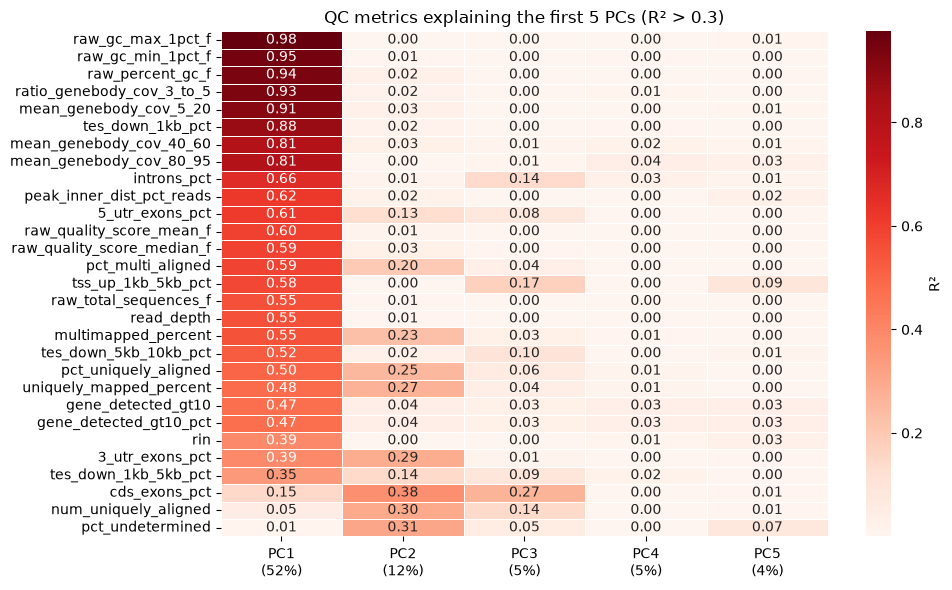

In [17]:
# Which QC metrics explain the main axes of variation
# R² (squared Pearson correlation) between PC1–PC5 and every numeric QC metric
pcs = ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
pca_5 = PCA(n_components=5, random_state=SEED)
pca_df_5 = pd.DataFrame(pca_5.fit_transform(scaled_deseq_counts),
                        columns=pcs, index=log2_deseq_empirical.columns)

# All QC metrics as numbers; drop empty and constant columns
qc_num = qc_df.loc[pca_df_5.index].apply(pd.to_numeric, errors='coerce').dropna(axis=1, how='all')
qc_num = qc_num.loc[:, qc_num.std() > 0]

r2_matrix_all = pca_df_5.join(qc_num).corr().loc[pcs, qc_num.columns] ** 2

# Keep metrics with R² > 0.3 on at least one PC; drop redundant derivative metrics
threshold = 0.3
strong = r2_matrix_all.loc[:, r2_matrix_all.max() > threshold]
clean_cols = [c for c in strong.columns
              if not ('trimmed' in c or 'auc' in c or c.endswith('_r'))]
filtered_r2_matrix_t = strong[clean_cols].T.sort_values('PC1', ascending=False)

print(f"{len(clean_cols)} of {qc_num.shape[1]} QC metrics have R² > {threshold} with at least one PC")

plt.figure(figsize=(10, 6))
sns.heatmap(filtered_r2_matrix_t, annot=True, fmt='.2f', cmap='Reds',
            cbar_kws={'label': 'R²'}, linewidths=0.5)
ev = pca_5.explained_variance_ratio_ * 100
plt.xticks(np.arange(5) + 0.5, [f"{pc}\n({v:.0f}%)" for pc, v in zip(pcs, ev)], rotation=0)
plt.title(f"QC metrics explaining the first 5 PCs (R² > {threshold})")
plt.tight_layout()
plt.savefig(FIG_DIR / "15_qc_r2_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:** 29 of 82 QC metrics have R² > 0.3 with at least one PC, almost all of them with PC1. The strongest associations are not with sequencing depth but with:
- GC content (R² = 0.94–0.98 for mean, maximum and minimum GC)
- Gene-body coverage: the 3′/5′ coverage ratio (R² = 0.93) and the coverage along the gene body (R² = 0.81–0.91), which reflect RNA degradation or library-preparation bias

Read depth (R² = 0.55), mapping rate (0.48) and RIN (0.39) are associated too, but more weakly. PC2–PC5 show no strong association with any QC metric (all R² < 0.4), so they are more likely to carry biological signal.

### 5.6 Redundancy between QC metrics
Many of the QC metrics may measure the same underlying technical property. To check this, we cluster the retained metrics by their correlation with each other.

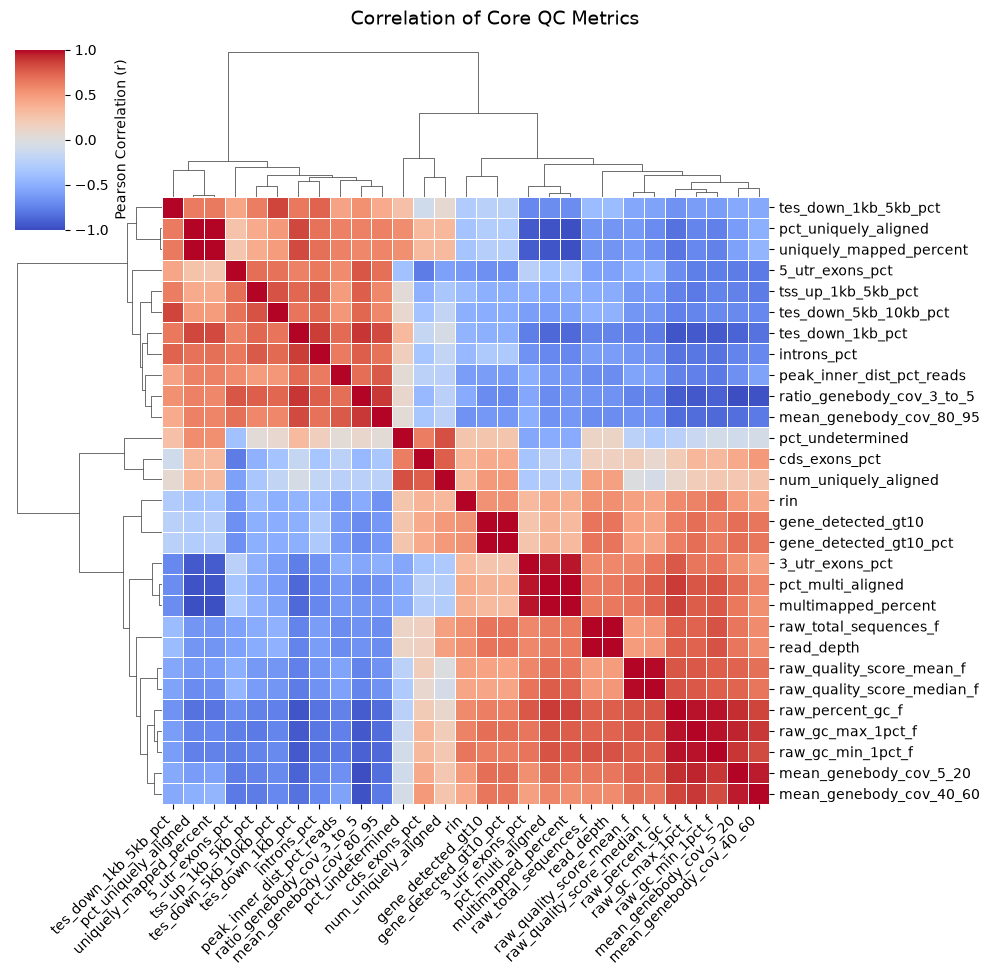

In [18]:
# Take the QC metrics retained in the R² heatmap above
clean_cols = filtered_r2_matrix_t.index.tolist()

# Extract these specific columns from the original QC dataframe
qc_clean_df = qc_df[clean_cols].copy()

# Ensure all columns are purely numeric
for col in clean_cols:
    qc_clean_df[col] = pd.to_numeric(qc_clean_df[col], errors='coerce')

# Calculate the Pearson correlation matrix
qc_corr_clean = qc_clean_df.corr(method='pearson')

# Generate the cleaned clustermap
g = sns.clustermap(
    qc_corr_clean,
    annot=False,
    cmap='coolwarm',
    vmin=-1, vmax=1,
    figsize=(10, 10),
    linewidths=0.5,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)

# Rotate x-axis labels for readability
plt.setp(g.ax_heatmap.get_xticklabels(), rotation=45, ha='right')

g.fig.suptitle("Correlation of Core QC Metrics", y=1.02, fontsize=14)
g.savefig(FIG_DIR / "16_qc_correlation_clustermap.png", dpi=300, bbox_inches='tight')
plt.show()

## 6. Correcting the technical batch effect
Section 5 identified PC1 as a technical batch effect, associated with GC content, gene-body coverage, mapping rate and sequencing depth. That analysis was primarily exploratory. Because the PCA settings differed between plots, and the regressions did not protect the biological signal. Here we test the correction formally through 4 steps:

1. **Fair comparison (Section 6.2):** identical PCA settings (VST, centred, the same 500 most variable genes) on (A) uncorrected data, (B) depth removed, (C) depth + RIN + mapping rate removed, (D) the 3′/5′ gene-body coverage ratio removed (a measure of RNA degradation). Covariates are removed *group-protected*: the biological factors are included in the model and only the covariate term is subtracted, comparable to `limma::removeBatchEffect` with a design matrix.
2. **Quantify (Section 6.3):** adjusted R² of each PC against biological, metadata, assay and QC variables.
3. **Name the cluster and check confounding (Section 6.4):** label the two clusters explicitly, test whether they relate to the experimental groups, and compare their QC values.
4. **Evaluate the corrections (Section 6.5):** does the cluster dissolve, is the biological signal kept, do new outliers appear?

### 6.1 Setup
We collect every variable we want to test (biological factors, other study-design variables, sequencing setup and QC metrics) into one table, `meta`, in the same sample order as the VST data. The helper functions below are used throughout this section:

- `design_matrix`: converts variables into a regression matrix (0/1 columns for categories, centred values for numbers).
- `adj_r2`: measures how much of a PC is explained by a variable, corrected for the number of parameters.
- `remove_covariates`: removes technical covariates from the expression data while protecting the biological factors. For each gene we fit *expression ~ biology + covariates* and subtract only the covariate part.
- `run_pca`: PCA with fixed settings and a fixed gene set, so corrected versions of the data can be compared fairly.

**One table with all sample variables**

In [19]:
# Variable groups used throughout ther rest of this Section 6
GROUP         = 'Factor Value[Spaceflight]'                                         # main experimental factor
BIO_FACTORS   = ['Factor Value[Spaceflight]', 'Factor Value[Dissection Condition]']   # biology: protected during correction
META_FACTORS  = ['Factor Value[Duration]', 'Factor Value[Euthanasia Location]']       # other study-design variables
ASSAY_FACTORS = ['Parameter Value[sequencing instrument]', 'Parameter Value[Spike-in Mix Number]']  # sequencing setup
QC_COVS       = ['log10_read_depth', 'rin', 'uniquely_mapped_percent']               # technical covariates to remove
EXTRA_QC      = ['gene_detected_gt10_pct', 'ratio_genebody_cov_3_to_5', 'rrna_contamination',
                 'introns_pct', 'raw_percent_duplicates_f']                          # extra QC, only for diagnostics

# Assay file --> sequencing details per sample (instrument, spike-in mix, etc.)
assay_df = pd.read_csv(DATA_DIR / "a_OSD-245_transcription-profiling_rna-sequencing-(rna-seq)_Illumina NovaSeq 6000.txt",
                       sep='\t').set_index('Sample Name')

# Combine metadata, assay info and QC metrics into one table, in the same sample order as the VST data
samples = vst_df.index
meta = (metadata_df.loc[samples, BIO_FACTORS + META_FACTORS]
        .join(assay_df[ASSAY_FACTORS])
        .join(qc_df[['read_depth', 'rin', 'uniquely_mapped_percent'] + EXTRA_QC].apply(pd.to_numeric, errors='coerce')))
meta['log10_read_depth'] = np.log10(meta['read_depth'])
meta['Replicate'] = samples.str.extract(r'_Rep(\d+)_', expand=False).astype(int).values   # e.g. "_Rep9_" -> 9

# Store factors as text, so they are treated as categories and not as numbers
CATEGORICAL = BIO_FACTORS + META_FACTORS + ASSAY_FACTORS + ['Replicate']
meta[CATEGORICAL] = meta[CATEGORICAL].astype(str)

# Safety checks --> same sample order as the expression data, and no missing QC values
assert meta.index.equals(vst_df.index), "sample order mismatch"
assert meta[QC_COVS + EXTRA_QC].notna().all().all(), meta[QC_COVS + EXTRA_QC].isna().sum()
meta.head()

,Factor Value[Spaceflight],Factor Value[Dissection Condition],Factor Value[Duration],Factor Value[Euthanasia Location],Parameter Value[sequencing instrument],Parameter Value[Spike-in Mix Number],read_depth,rin,uniquely_mapped_percent,gene_detected_gt10_pct,ratio_genebody_cov_3_to_5,rrna_contamination,introns_pct,raw_percent_duplicates_f,log10_read_depth,Replicate
Mmus_C57-6T_LVR_BSL_LAR_Rep1_B2,Basal Control,Upon euthanasia,0,On Earth,Illumina NovaSeq 6000,Mix 1,98104565,9.4,58.59,27.945651,1.776984,0.47,4.304281,86.079078,7.991689,1
Mmus_C57-6T_LVR_BSL_LAR_Rep2_B4,Basal Control,Upon euthanasia,0,On Earth,Illumina NovaSeq 6000,Mix 1,128795399,9.7,59.66,28.933655,1.614278,2.40,3.993517,86.708843,8.109900,2
Mmus_C57-6T_LVR_BSL_LAR_Rep3_B5,Basal Control,Upon euthanasia,0,On Earth,Illumina NovaSeq 6000,Mix 1,115445332,7.8,39.08,27.123772,1.686577,2.08,3.823464,90.771105,8.062376,3
Mmus_C57-6T_LVR_BSL_LAR_Rep4_B10,Basal Control,Upon euthanasia,0,On Earth,Illumina NovaSeq 6000,Mix 1,112909560,8.6,48.54,28.192215,1.732526,0.95,4.169279,87.762824,8.052731,4
Mmus_C57-6T_LVR_BSL_LAR_Rep5_B6,Basal Control,Upon euthanasia,0,On Earth,Illumina NovaSeq 6000,Mix 1,110673114,9.4,62.34,28.704578,1.585199,1.11,4.616317,84.780224,8.044042,5


**Helper functions**

In [20]:
def design_matrix(df, cols):
    """Turn the chosen variables into a numeric matrix for linear regression.
    Categorical variables become 0/1 columns (one level dropped as reference),
    numeric variables are centred, and a column of ones is added as intercept."""
    parts = [np.ones((len(df), 1))]
    for c in cols:
        if pd.api.types.is_numeric_dtype(df[c]):
            parts.append((df[c] - df[c].mean()).to_numpy(float)[:, None])
        else:
            parts.append(pd.get_dummies(df[c], drop_first=True).to_numpy(float))
    return np.hstack(parts)


def adj_r2(y, df, cols):
    """How much of y (e.g. one PC) is explained by the variables in cols.
    Adjusted R² corrects for the number of parameters, so a factor with many levels
    is not unfairly favoured over a single numeric covariate."""
    X = design_matrix(df, cols)
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r2 = 1 - np.sum((y - X @ beta) ** 2) / np.sum((y - y.mean()) ** 2)
    n, p = X.shape
    return 1 - (1 - r2) * (n - 1) / (n - p)


def remove_covariates(expr, df, covariates, protect=BIO_FACTORS):
    """Group-protected removal of technical covariates (same idea as limma::removeBatchEffect).
    For every gene, fit: expression ~ biology + technical covariates.
    Then subtract ONLY the technical part, so the biological signal stays in the data."""
    X_bio = design_matrix(df, protect)
    C = np.column_stack([(df[c] - df[c].mean()).to_numpy(float) for c in covariates])
    B, *_ = np.linalg.lstsq(np.hstack([X_bio, C]), expr.to_numpy(), rcond=None)
    corrected = expr.to_numpy() - C @ B[-C.shape[1]:, :]          # last rows of B = covariate effects
    return pd.DataFrame(corrected, index=expr.index, columns=expr.columns)


def run_pca(expr, genes, n=5):
    """PCA on a fixed set of genes (centred, not scaled), so different corrected
    versions of the data can be compared with identical settings."""
    X = expr[genes] - expr[genes].mean(axis=0)
    p = PCA(n_components=n, random_state=SEED).fit(X)
    scores = pd.DataFrame(p.transform(X), index=expr.index, columns=[f'PC{i+1}' for i in range(n)])
    return scores, p

### 6.2 Covariate removal: four versions compared
We compare four versions of the VST data: (A) uncorrected, (B) sequencing depth removed, (C) depth, RIN and mapping rate removed, and (D) the 3′/5′ gene-body coverage ratio removed. The 3′/5′ ratio measures how evenly reads cover a gene from start to end; a high ratio indicates RNA degradation or 3′ bias in library preparation. All covariates are removed group-protected. To keep the comparison fair, every version uses the same 500 most variable genes, selected once on the uncorrected data, and identical PCA settings.

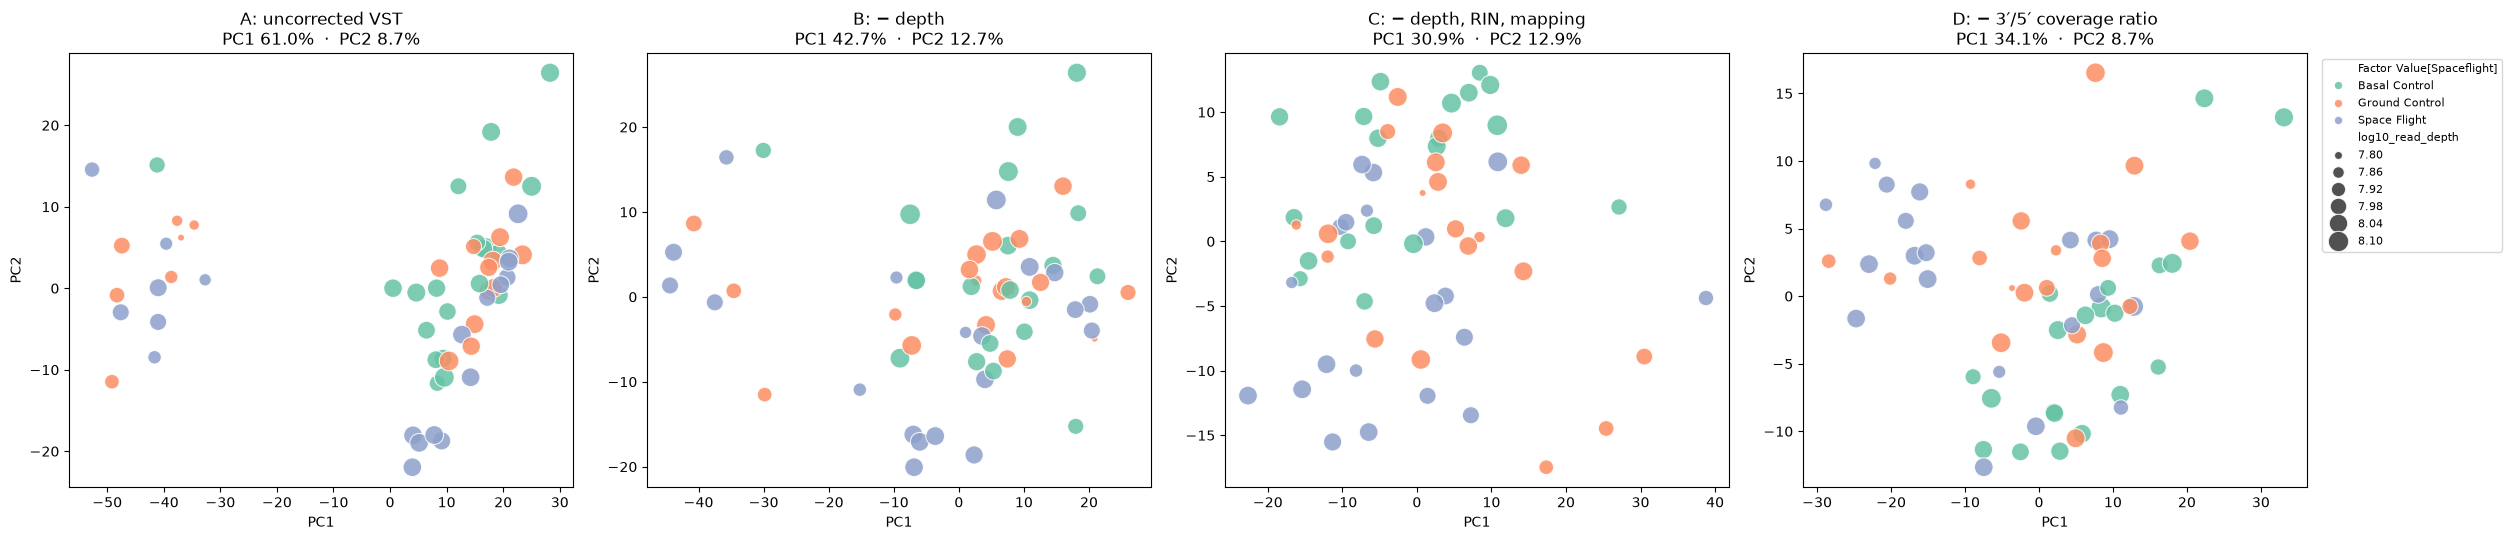

In [21]:
top_genes = vst_df.var(axis=0).nlargest(500).index

# Four versions of the VST data: uncorrected, and three different technical corrections (biology protected)
versions = {
    'A: uncorrected VST':        vst_df,
    'B: − depth':                remove_covariates(vst_df, meta, ['log10_read_depth']),
    'C: − depth, RIN, mapping':  remove_covariates(vst_df, meta, QC_COVS),
    'D: − 3′/5′ coverage ratio': remove_covariates(vst_df, meta, ['ratio_genebody_cov_3_to_5']),
}

# Same PCA settings for every version
pca_res = {name: run_pca(m, top_genes) for name, m in versions.items()}

# One panel per version: colour = experimental group, point size = sequencing depth
fig, axes = plt.subplots(1, len(pca_res), figsize=(6.3 * len(pca_res), 5.5))
for ax, (name, (scores, p)) in zip(axes, pca_res.items()):
    sns.scatterplot(data=scores.join(meta), x='PC1', y='PC2', hue=GROUP, size='log10_read_depth',
                    sizes=(25, 220), palette='Set2', alpha=0.85, ax=ax, legend=(ax is axes[-1]))
    ev = p.explained_variance_ratio_ * 100
    ax.set_title(f"{name}\nPC1 {ev[0]:.1f}%  ·  PC2 {ev[1]:.1f}%")
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "17_pca_covariate_corrections.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:** all three corrections weaken the PC1 split compared with the uncorrected data (A). Removing depth alone (B) still leaves a separate group of samples. Removing depth, RIN and mapping rate (C), or only the 3′/5′ coverage ratio (D), merges the samples into one cloud.

The explained-variance percentages are relative to each version's own total variance, so they cannot be compared directly between panels.

**Next step:** before judging which correction is best, we check which variables explain each PC in the uncorrected data, including biological and assay variables that Section 5 did not test.

### 6.3 What explains each PC?
Section 5.5 related the PCs to QC metrics only. Here we test a broader set of variables against the first five PCs of the uncorrected data: biological factors, other study-design variables (duration, euthanasia location), sequencing setup (instrument, spike-in mix), replicate number and the main QC metrics. We use adjusted R², which corrects for the number of parameters, so a factor with several levels is not unfairly favoured over a single numeric covariate.

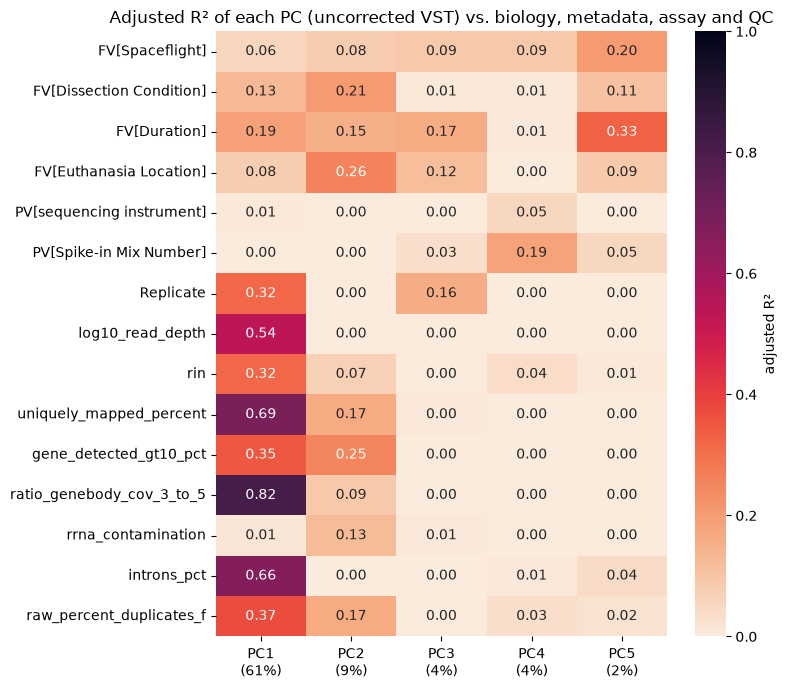

In [22]:
# PCA scores of the uncorrected data (version A from 6.2)
scores_A, pca_A = pca_res['A: uncorrected VST']

# For every PC, test how much each variable explains (adjusted R², negative values set to 0)
test_vars = BIO_FACTORS + META_FACTORS + ASSAY_FACTORS + ['Replicate'] + QC_COVS + EXTRA_QC
r2_table = pd.DataFrame({pc: [adj_r2(scores_A[pc].to_numpy(), meta, [v]) for v in test_vars]
                         for pc in scores_A.columns}, index=test_vars).clip(lower=0)

# Shorter labels for the heatmap: "Factor Value" -> "FV", "Parameter Value" -> "PV", and % variance per PC
r2_table.index = [v.replace('Factor Value', 'FV').replace('Parameter Value', 'PV') for v in r2_table.index]
r2_table.columns = [f"{pc}\n({ev:.0f}%)" for pc, ev in zip(scores_A.columns, pca_A.explained_variance_ratio_ * 100)]

plt.figure(figsize=(8, 7))
sns.heatmap(r2_table, annot=True, fmt='.2f', cmap='rocket_r', vmin=0, vmax=1, cbar_kws={'label': 'adjusted R²'})
plt.title("Adjusted R² of each PC (uncorrected VST) vs. biology, metadata, assay and QC")
plt.tight_layout()
plt.savefig(FIG_DIR / "18_pc_adjusted_r2.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- PC1 (61%) is explained by technical variables: the 3′/5′ coverage ratio (adjusted R² = 0.82), mapping rate (0.69), intronic reads (0.66) and depth (0.54). The biological factors explain little of it (Spaceflight 0.06).
- The sequencing instrument (0.01) and spike-in mix (0.00) do not explain PC1. The batch is therefore not a sequencing run. It more likely arose earlier, during sample handling or library preparation.
- Replicate number explains 0.32 of PC1. This might suggest that higher-numbered replicates were processed together.
- Biological signal appears only on smaller PCs. Duration (0.33) and Spaceflight (0.20) are most visible on PC5, and euthanasia location (0.26) on PC2. The biology is real but much smaller than the technical effect.

**Next step:** before correcting, we check whether the technical covariates are confounded with the experimental groups. If they are, correcting for them could also remove part of the spaceflight effect.

### 6.4 Technical covariates confounded with the design check
Group-protected correction only works well if the technical covariates are not strongly tied to the experimental groups. If, for example, all Space Flight samples had low RIN, removing RIN would also remove part of the spaceflight effect. We test this in two ways: first, whether each QC metric differs between Basal Control, Ground Control and Space Flight (Kruskal–Wallis test, which makes no normality assumption); second, how the batch cluster itself is distributed over the groups.

In [23]:
# Do the QC metrics differ between the experimental groups? (Kruskal-Wallis test + median per group)
qc_vars = QC_COVS + EXTRA_QC

kw = pd.DataFrame({
    'Kruskal-Wallis p (by Spaceflight group)': [stats.kruskal(*[g[v] for _, g in meta.groupby(GROUP)]).pvalue
                                                 for v in qc_vars],
    'median Basal':  [meta.loc[meta[GROUP] == 'Basal Control', v].median() for v in qc_vars],
    'median Ground': [meta.loc[meta[GROUP] == 'Ground Control', v].median() for v in qc_vars],
    'median Flight': [meta.loc[meta[GROUP] == 'Space Flight', v].median() for v in qc_vars],
}, index=qc_vars)

kw.to_csv(TABLE_DIR / "qc_by_group_kruskal.csv")
display(kw.round(4))

,Kruskal-Wallis p (by Spaceflight group),median Basal,median Ground,median Flight
log10_read_depth,0.4197,8.0379,8.0355,8.0265
rin,0.7559,9.3000,9.3000,8.9500
uniquely_mapped_percent,0.1511,62.6600,62.0700,70.5100
gene_detected_gt10_pct,0.1099,28.6661,28.1240,28.8104
ratio_genebody_cov_3_to_5,0.2254,1.6754,1.6833,1.5922
rrna_contamination,0.5439,1.0650,0.8800,1.2850
introns_pct,0.0991,5.5169,4.8652,6.7884
raw_percent_duplicates_f,0.1219,83.0179,84.5824,81.6891


**Observation:** none of the QC metrics differs significantly between the three experimental groups (Kruskal–Wallis, all p > 0.09). Space Flight samples have a somewhat higher median mapping rate (70.5% vs about 62%) and slightly more intronic reads, but these differences are not significant. At the group level, the technical covariates are therefore not confounded with the design, and correcting for them should not remove the spaceflight effect.

To make the batch explicit, we label the two clusters with k-means (k = 2) on the first two PCs of the uncorrected data. We then test whether the cluster relates to biology (cross-tabulation against the biological factors) and whether it relates to technical quality (QC metrics compared between the clusters with a Mann–Whitney U test).

cluster
main cluster     44
minor cluster    15 

Factor Value[Spaceflight]   (chi² p = 0.0355)


Factor Value[Spaceflight],Basal Control,Ground Control,Space Flight
cluster,,,
main cluster,19,12,13
minor cluster,1,7,7


Factor Value[Dissection Condition]   (chi² p = 0.0858)


Factor Value[Dissection Condition],Carcass,Upon euthanasia
cluster,,
main cluster,19,25
minor cluster,11,4


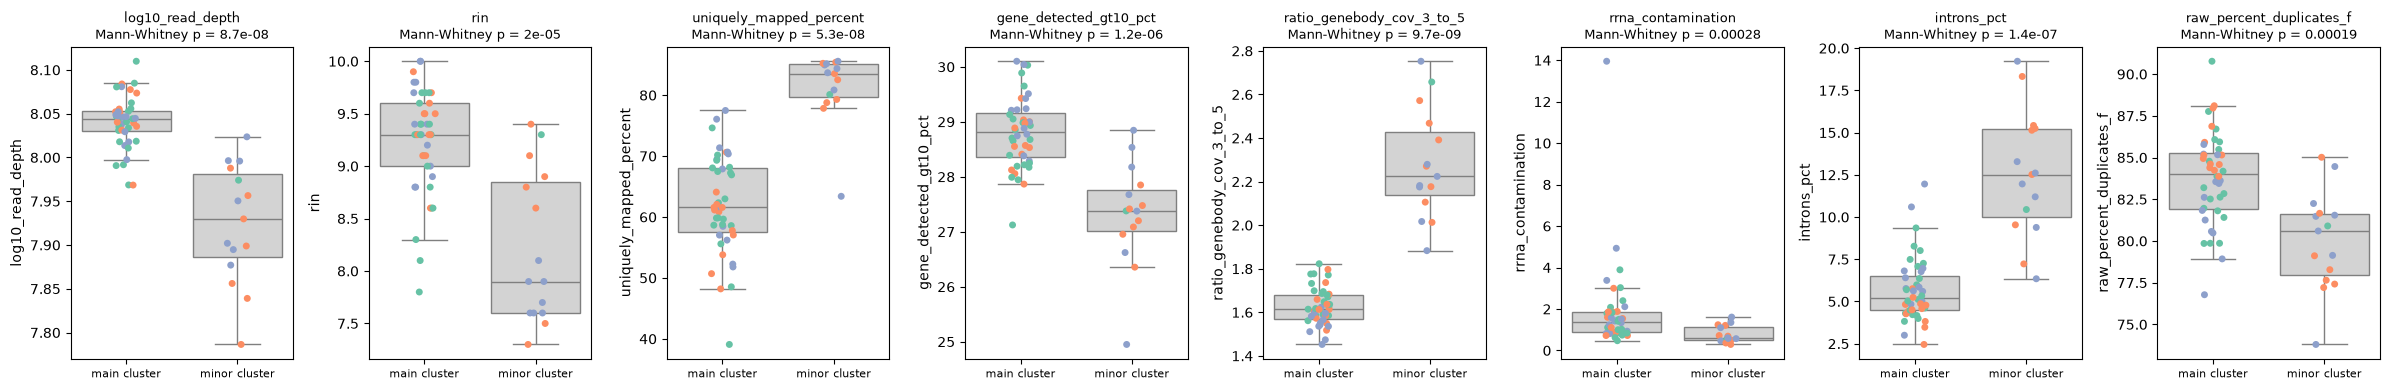

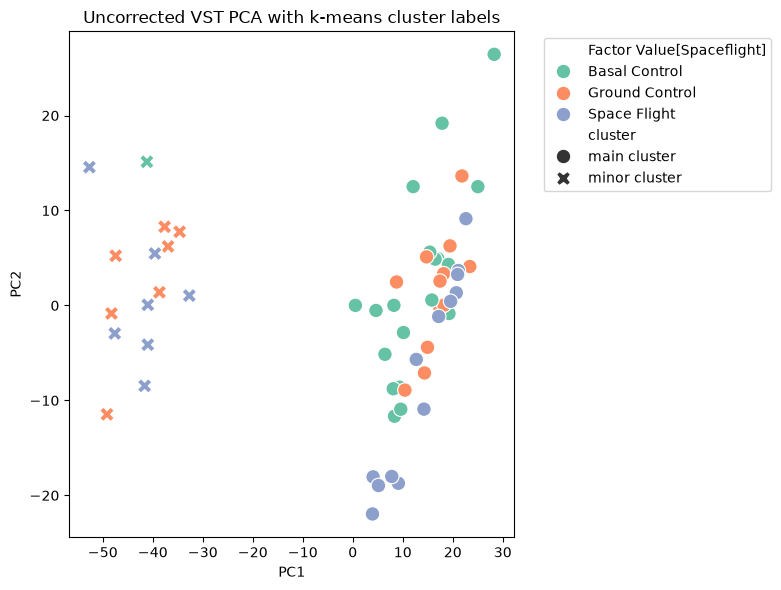

In [24]:
# Give the two clusters an explicit label: k-means (k=2) on PC1-PC2 of the uncorrected VST data
X_clu = scores_A[['PC1', 'PC2']]
km = KMeans(n_clusters=2, n_init=20, random_state=SEED).fit(X_clu)
labels = pd.Series(km.labels_, index=samples)
minor = labels.value_counts().idxmin()                               # the smaller cluster = the batch
meta['cluster'] = np.where(labels == minor, 'minor cluster', 'main cluster')
print(meta['cluster'].value_counts().to_string(), "\n")

# Is the cluster biological? Cross-tabulate it against the biological factors (chi-squared test)
for f in BIO_FACTORS:
    ct = pd.crosstab(meta['cluster'], meta[f])
    print(f"{f}   (chi² p = {stats.chi2_contingency(ct)[1]:.3g})")
    display(ct)

# Is the cluster technical? Compare QC metrics between the clusters (Mann-Whitney U test)
fig, axes = plt.subplots(1, len(qc_vars), figsize=(3 * len(qc_vars), 4))
for ax, v in zip(axes, qc_vars):
    sns.boxplot(data=meta, x='cluster', y=v, ax=ax, color='lightgrey', showfliers=False)
    sns.stripplot(data=meta, x='cluster', y=v, hue=GROUP, palette='Set2', ax=ax, size=5, legend=False)
    p = stats.mannwhitneyu(*[g[v] for _, g in meta.groupby('cluster')]).pvalue
    ax.set_title(f"{v}\nMann-Whitney p = {p:.2g}", fontsize=9)
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "19_qc_by_cluster.png", dpi=300, bbox_inches='tight')
plt.show()

# PCA with the cluster labels, to check that k-means found the PC1 split
plt.figure(figsize=(8, 6))
sns.scatterplot(data=scores_A.join(meta), x='PC1', y='PC2', hue=GROUP, style='cluster', s=110, palette='Set2')
plt.title("Uncorrected VST PCA with k-means cluster labels")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / "20_pca_kmeans_clusters.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:** the question here is whether the separate group of 15 samples is biological or technical.

- It is not a biological group. k-means labels 44 samples as the main cluster and 15 as the minor cluster. The minor cluster contains 1 Basal Control, 7 Ground Control and 7 Space Flight samples. A chi-squared test (which checks whether samples are spread over the clusters differently than expected by chance) gives p = 0.036, as there are almost no basal control group samples present. Furthermore, Space Flight and Ground Control are equally represented (7 vs 7), so the batch cannot create a false spaceflight effect in our main comparison.
- It is a technical group. The minor cluster differs from the main cluster on every QC metric (Mann–Whitney tests), most strongly in the 3′/5′ coverage ratio (p ≈ 1e-8) and the share of intronic reads (p ≈ 1e-7). Both point to more degraded RNA or a different library preparation.

**Conclusion:** the minor cluster is a technical batch of samples with poorer RNA quality. Because Flight and Ground samples are equally affected, it can be corrected for without biasing the spaceflight comparison.

**Next step:** we compare the four corrections from Section 6.2 to see which one removes this batch best while keeping the biological signal.

### 6.5 Which correction works best?
We score the four versions of the data from Section 6.2 on three questions:

1. **Is the batch gone?** The *silhouette score* measures how clearly the 15 batch samples (Section 6.4) still form a separate group: close to 1 means clearly separate, close to 0 means mixed in. Lower is better.
2. **Is the biology kept?** How much of the variation in the first five PCs is explained by Spaceflight and by Dissection condition. A good correction removes technical noise, so the biological share should stay the same or increase. Higher is better.
3. **Are there outliers?** The number of samples that lie far from the others in PCA space. Lower is better.

,"batch separation (silhouette, lower = better)",Spaceflight R² (higher = better),Dissection R² (higher = better),depth R² (should drop after correction),outlier samples (lower = better)
A: uncorrected VST,0.652,0.068,0.127,0.409,15.0
B: − depth,0.284,0.060,0.127,0.000,0.0
"C: − depth, RIN, mapping",0.149,0.094,0.115,0.006,0.0
D: − 3′/5′ coverage ratio,0.128,0.147,0.190,0.064,0.0


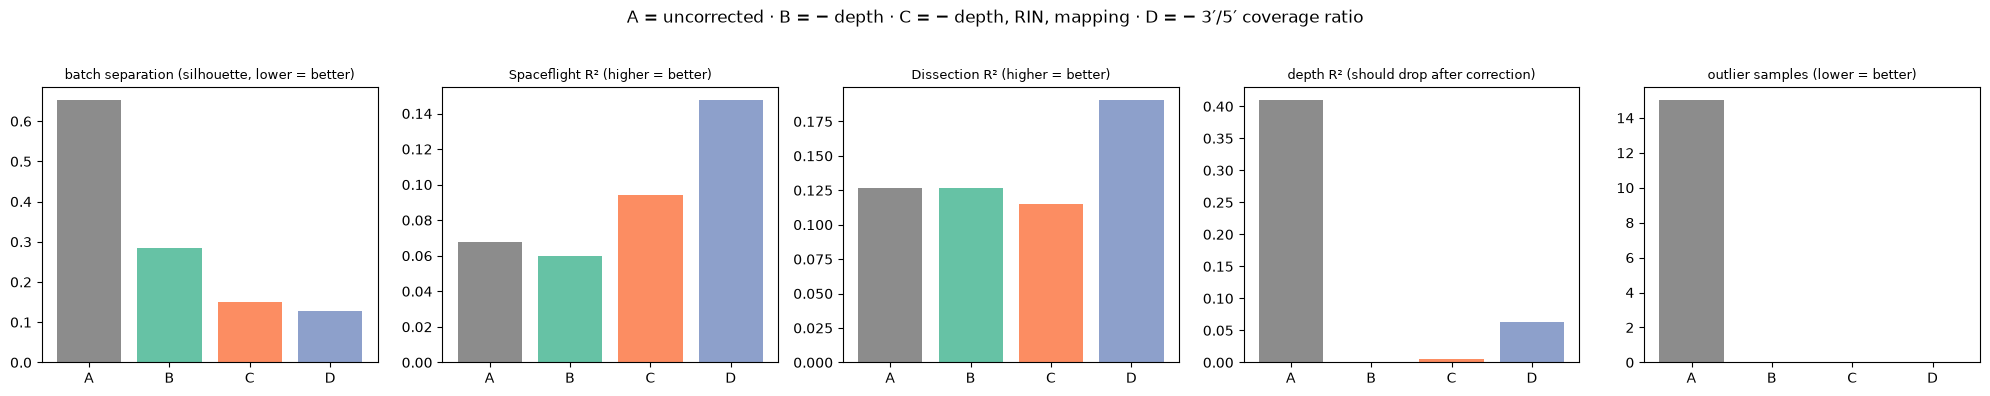

In [25]:
def weighted_r2(scores, p, var):
    """How much of the variation in the first 5 PCs is explained by `var`:
    the R² per PC, weighted by how much variance that PC carries."""
    w = p.explained_variance_
    r = np.array([max(adj_r2(scores[pc].to_numpy(), meta, [var]), 0) for pc in scores.columns])
    return float(np.sum(r * w) / np.sum(w))


def n_outliers(scores, thr=3.5):
    """Number of samples lying far from the rest on PC1-PC3 (robust z-score based on median and MAD)."""
    s = scores[['PC1', 'PC2', 'PC3']]
    rz = (s - s.median()) / (1.4826 * (s - s.median()).abs().median())
    return int((rz.abs() > thr).any(axis=1).sum())


# Score every version of the data from 6.2 on three questions: batch gone? biology kept? new outliers?
rows = {}
for name, (scores, p) in pca_res.items():
    rows[name] = {
        'batch separation (silhouette, lower = better)':  silhouette_score(scores, meta['cluster']),
        'Spaceflight R² (higher = better)':               weighted_r2(scores, p, GROUP),
        'Dissection R² (higher = better)':                weighted_r2(scores, p, 'Factor Value[Dissection Condition]'),
        'depth R² (should drop after correction)':        weighted_r2(scores, p, 'log10_read_depth'),
        'outlier samples (lower = better)':               n_outliers(scores),
    }
evaluation = pd.DataFrame(rows).T
evaluation.to_csv(TABLE_DIR / "correction_evaluation.csv")
display(evaluation.round(3))

# One bar chart per criterion
fig, axes = plt.subplots(1, evaluation.shape[1], figsize=(4 * evaluation.shape[1], 3.8))
for ax, col in zip(axes, evaluation.columns):
    ax.bar(range(len(evaluation)), evaluation[col], color=['#8c8c8c', '#66c2a5', '#fc8d62', '#8da0cb'])
    ax.set_xticks(range(len(evaluation)))
    ax.set_xticklabels([n.split(':')[0] for n in evaluation.index])     # 'A', 'B', 'C', 'D'
    ax.set_title(col, fontsize=9)
plt.suptitle("A = uncorrected · B = − depth · C = − depth, RIN, mapping · D = − 3′/5′ coverage ratio", y=1.03)
plt.tight_layout()
plt.savefig(FIG_DIR / "21_correction_evaluation.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:**

| Version | Batch separation ↓ | Spaceflight R² ↑ | Dissection R² ↑ | Outliers ↓ |
|---|---|---|---|---|
| A: uncorrected | 0.65 | 0.07 | 0.13 | 15 |
| B: − depth | 0.28 | 0.06 | 0.13 | 0 |
| C: − depth, RIN, mapping | 0.15 | 0.09 | 0.12 | 0 |
| D: − 3′/5′ coverage ratio | **0.13** | **0.15** | **0.19** | 0 |

Removing **only the 3′/5′ coverage ratio (D)** works best on every criterion: the batch largely disappears, and the spaceflight signal more than doubles compared with the uncorrected data. One covariate thus does better than three. The 15 "outliers" in the uncorrected data are the batch samples themselves; after any correction, none remain.

**Conclusion of Section 6:** the dominant structure in this dataset is a technical batch, most likely caused by differences in RNA degradation (high 3′/5′ coverage ratio, more intronic reads, lower RIN). It can be corrected without losing biological signal, and the 3′/5′ coverage ratio is the most effective single covariate.

**Next step:** with the technical variation understood, we quantify the biological effects (spaceflight, mission arm and their interaction) using ASCA.

## 7. ASCA+: how much variance does each experimental factor explain?
PCA shows the largest sources of variation, but it does not tell us how much of that variation belongs to each experimental factor. **ASCA** (ANOVA–simultaneous component analysis; Smilde et al., 2005) combines the two ideas. Like an ANOVA, it splits the expression data into separate matrices, one per effect, and then summarizes each matrix with a PCA, so we can see both *how large* each effect is and *which genes* drive it.

**Why ASCA+ instead of classical ASCA.** Classical ASCA estimates each effect from simple group means. That only works cleanly when every group has the same number of samples and the model contains only categorical factors. Our design is slightly unbalanced (Ground Control LAR has 9 samples instead of 10), and we also want to include numeric technical covariates. **ASCA+** (Thiel et al., 2017) solves both problems by estimating all effects together in one linear regression model (_a general linear model_):

1. **Design matrix.** Each effect gets its own block of columns. Factors are *sum-coded*: each level is compared with the overall mean instead of with one reference group, so the effects are as independent as possible and their sizes can be compared.
2. **One regression for all genes.** Expression = intercept + Spaceflight + Timepoint + Spaceflight × Timepoint + Technical + residual, fitted for all 13,078 genes at once by least squares.
3. **Effect matrices.** For each effect, its design columns × its regression coefficients give a matrix with that effect's contribution to every gene in every sample. The leftover is the residual matrix.
4. **Variance partitioning.** The sum of squares of each effect matrix, divided by the total sum of squares, gives the % of variance that effect explains. In an unbalanced design the effects are not perfectly independent, so the percentages do not sum to exactly 100%.
5. **PCA per effect.** A PCA of each effect matrix shows how the groups differ and which genes drive the difference (loadings). All samples of a group share the same point in an effect matrix, so we project the residuals onto the same components to show the spread of the individual samples around each group mean.

Our model contains:
- **Spaceflight** (Basal Control, Ground Control, Space Flight)
- **Timepoint / mission arm**: LAR (returned alive to Earth) vs ISS-T (dissected on orbit). These differ in more than time alone, so we interpret this factor as the mission arm.
- **Spaceflight × Timepoint**: does the spaceflight effect differ between the two arms?
- **Technical**: z-scored sequencing depth and RIN in the initial model. Based on the residual analysis (Section 7.1) and a comparison of covariate sets (Section 7.2), the 3′/5′ coverage ratio is added in the final model.

**Significance** is tested with a **Freedman–Lane permutation test** (Freedman & Lane, 1983) (5,000 permutations per effect). For each effect, the model is first fitted *without* that effect; the residuals of this reduced model are shuffled between samples and added back, and the effect is re-estimated. Repeating this gives the distribution of effect sizes expected if the effect did not exist. Unlike simply shuffling sample labels, this keeps the other effects (including the covariates) intact, which is why it is the appropriate test for models with covariates. The four tests are independent of each other, so they run in parallel (one process per effect, via `joblib`).

**Approach.** We first fit an initial model with depth and RIN, the two standard technical covariates that can be chosen before looking at the data. We then inspect what that model leaves unexplained (7.1), use this to choose the final set of technical covariates (7.2), interpret the biological effects in the final model (7.3), and finally check that the technical covariates are not confounded with the experimental design (7.4).

**Data and design factors.** The input is the VST matrix from Section 4.2, centred per gene so that ASCA models differences from each gene's mean. Each sample gets its Spaceflight group and mission arm. We also prepare four candidate technical covariates (log10 read depth, RIN, 3′/5′ coverage ratio, mapping rate). They are z-scored (mean 0, standard deviation 1) so they are on a comparable scale, which keeps the regression numerically stable. Not all of them end up in the model; which ones do is decided in Sections 7.1–7.2. The cross-table confirms the design: 10 samples per group, except Ground Control LAR (9).

In [26]:
# Input: VST data (samples x genes), centred per gene
Y = vst_df.copy()
Yc = Y.values - Y.values.mean(axis=0)
ss_total = (Yc ** 2).sum()                                   # total variance, used to express effects as %

# Experimental factors per sample: Spaceflight group and mission arm (LAR vs ISS-T, called "Timepoint")
clean = lambda s: re.sub(r'\W+', '', str(s))
zscore = lambda s: (s - s.mean()) / s.std()
asca_meta = pd.DataFrame({
    'Spaceflight': metadata_df.loc[Y.index, 'Factor Value[Spaceflight]'].map(clean),
    'Timepoint':   Y.index.str.extract(r'_(LAR|ISS-T)_', expand=False).str.replace('-', ''),
}, index=Y.index)
asca_meta['Group'] = asca_meta['Spaceflight'] + '_' + asca_meta['Timepoint']

# Candidate technical covariates, z-scored so they are on the same scale
qc_sub = qc_df.loc[Y.index, ['read_depth', 'rin', 'ratio_genebody_cov_3_to_5', 'uniquely_mapped_percent']].astype(float)
asca_meta['logDepth_z'] = zscore(np.log10(qc_sub['read_depth']))
asca_meta['RIN_z']      = zscore(qc_sub['rin'])
asca_meta['Ratio35_z']  = zscore(qc_sub['ratio_genebody_cov_3_to_5'])
asca_meta['Mapping_z']  = zscore(qc_sub['uniquely_mapped_percent'])
assert asca_meta.notna().all().all(), "missing metadata/QC for some samples"

print(pd.crosstab(asca_meta['Spaceflight'], asca_meta['Timepoint']))

Timepoint      ISST  LAR
Spaceflight             
BasalControl     10   10
GroundControl    10    9
SpaceFlight      10   10


**ASCA+ functions.** The analysis is written as small functions, so the same model can be fitted with different sets of technical covariates without duplicating code:
- `sum_code`: sum (deviation) coding of a factor
- `build_design`: builds the design matrix with one block of columns per effect
- `effect_matrices`: fits the regression for all genes at once and returns one matrix per effect plus the residual
- `freedman_lane`: the permutation test for one effect
- `run_asca`: combines these steps, computes the % variance per effect and runs the four permutation tests in parallel

In [27]:
def sum_code(f):
    """Sum (deviation) coding: each level is compared with the grand mean instead of with a reference level,
    so the effect matrices are (nearly) independent and their variances can be compared."""
    levels = sorted(f.unique())
    cols = {f'{f.name}[{l}]': np.where(f == l, 1.0, np.where(f == levels[-1], -1.0, 0.0))
            for l in levels[:-1]}
    return pd.DataFrame(cols, index=f.index)

def build_design(m, tech_cols, tech_label):
    """Design matrix with one block of columns per effect: Spaceflight, Timepoint, their interaction, technical."""
    SF = sum_code(m['Spaceflight'])
    T  = sum_code(m['Timepoint'])
    SFxT = pd.DataFrame({f'{a}:{b}': SF[a] * T[b] for a in SF for b in T}, index=m.index)
    blocks = {'Spaceflight': SF, 'Timepoint': T, 'Spaceflight x Timepoint': SFxT, tech_label: m[tech_cols]}
    X = pd.concat([pd.Series(1.0, index=m.index, name='Intercept')] + list(blocks.values()), axis=1)
    cols = {k: [X.columns.get_loc(c) for c in v.columns] for k, v in blocks.items()}
    return X.values, cols

def effect_matrices(X, cols, Yc):
    """Fit all genes at once by least squares; each effect matrix = that effect's design columns x its coefficients."""
    B = np.linalg.lstsq(X, Yc, rcond=None)[0]
    M = {k: X[:, c] @ B[c, :] for k, c in cols.items()}
    M['Residual'] = Yc - X @ B
    return M

def freedman_lane(X, cols, Yc, effect, n_perm=5000, seed=0):
    """Permutation test for one effect: fit the model without the effect, shuffle its residuals between samples,
    refit the full model and record the effect size. p = share of shuffles with an effect at least as large."""
    rng = np.random.default_rng(seed)
    P = np.linalg.pinv(X)
    c_eff = cols[effect]
    keep = [0] + [i for k, c in cols.items() if k != effect for i in c]     # intercept + all other effects
    Xr = X[:, keep]
    fitted_r = Xr @ np.linalg.lstsq(Xr, Yc, rcond=None)[0]
    resid_r = Yc - fitted_r
    obs = ((X[:, c_eff] @ (P @ Yc)[c_eff]) ** 2).sum()
    null = np.empty(n_perm)
    for i in range(n_perm):
        B = P @ (fitted_r + resid_r[rng.permutation(len(Yc))])
        null[i] = ((X[:, c_eff] @ B[c_eff]) ** 2).sum()
    return (1 + (null >= obs).sum()) / (1 + n_perm)

def run_asca(m, tech_cols, tech_label, n_perm=5000):
    """Fit the ASCA+ model, compute % variance per effect, and run the permutation tests in parallel (one per effect)."""
    X, cols = build_design(m, tech_cols, tech_label)
    M = effect_matrices(X, cols, Yc)
    var_expl = pd.Series({k: (v ** 2).sum() / ss_total * 100 for k, v in M.items()})
    p = Parallel(n_jobs=4)(delayed(freedman_lane)(X, cols, Yc, eff, n_perm, SEED + k) for k, eff in enumerate(cols))
    pvals = pd.Series(dict(zip(cols, p)))
    table = pd.DataFrame({'% variance': var_expl.round(2), 'p (permutation)': pvals})
    return X, cols, M, var_expl, pvals, table

**Initial model (depth + RIN)**, We first fit the model with the two standard technical covariates.

In [28]:
# Initial ASCA+ model: biological effects + sequencing depth and RIN as technical covariates
X, cols, M, var_expl, pvals, asca_table = run_asca(asca_meta, ['logDepth_z', 'RIN_z'], 'Technical (depth + RIN)')
asca_table.to_csv(TABLE_DIR / "asca_variance_table.csv")
display(asca_table)

,% variance,p (permutation)
Residual,45.72,NaN
Spaceflight,6.01,0.000600
Spaceflight x Timepoint,3.66,0.025995
Technical (depth + RIN),34.65,0.000200
Timepoint,6.89,0.000200


**Observation (initial model):**
All three biological effects (Spaceflight, Timepoint, Spaceflight x Timepoint) are significant, but together they explain only about 17% of the variance, half of what the technical covariates explain. The residual is large: almost half of the variance is not explained by the model. To understand why, we look at what the residual contains.

### 7.1 What is left in the residuals?
After ASCA, 45.7% of the variance remains unexplained. This residual contains natural variation between individual mice and noise, but it may also contain technical variation that sequencing depth and RIN do not capture. Section 6 showed that the 3′/5′ coverage ratio describes the batch better than depth does. We therefore run a PCA on the residual matrix, check whether the batch cluster is still visible, and test how much the residual shrinks when the 3′/5′ ratio is added to the technical block.

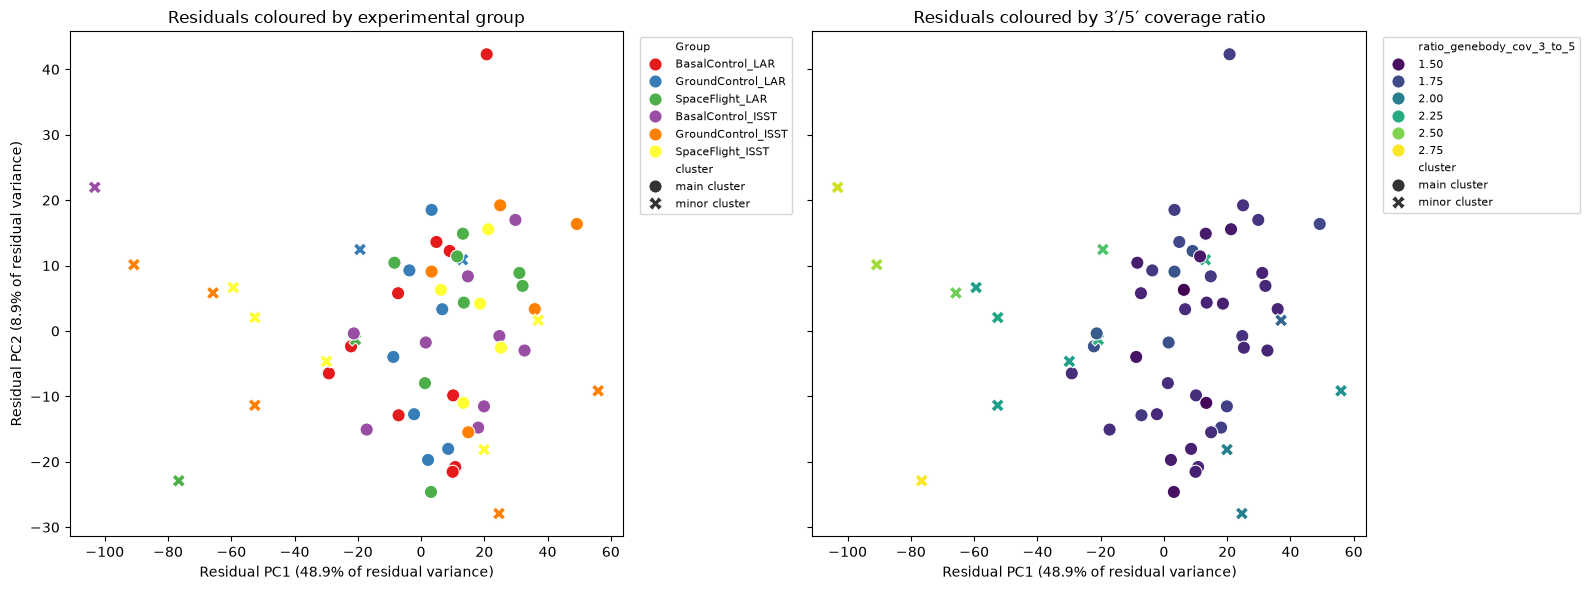

Adjusted R² of residual PCs with the 3′/5′ coverage ratio:
PC1    0.47
PC2   -0.01
PC3   -0.02
PC4   -0.02
PC5   -0.02

Residual variance: 45.7% (depth + RIN) -> 24.8% (depth + RIN + 3′/5′ ratio)


In [29]:
# PCA of the ASCA residuals: what variation is left after removing all modelled effects?
res_pca = PCA(n_components=5, random_state=SEED).fit(M['Residual'])
res_pcs = res_pca.transform(M['Residual'])
res_scores = pd.DataFrame(res_pcs[:, :2], columns=['PC1', 'PC2'], index=Y.index)
res_scores = res_scores.join(asca_meta[['Group']]).join(meta[['cluster', 'ratio_genebody_cov_3_to_5']])

ev = res_pca.explained_variance_ratio_ * 100
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
sns.scatterplot(data=res_scores, x='PC1', y='PC2', hue='Group', style='cluster',
                s=90, palette='Set1', ax=axes[0])
axes[0].set_title("Residuals coloured by experimental group")
sns.scatterplot(data=res_scores, x='PC1', y='PC2', hue='ratio_genebody_cov_3_to_5', style='cluster',
                s=90, palette='viridis', ax=axes[1])
axes[1].set_title("Residuals coloured by 3′/5′ coverage ratio")
for ax in axes:
    ax.set_xlabel(f"Residual PC1 ({ev[0]:.1f}% of residual variance)")
    ax.set_ylabel(f"Residual PC2 ({ev[1]:.1f}% of residual variance)")
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "24_asca_residual_pca.png", dpi=300, bbox_inches='tight')
plt.show()

# How much of each residual PC is still explained by the 3′/5′ coverage ratio?
r2_res = pd.Series({f"PC{i+1}": adj_r2(res_pcs[:, i], meta, ['ratio_genebody_cov_3_to_5']) for i in range(5)})
print("Adjusted R² of residual PCs with the 3′/5′ coverage ratio:")
print(r2_res.round(2).to_string())

# Refit the same model with the 3′/5′ ratio added to the technical block: how much does the residual shrink?
ratio_z = zscore(meta.loc[Y.index, 'ratio_genebody_cov_3_to_5'])
X_35 = np.column_stack([X, ratio_z])
resid_35 = Yc - X_35 @ np.linalg.lstsq(X_35, Yc, rcond=None)[0]
print(f"\nResidual variance: {var_expl['Residual']:.1f}% (depth + RIN) -> "
      f"{(resid_35 ** 2).sum() / ss_total * 100:.1f}% (depth + RIN + 3′/5′ ratio)")

**Observation:**
- The residual matrix still contains the batch effect. The largest residual component (PC1, 48.9% of the residual variance) separates the 15 minor-cluster samples, and these are the samples with the highest 3′/5′ coverage ratio (right panel). The 3′/5′ ratio explains 47% of this residual component (adjusted R² = 0.47), but none of the others.
- The experimental groups are mixed in the residual PCA (left panel), as expected after their effects have been removed.
- Adding the 3′/5′ coverage ratio to the technical block reduces the residual variance from **45.7% to 24.8%**. Nearly half of what the initial model leaves unexplained is therefore batch-related RNA degradation, not natural variation between mice.

**Decision:** a closer look at the residuals shows that the 3′/5′ coverage ratio accounts for a large part of the variance that depth and RIN leave unexplained. We therefore include it as an additional technical covariate in the design for the downstream analyses (final ASCA model below and differential expression in Section 8). We also test whether adding mapping rate improves the model further.


### 7.2 Choosing the technical covariates
Section 7.1 showed that the 3′/5′ coverage ratio explains much of the residual. Mapping rate was also strongly associated with the batch (Sections 5.5 and 6.3), so it is a second candidate. To decide which covariates to include, we compare three **nested** models, where each model contains the previous one plus one extra covariate:

1. depth + RIN
2. depth + RIN + 3′/5′ coverage ratio
3. depth + RIN + 3′/5′ coverage ratio + mapping rate

For each addition we ask two questions. **Does it lower the residual?** If so, it explains variance that was previously unexplained. **Does it change the biological effects?** A purely technical covariate should leave Spaceflight, Timepoint and their interaction unchanged. If a covariate shrinks them, it is partly a proxy for biology, and including it would remove real signal. A covariate is therefore only worth adding if it substantially lowers the residual *and* leaves the biological effects intact. With 59 samples, every extra covariate also costs statistical power. This comparison only fits the models; permutation tests follow for the final model only.

In [30]:
# Compare nested sets of technical covariates: residual variance and biological effects (% of total variance)
tech_sets = {
    'depth + RIN':                         ['logDepth_z', 'RIN_z'],
    'depth + RIN + 3′/5′ ratio':           ['logDepth_z', 'RIN_z', 'Ratio35_z'],
    'depth + RIN + 3′/5′ ratio + mapping': ['logDepth_z', 'RIN_z', 'Ratio35_z', 'Mapping_z'],
}
rows = {}
for name, tc in tech_sets.items():
    Xs, cs = build_design(asca_meta, tc, 'Technical')
    Ms = effect_matrices(Xs, cs, Yc)
    rows[name] = {k: (v ** 2).sum() / ss_total * 100 for k, v in Ms.items()}
cov_compare = pd.DataFrame(rows).T.round(2)
cov_compare.to_csv(TABLE_DIR / "asca_covariate_sets.csv")
display(cov_compare)

,Spaceflight,Timepoint,Spaceflight x Timepoint,Technical,Residual
depth + RIN,6.01,6.89,3.66,34.65,45.72
depth + RIN + 3′/5′ ratio,6.11,6.57,3.67,57.42,24.80
depth + RIN + 3′/5′ ratio + mapping,5.16,4.43,3.38,64.11,21.97


**Observation:**
- **Adding the 3′/5′ coverage ratio** lowers the residual from 45.7% to 24.8% (−20.9 percentage points), while the biological effects stay practically unchanged (Spaceflight 6.0 → 6.1%, Timepoint 6.9 → 6.6%, interaction 3.7 → 3.7%). It removes technical noise, not biology.
- **Additionally adding mapping rate** lowers the residual by only 2.8 more percentage points (to 22.0%), but reduces the biological effects: Timepoint drops by a third (6.6 → 4.4%) and Spaceflight from 6.1 to 5.2%. Mapping rate is therefore partly associated with the experimental design, and including it would remove real biological signal for little technical gain.

**Decision:** the final model uses **depth, RIN and the 3′/5′ coverage ratio** as technical covariates. Mapping rate is not included.

The technical block's share increases by more than the residual decreases (34.7% → 57.4% vs 45.7% → 24.8%). This is because the effects in an unbalanced design with correlated covariates are not perfectly independent, so the percentages do not add up to exactly 100%.

**Final model.** Based on this comparison, the final model uses depth, RIN and the 3′/5′ coverage ratio as technical covariates. We refit it with permutation tests and compare it with the initial model.

In [31]:
# Final ASCA+ model: the 3′/5′ coverage ratio is added to the technical block
TECH_FINAL = ['logDepth_z', 'RIN_z', 'Ratio35_z']
TECH_LABEL = 'Technical (depth + RIN + 3′/5′ ratio)'
X_final, cols_final, M_final, var_expl_final, pvals_final, asca_table_final = run_asca(asca_meta, TECH_FINAL, TECH_LABEL)
asca_table_final.to_csv(TABLE_DIR / "asca_variance_table_final.csv")

# Initial vs final model side by side (technical rows renamed so they line up)
same_label = lambda t: t.rename(index=lambda s: 'Technical' if s.startswith('Technical') else s)
asca_compare = pd.concat({'initial (depth + RIN)': same_label(asca_table),
                          'final (+ 3′/5′ ratio)': same_label(asca_table_final)}, axis=1)
asca_compare.to_csv(TABLE_DIR / "asca_initial_vs_final.csv")
display(asca_compare)

initial (depth + RIN)                  \
                                   % variance p (permutation)   
Residual                                45.72             NaN   
Spaceflight                              6.01        0.000600   
Spaceflight x Timepoint                  3.66        0.025995   
Technical                               34.65        0.000200   
Timepoint                                6.89        0.000200   

                        final (+ 3′/5′ ratio)                  
                                   % variance p (permutation)  
Residual                                24.80             NaN  
Spaceflight                              6.11          0.0002  
Spaceflight x Timepoint                  3.67          0.0002  
Technical                               57.42          0.0002  
Timepoint                                6.57          0.0002

**Observation Final Model:**
- The biological effects are practically the same size in both models (Spaceflight 6.0 → 6.1%, Timepoint 6.9 → 6.6%, interaction 3.7 → 3.7%). Adding the 3′/5′ coverage ratio therefore does not change *what* the biology looks like.
- The residual drops from 45.7% to 24.8%. Because each effect is now tested against much less unexplained noise, the permutation tests become more sensitive: **all three biological effects reach the smallest possible p-value** (p < 0.001, the minimum with 5,000 permutations). The difference is clearest for the **Spaceflight × Timepoint interaction**, which goes from p = 0.026 to p < 0.001 at the same effect size.
- The technical block now explains 57.4% of the variance, more than three times the three biological effects combined (16.4%).

**Conclusion:** removing the RNA-degradation signal sharpens the biological picture without changing it. We use this final model for the interpretation of the biological effects below, and the same technical covariates in the differential expression analysis.

### 7.3 Biological effects in the final model
For each biological effect, a PCA of its effect matrix shows how the groups differ. Black crosses are the group means; the coloured dots are individual samples (group mean + residual projected onto the same components). The bar plot shows how the total variance is divided over all effects.

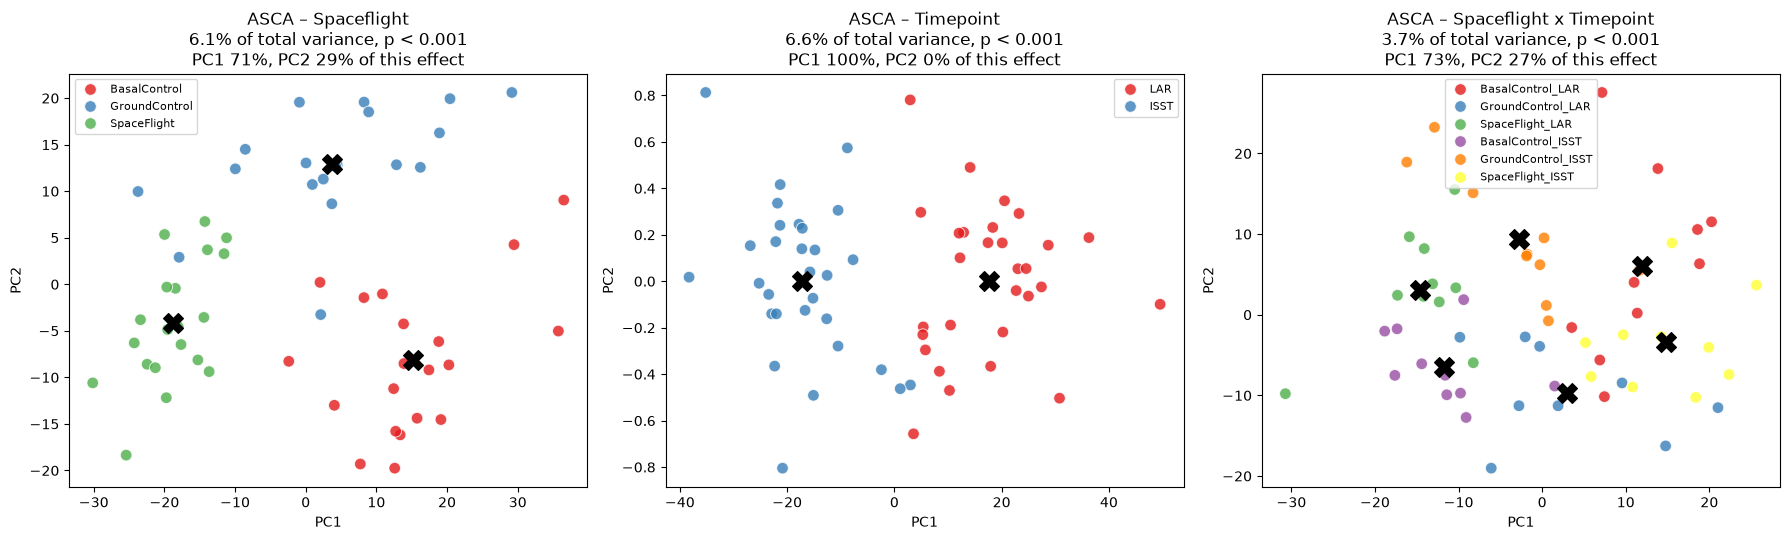

In [32]:
# PCA per biological effect in the final model. All samples of a group share the same point in the effect matrix,
# so the residuals are projected on top to show the spread of individual samples around each group mean
fmt_p = lambda p: "p < 0.001" if p < 0.001 else f"p = {p:.3f}"
effects_to_plot = ['Spaceflight', 'Timepoint', 'Spaceflight x Timepoint']
hue_for = {'Spaceflight': 'Spaceflight', 'Timepoint': 'Timepoint', 'Spaceflight x Timepoint': 'Group'}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, eff in zip(axes, effects_to_plot):
    pca = PCA(n_components=2, random_state=SEED).fit(M_final[eff])
    scores = pca.transform(M_final[eff]) + (M_final['Residual'] @ pca.components_.T)
    df = pd.DataFrame(scores, columns=['PC1', 'PC2'], index=Y.index).join(asca_meta)
    hue = hue_for[eff]
    sns.scatterplot(data=df, x='PC1', y='PC2', hue=hue, s=70, alpha=0.8, palette='Set1', ax=ax)
    means = df.groupby(hue)[['PC1', 'PC2']].mean()
    ax.scatter(means['PC1'], means['PC2'], marker='X', s=200, c='k')               # group means
    ev = pca.explained_variance_ratio_ * 100
    ax.set_title(f"ASCA – {eff}\n{var_expl_final[eff]:.1f}% of total variance, {fmt_p(pvals_final[eff])}\n"
                 f"PC1 {ev[0]:.0f}%, PC2 {ev[1]:.0f}% of this effect")
    ax.legend(fontsize=8, loc='best')
plt.tight_layout()
plt.savefig(FIG_DIR / "22_asca_effects.png", dpi=300, bbox_inches='tight')
plt.show()

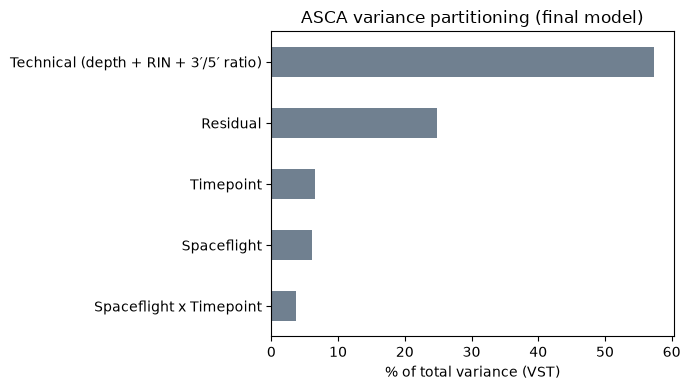

In [33]:
# How the total variance is divided over the effects (final model)
plt.figure(figsize=(7, 4))
var_expl_final.sort_values().plot.barh(color='slategray')
plt.xlabel('% of total variance (VST)')
plt.title('ASCA variance partitioning (final model)')
plt.tight_layout()
plt.savefig(FIG_DIR / "23_asca_variance_partition.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- **Spaceflight (6.1%, p < 0.001):** the three group means (black crosses) are clearly separated. The first component (71% of this effect) separates Space Flight (left) from Basal Control (right). The second component (29%) mainly separates Ground Control from the other two groups. Ground controls therefore differ from the baseline animals as well, so housing conditions alone already change liver gene expression. This is why Ground Control, not Basal Control, is the appropriate reference for a spaceflight effect.
- **Timepoint / mission arm (6.6%, p < 0.001):** LAR and ISS-T separate along a single component. A factor with two levels can only differ in one direction, which is why PC1 explains 100% of this effect.
- **Spaceflight × Timepoint (3.7%, p < 0.001):** the six group means are spread out without following one common pattern, meaning the spaceflight effect differs between LAR and ISS-T. Differential expression is therefore tested separately per mission arm (Section 8).
- In all three panels, individual samples overlap considerably between groups. The biological effects are real and significant, but small relative to the variation between individual mice.
- **Variance partitioning:** in the final model the technical covariates explain 57.4% of the variance, the residual 24.8%, and the three biological effects together 16.4%.

**Next step:** before relying on this model, we check that the technical covariates are not confounded with the experimental design (Section 7.4).

### 7.4 Are the technical covariates confounded with the design?
Modelling a technical covariate is only safe if it is not a proxy for biology. If, for example, Space Flight samples systematically had lower RIN, the technical block would absorb part of the spaceflight effect. We check this in two ways for each final covariate: whether it differs between the six experimental groups (Kruskal–Wallis test), and how much of its variation the experimental design explains (R² of covariate ~ Spaceflight × Timepoint). Finally, we refit the final model without the technical block to see how much the biological effects change.

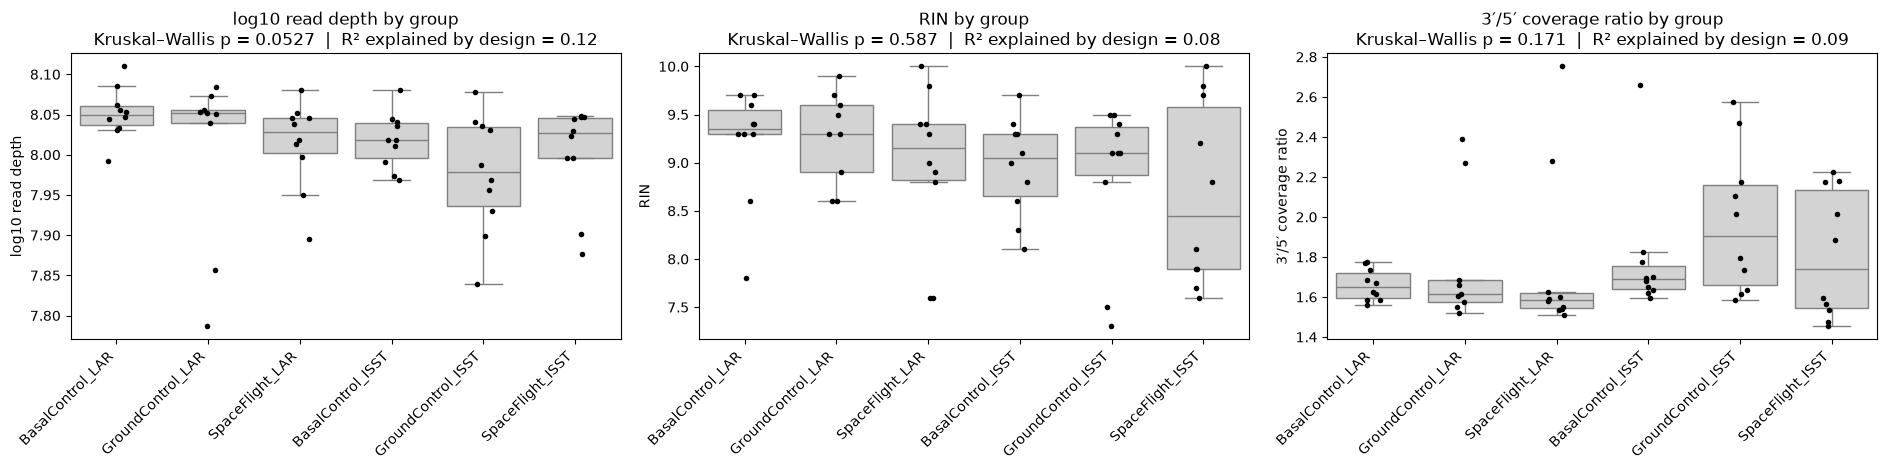

,with technical covariates (%),without technical covariates (%)
Spaceflight,6.11,9.07
Timepoint,6.57,10.52
Spaceflight x Timepoint,3.67,3.57


In [34]:
# For each final technical covariate: does it differ between groups, and how much does the design explain it?
qc_plot = asca_meta[['Group', 'Spaceflight', 'Timepoint', 'logDepth_z', 'RIN_z', 'Ratio35_z']].join(qc_sub)
qc_plot['log10_depth'] = np.log10(qc_plot['read_depth'])
order = [f'{s}_{t}' for t in ['LAR', 'ISST'] for s in ['BasalControl', 'GroundControl', 'SpaceFlight']]
covariates = [('log10_depth', 'logDepth_z', 'log10 read depth'),
              ('rin', 'RIN_z', 'RIN'),
              ('ratio_genebody_cov_3_to_5', 'Ratio35_z', '3′/5′ coverage ratio')]

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, (col, zcol, label) in zip(axes, covariates):
    sns.boxplot(data=qc_plot, x='Group', y=col, order=order, color='lightgray', showfliers=False, ax=ax)
    sns.stripplot(data=qc_plot, x='Group', y=col, order=order, color='k', size=4, ax=ax)
    p_kw = stats.kruskal(*[g[col].values for _, g in qc_plot.groupby('Group')]).pvalue
    r2 = smf.ols(f'{zcol} ~ C(Spaceflight, Sum) * C(Timepoint, Sum)', data=qc_plot).fit().rsquared
    ax.set_title(f'{label} by group\nKruskal–Wallis p = {p_kw:.3g}  |  R² explained by design = {r2:.2f}')
    ax.set_xlabel('')
    ax.set_ylabel(label)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right')
plt.tight_layout()
plt.savefig(FIG_DIR / "25_asca_covariates_vs_design.png", dpi=300, bbox_inches='tight')
plt.show()

# Refit the final model without the technical block and compare the biological effects
keep_cols = [0] + [i for k, c in cols_final.items() if k != TECH_LABEL for i in c]
cols_bio = {k: [keep_cols.index(i) for i in c] for k, c in cols_final.items() if k != TECH_LABEL}
M_bio = effect_matrices(X_final[:, keep_cols], cols_bio, Yc)

compare = pd.DataFrame({
    'with technical covariates (%)':    {k: (M_final[k] ** 2).sum() / ss_total * 100 for k in cols_bio},
    'without technical covariates (%)': {k: (M_bio[k] ** 2).sum() / ss_total * 100 for k in cols_bio},
}).round(2)
compare.to_csv(TABLE_DIR / "asca_with_without_covariates.csv")
display(compare)

**Observation:**
- **None of the technical covariates is significantly associated with the experimental groups:** log10 read depth (Kruskal–Wallis p = 0.053), RIN (p = 0.59) and the 3′/5′ coverage ratio (p = 0.17). The experimental design explains only 12%, 8% and 9% of their variation, respectively. Depth comes closest to significance, driven by lower depth in some Ground Control ISS-T samples, and the 3′/5′ ratio is more variable in the ISS-T groups. These are small, non-significant differences, consistent with the batch being spread over the groups.
- **Removing the technical block from the model makes the biological effects look larger:** Spaceflight from 6.1% to 9.1% and Timepoint from 6.6% to 10.5%. The interaction is unaffected (3.7% vs 3.6%). Because the covariates are only weakly related to the design, this difference is best explained by technical variance that is partly attributed to biology when it is not modelled: the batch is not perfectly balanced over the groups, so without correction some of it ends up in the group effects. With the covariates included, the biological effects are therefore cleaner, but also conservative: if a small part of the covariates' variance is in fact biological, it has been removed.

**Conclusion:** the technical covariates are not confounded with the design, so including them is justified. The final model gives conservative but more reliable estimates of the biological effects.

**Conclusion of Section 7:** spaceflight, mission arm and their interaction all have significant effects on the liver transcriptome (all p < 0.001), but together they explain only 16% of the variance, much less than the technical variation. A residual analysis showed that sequencing depth and RIN alone do not capture the batch effect. Adding the 3′/5′ coverage ratio reduced the unexplained variance from 46% to 25% without changing the biological effect sizes, whereas also adding mapping rate would have removed biological signal. The final technical covariates are not confounded with the experimental design. The significant interaction shows that the spaceflight effect differs between LAR and ISS-T, which is why differential expression is tested separately per mission arm.

**Next step:** identify the individual genes affected by spaceflight with DESeq2 (Section 8), using the same technical covariates as the final ASCA model (depth, RIN and 3′/5′ coverage ratio).

## 8. Differential expression (DESeq2)
We use DESeq2 (Love et al., 2014), via its Python implementation PyDESeq2 (Muzellec et al., 2023). DESeq2 works directly on the raw counts rather than on transformed data. It models each gene's counts with a negative binomial distribution, which accounts for the fact that count data are more variable than a simple Poisson model predicts. It corrects for sequencing depth with the same median-of-ratios size factors as in Section 4.1, and it stabilizes each gene's variance estimate by borrowing information from genes with similar expression levels, which matters with only 9–10 samples per group. Each comparison is tested with a Wald test, and p-values are corrected for testing ~13,000 genes with the Benjamini–Hochberg method (Benjamini & Hochberg, 1995) (false discovery rate).

### 8.1 Models and contrasts
**Input.** DESeq2 requires raw integer counts, so we use the CPM-filtered counts from Section 3.2, rounded to integers (RSEM reports *expected* counts with decimals). ERCC spike-ins are removed: they are artificial control RNAs added during library preparation, not mouse genes. Each sample gets one combined group label (Spaceflight × mission arm, e.g. *SpaceFlight_ISST*) and the z-scored technical covariates, taken directly from the final ASCA model so that both analyses use exactly the same covariates.

**DEG definition.** A gene is called differentially expressed (DEG) if its adjusted p-value is below 0.05 *and* its expression changes at least two-fold (|log2 fold change| > 1).
- **Adjusted p < 0.05:** we test about 13,000 genes at once. With an ordinary p < 0.05, around 650 genes would be "significant" by chance alone. The Benjamini–Hochberg adjustment controls the *false discovery rate*: among the genes we call significant, at most 5% are expected to be false positives.
- **|log2 fold change| > 1:** with 9–10 samples per group, even very small changes (e.g. 10%) can become statistically significant. A two-fold change is a common threshold for a change that is large enough to be biologically meaningful and to be reproduced in other experiments.

Both thresholds are conventions rather than biological constants, but using them consistently makes the numbers comparable across contrasts and models.

In [35]:
# DEG definition used throughout: adjusted p < 0.05 and |log2 fold change| > 1 (at least a 2-fold change)
ALPHA, LFC = 0.05, 1
is_deg = lambda r: (r['padj'] < ALPHA) & (r['log2FoldChange'].abs() > LFC)

# Counts: CPM-filtered raw counts (samples x genes), rounded to integers; ERCC spike-ins removed
de_input_counts = counts_filtered_cpm.T.round().astype(int)
de_input_counts = de_input_counts.loc[:, ~de_input_counts.columns.str.startswith('ERCC-')]

# Sample information: combined group (Spaceflight x mission arm) + technical covariates from the final ASCA model
de_meta = asca_meta.loc[de_input_counts.index, ['Group', 'logDepth_z', 'RIN_z', 'Ratio35_z']].copy()
assert de_meta.notna().all().all(), "missing group or covariate for some samples"

print(f"{de_input_counts.shape[0]} samples x {de_input_counts.shape[1]} genes")
display(de_meta['Group'].value_counts().sort_index().to_frame('samples'))

59 samples x 13029 genes


,samples
Group,
BasalControl_ISST,10
BasalControl_LAR,10
GroundControl_ISST,10
GroundControl_LAR,9
SpaceFlight_ISST,10
SpaceFlight_LAR,10


**Helper functions.** `fit_deseq` fits a DESeq2 model for a given design formula. Outlying counts are detected with Cook's distance and the affected genes are refitted (`refit_cooks=True`), so a single extreme sample cannot create a false DEG. Fitting runs in parallel over 10 CPU cores. `de_table` tests one comparison between two groups and returns the result table; genes without an adjusted p-value (removed by DESeq2's independent filtering because their counts are too low to test) are treated as not significant.

In [36]:
inference = DefaultInference(n_cpus=10)          # fit genes in parallel on 10 CPU cores

def fit_deseq(design):
    """Fit a DESeq2 model with the given design formula (outlier genes refitted via Cook's distance)."""
    dds = DeseqDataSet(counts=de_input_counts, metadata=de_meta, design=design,
                       refit_cooks=True, inference=inference, quiet=True)
    dds.deseq2()
    return dds


def de_table(dds, test, ref):
    """Wald test for one contrast (test vs ref). Genes filtered out by DESeq2 (NaN padj) count as not significant."""
    ds = DeseqStats(dds, contrast=['Group', test, ref], alpha=ALPHA, inference=inference, quiet=True)
    with contextlib.redirect_stdout(io.StringIO()):          # summary() prints the full table; suppress it
        ds.summary()
    res = ds.results_df.copy()
    res['padj'] = res['padj'].fillna(1)
    return res.sort_values('padj')

**Models.** The final model contains the same technical covariates as the final ASCA model (Section 7.2): sequencing depth, RIN and the 3′/5′ coverage ratio, followed by the group. Because the covariates are in the model, each group comparison is adjusted for them. Two sensitivity models show how much the results depend on this choice; one with only depth and RIN (the previous covariates), and one without any technical covariates.

Using one combined group factor (six levels) instead of separate Spaceflight and arm factors lets us compare any two groups directly, which is the standard DESeq2 approach when there is an interaction.

In [37]:
# Final model (same technical covariates as the final ASCA model) and two sensitivity models
MODELS = {
    'final (depth + RIN + 3′/5′ ratio)': "~ logDepth_z + RIN_z + Ratio35_z + Group",
    'depth + RIN':                        "~ logDepth_z + RIN_z + Group",
    'no technical covariates':            "~ Group",
}
MAIN = 'final (depth + RIN + 3′/5′ ratio)'

dds_models = {name: fit_deseq(formula) for name, formula in MODELS.items()}

**Contrasts.** Because the ASCA interaction was significant, every comparison is made *within* a mission arm. Per arm we test three contrasts:
- **FLT vs GC (spaceflight effect):** flight vs ground controls housed in identical habitats. This is the main comparison, since it isolates the effect of spaceflight itself.
- **GC vs BSL (housing effect):** ground controls vs baseline animals, i.e. the effect of the habitat and the time spent in it, without spaceflight.
- **FLT vs BSL (total effect):** spaceflight and housing combined.

In [38]:
# Per mission arm: spaceflight (FLT vs GC), housing (GC vs BSL) and total effect (FLT vs BSL)
contrasts = {}
for arm, label in [('LAR', 'LAR'), ('ISST', 'ISS-T')]:
    contrasts[f'{label}: FLT vs GC']  = (f'SpaceFlight_{arm}',   f'GroundControl_{arm}')
    contrasts[f'{label}: GC vs BSL']  = (f'GroundControl_{arm}', f'BasalControl_{arm}')
    contrasts[f'{label}: FLT vs BSL'] = (f'SpaceFlight_{arm}',   f'BasalControl_{arm}')

# Test every contrast in every model
results = {(m, c): de_table(dds, *contrasts[c]) for m, dds in dds_models.items() for c in contrasts}

# Save all result tables
DE_DIR = TABLE_DIR / "deseq2"
DE_DIR.mkdir(exist_ok=True)
for (m, c), res in results.items():
    res.to_csv(DE_DIR / (re.sub(r'\W+', '_', f"{c}__{m}").strip('_') + ".csv"))
print(f"{len(results)} result tables saved to {DE_DIR}")

18 result tables saved to ../results/tables/deseq2


All six groups contain 10 samples, except Ground Control LAR (9), and all 18 result tables (3 models × 6 contrasts) were saved.

### 8.2 Number of differentially expressed genes
We first count the DEGs per contrast, separately for genes with higher expression (up) and lower expression (down) in the first group of each contrast (e.g. *up* in FLT vs GC = higher in flight). Comparing the three models shows how much the results depend on the correction for technical variation. For the spaceflight contrasts we also check how many of the final model's DEGs are found by the sensitivity models.

model,final (depth + RIN + 3′/5′ ratio),depth + RIN,no technical covariates
contrast,,,
LAR: FLT vs GC,52,47,30
LAR: GC vs BSL,29,15,35
LAR: FLT vs BSL,217,195,277
ISS-T: FLT vs GC,503,376,303
ISS-T: GC vs BSL,285,327,451
ISS-T: FLT vs BSL,638,570,515


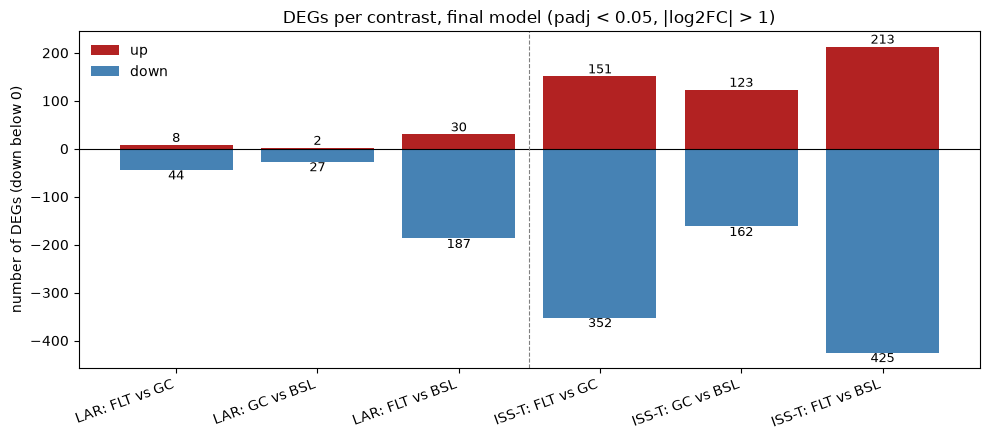

In [39]:
# Number of DEGs per model and contrast; "up" = higher in the first group of the contrast
counts = {}
for (m, c), r in results.items():
    d = is_deg(r)
    counts[(m, c)] = {'up':   int((d & (r['log2FoldChange'] > 0)).sum()),
                      'down': int((d & (r['log2FoldChange'] < 0)).sum())}
deg_summary = pd.DataFrame(counts).T
deg_summary.index.names = ['model', 'contrast']
deg_summary['total'] = deg_summary['up'] + deg_summary['down']
deg_summary.to_csv(TABLE_DIR / "deg_counts.csv")

# Overview: total number of DEGs per contrast (rows) for each model (columns)
display(deg_summary['total'].unstack('model').loc[list(contrasts), list(MODELS)])

# Bar chart for the final model: up-regulated above zero, down-regulated below
s = deg_summary.loc[MAIN].loc[list(contrasts)]
x = np.arange(len(s))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(x, s['up'], color='firebrick', label='up')
ax.bar(x, -s['down'], color='steelblue', label='down')
for i, (u, d) in enumerate(zip(s['up'], s['down'])):
    ax.text(i, u, str(u), ha='center', va='bottom', fontsize=9)
    ax.text(i, -d, str(d), ha='center', va='top', fontsize=9)
ax.axhline(0, color='k', lw=0.8)
ax.axvline(2.5, color='grey', ls='--', lw=0.8)                  # separates LAR (left) from ISS-T (right)
ax.set_xticks(x)
ax.set_xticklabels(s.index, rotation=20, ha='right')
ax.set_ylabel('number of DEGs (down below 0)')
ax.set_title(f'DEGs per contrast, final model (padj < {ALPHA}, |log2FC| > {LFC})')
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG_DIR / "26_deg_counts.png", dpi=300, bbox_inches='tight')
plt.show()

In [40]:
# Robustness to the model choice: how many of the final model's spaceflight DEGs do the sensitivity models also find?
rows = {}
for c in ['LAR: FLT vs GC', 'ISS-T: FLT vs GC']:
    final = set(results[(MAIN, c)].index[is_deg(results[(MAIN, c)])])
    for m in MODELS:
        if m == MAIN:
            continue
        other = set(results[(m, c)].index[is_deg(results[(m, c)])])
        rows[(c, m)] = {'DEGs final model': len(final), 'DEGs this model': len(other),
                        'shared': len(final & other),
                        '% of final DEGs also found': round(100 * len(final & other) / max(len(final), 1), 1)}
model_overlap = pd.DataFrame(rows).T
model_overlap.index.names = ['contrast', 'sensitivity model']
model_overlap.to_csv(TABLE_DIR / "deg_overlap_between_models.csv")
display(model_overlap)

DEGs final model  DEGs this model  \
contrast         sensitivity model                                            
LAR: FLT vs GC   depth + RIN                          52.0             47.0   
                 no technical covariates              52.0             30.0   
ISS-T: FLT vs GC depth + RIN                         503.0            376.0   
                 no technical covariates             503.0            303.0   

                                          shared  % of final DEGs also found  
contrast         sensitivity model                                            
LAR: FLT vs GC   depth + RIN                33.0                        63.5  
                 no technical covariates    21.0                        40.4  
ISS-T: FLT vs GC depth + RIN               331.0                        65.8  
                 no technical covariates   249.0                        49.5

**Observation:**
- **Spaceflight affects the liver much more strongly at ISS-T than at LAR:** 503 DEGs for flight vs ground at ISS-T, against 52 at LAR, roughly ten times more. This matches the significant interaction in ASCA. LAR mice returned alive to Earth before dissection, so part of the spaceflight response may already have reverted; ISS-T mice were dissected on orbit and also spent longer in flight.
- **The housing effect also grows with time:** ground controls differ from baseline animals by 29 DEGs at LAR but 285 at ISS-T. Housing alone therefore already changes liver expression considerably. Which can potentially be due to time as well.
- **Most DEGs are down-regulated** in every contrast (e.g. 352 of 503 at ISS-T flight vs ground, 44 of 52 at LAR).

**Effect of the technical correction:**
- For the **spaceflight contrasts**, correcting for technical covariates *increases* the number of DEGs (LAR: 30 → 47 → 52; ISS-T: 303 → 376 → 503, from no covariates to depth + RIN to the final model). Removing technical noise makes real differences easier to detect, consistent with the ASCA results.
- For the **housing contrast at ISS-T**, the correction *decreases* the number of DEGs (451 → 327 → 285). The batch contains 7 Ground Control but only 1 Basal Control sample, so without correction part of the batch effect looks like a housing effect. The correction removes these false positives.
- **Overlap between models:** about two thirds of the final model's spaceflight DEGs are also found with depth + RIN only (63.5% at LAR, 65.8% at ISS-T), and 40–50% without any technical covariates. The overall conclusions (a much stronger effect at ISS-T, mostly down-regulation) hold in all three models, but the exact gene lists depend noticeably on the technical correction. Individual genes should therefore be interpreted with care --> the genes found in all models are the most robust.

**Next step:** volcano plots show the size and significance of the changes per gene.

### 8.3 Volcano plots

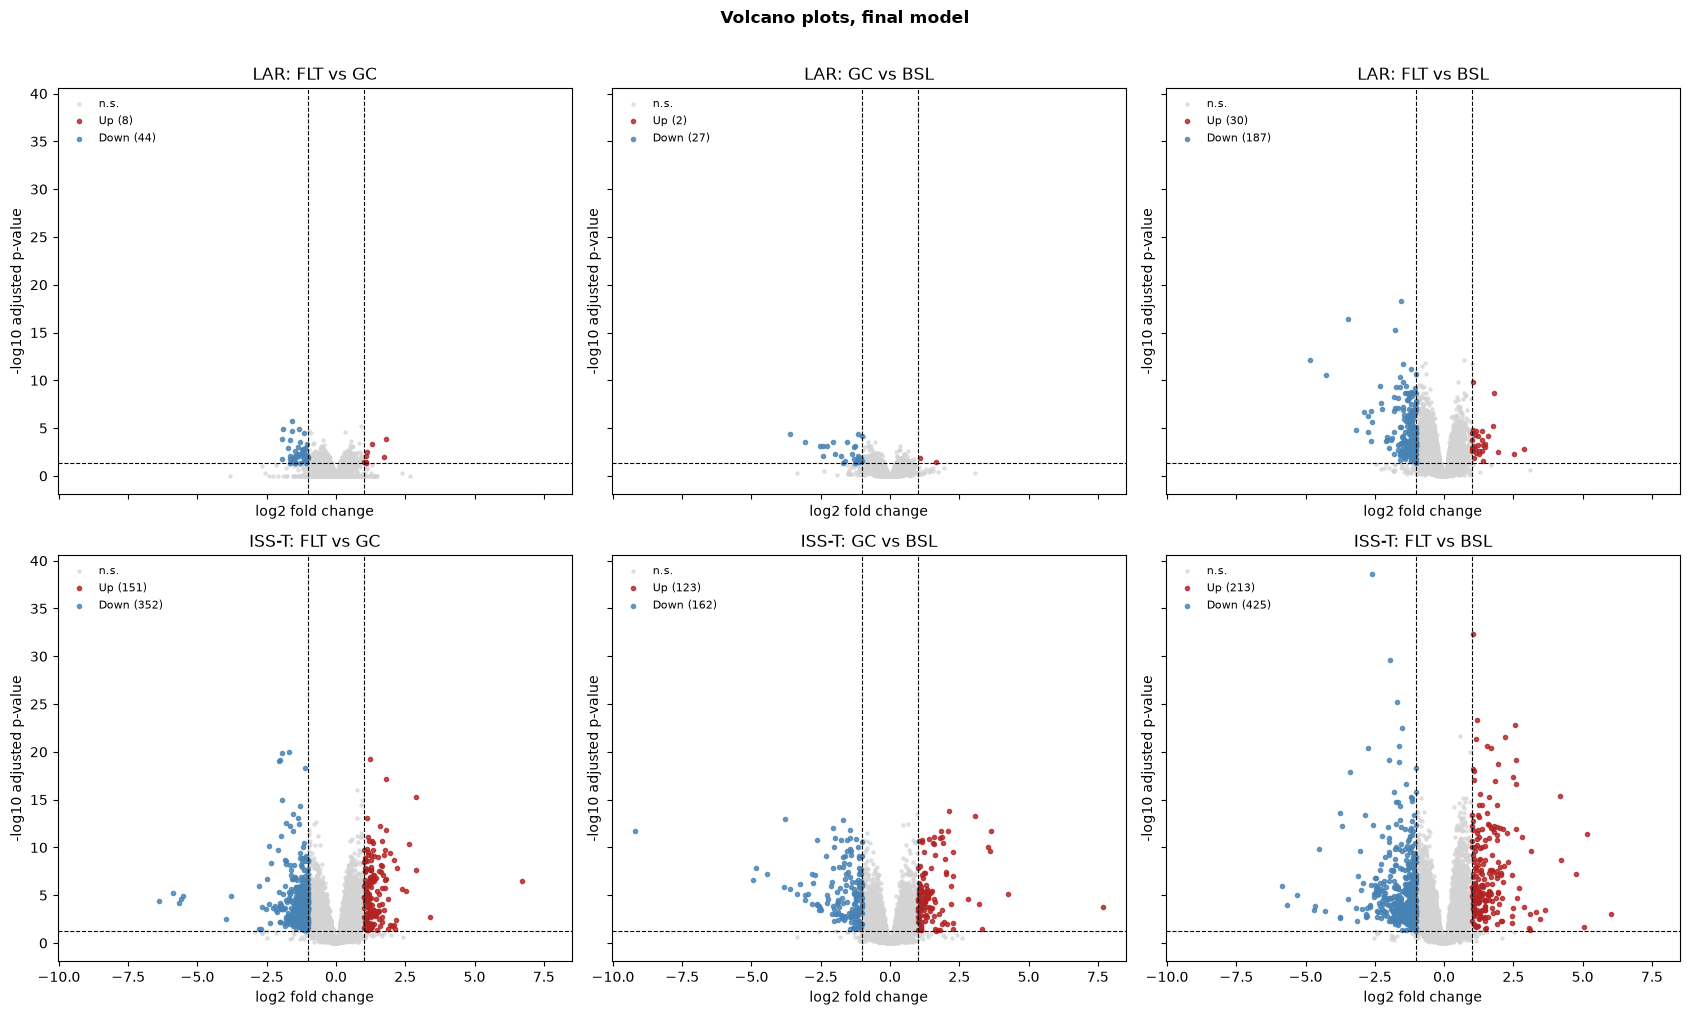

In [41]:
def volcano(res, ax, title):
    """Volcano plot of one DESeq2 result table, coloured by DEG status."""
    df = res.dropna(subset=['log2FoldChange']).copy()
    df['nlp'] = -np.log10(df['padj'].clip(lower=1e-300))          # -log10 adjusted p (clip avoids log(0))
    up   = (df['padj'] < ALPHA) & (df['log2FoldChange'] >  LFC)
    down = (df['padj'] < ALPHA) & (df['log2FoldChange'] < -LFC)
    ns   = ~(up | down)
    ax.scatter(df.loc[ns, 'log2FoldChange'],   df.loc[ns, 'nlp'],   s=5, c='lightgrey', alpha=0.6, label='n.s.')
    ax.scatter(df.loc[up, 'log2FoldChange'],   df.loc[up, 'nlp'],   s=9, c='firebrick', alpha=0.8, label=f'Up ({up.sum()})')
    ax.scatter(df.loc[down, 'log2FoldChange'], df.loc[down, 'nlp'], s=9, c='steelblue', alpha=0.8, label=f'Down ({down.sum()})')
    ax.axhline(-np.log10(ALPHA), ls='--', c='k', lw=0.8)
    for v in (LFC, -LFC):
        ax.axvline(v, ls='--', c='k', lw=0.8)
    ax.set_xlabel('log2 fold change')
    ax.set_ylabel('-log10 adjusted p-value')
    ax.set_title(title)
    ax.legend(frameon=False, loc='upper left', fontsize=8)


# Rows = mission arm, columns = contrast (final model)
fig, axes = plt.subplots(2, 3, figsize=(17, 10), sharex=True, sharey=True)
for ax, c in zip(axes.flat, contrasts):
    volcano(results[(MAIN, c)], ax, c)
fig.suptitle('Volcano plots, final model', fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(FIG_DIR / "27_volcano_all_contrasts.png", dpi=300, bbox_inches='tight')
plt.show()

**Observation:**
- **ISS-T shows both more and stronger changes than LAR.** At LAR, flight vs ground DEGs barely pass the thresholds (adjusted p down to about 10⁻⁶, fold changes mostly between 2- and 6-fold). At ISS-T the significance reaches about 10⁻²⁰, and a handful of genes change more than 30-fold (log2 fold change below −5 or above +6).
- **Most DEGs lie just beyond the thresholds**, with log2 fold changes between 1 and 2.5 (2- to 6-fold). Spaceflight therefore causes many moderate changes rather than a few dramatic ones, with only a small number of extreme genes.
- The **total effect at ISS-T (FLT vs BSL)** contains the most significant genes (up to about 10⁻³⁸), as expected when the spaceflight and housing effects add up.

**Next step:** we check whether the DEGs are robust to the batch itself, by refitting the final model without the 15 batch samples.

### 8.4 Robustness: refitting without the batch samples
The final model corrects for the batch with technical covariates. A more direct test is to remove the 15 batch samples (the minor cluster from Section 6.4) altogether and refit the final model on the remaining samples. If the spaceflight DEGs are real, most of them should also be found without the batch samples. Removing samples also reduces statistical power, however.

In [42]:
# Remove the 15 batch samples (minor cluster, Section 6.4) and refit the final model
batch_samples = meta.index[meta['cluster'] == 'minor cluster']
keep = de_input_counts.index.difference(batch_samples)
print(f"Removed {len(batch_samples)} batch samples; {len(keep)} samples remain:")
display(de_meta.loc[keep, 'Group'].value_counts().sort_index().to_frame('samples'))

dds_nobatch = DeseqDataSet(counts=de_input_counts.loc[keep], metadata=de_meta.loc[keep],
                           design=MODELS[MAIN], refit_cooks=True, inference=inference, quiet=True)
dds_nobatch.deseq2()

# Compare the spaceflight DEGs with and without the batch samples
rows = {}
robust_degs = {}
for c in ['LAR: FLT vs GC', 'ISS-T: FLT vs GC']:
    full = set(results[(MAIN, c)].index[is_deg(results[(MAIN, c)])])
    r_nb = de_table(dds_nobatch, *contrasts[c])
    nobatch = set(r_nb.index[is_deg(r_nb)])
    rows[c] = {'DEGs all samples': len(full), 'DEGs without batch': len(nobatch),
               'shared': len(full & nobatch),
               '% of all-sample DEGs also found': round(100 * len(full & nobatch) / max(len(full), 1), 1)}
    robust_degs[c] = full & nobatch                        # high-confidence DEGs: found with and without batch samples
robustness = pd.DataFrame(rows).T
robustness.to_csv(TABLE_DIR / "deg_robustness_without_batch.csv")
display(robustness)

Removed 15 batch samples; 44 samples remain:


,samples
Group,
BasalControl_ISST,9
BasalControl_LAR,10
GroundControl_ISST,5
GroundControl_LAR,7
SpaceFlight_ISST,5
SpaceFlight_LAR,8


,DEGs all samples,DEGs without batch,shared,% of all-sample DEGs also found
LAR: FLT vs GC,52.0,82.0,38.0,73.1
ISS-T: FLT vs GC,503.0,448.0,243.0,48.3


**Observation:**
- **LAR:** 73% of the DEGs are found again, and the number of DEGs even increases without the batch samples (82 vs 52).
- **ISS-T:** a large spaceflight effect remains (448 DEGs vs 503 with all samples), so the main conclusion is robust. However, only about half of the individual genes (243, 48%) are found in both analyses. This is expected when comparing only 5 vs 5 animals, but it means the exact ISS-T gene list depends considerably on how the batch is handled.

**Conclusion:** the strong spaceflight effect at ISS-T and the weaker effect at LAR do not depend on the batch. The genes found both with batch correction and without the batch samples (38 at LAR, 243 at ISS-T) are the most reliable and are marked as high-confidence DEGs for downstream analyses.

**Next step:** compare the spaceflight DEGs between the two mission arms: which genes respond in both, and do they change in the same direction?

### 8.5 Comparing the spaceflight response between mission arms
ASCA showed a significant interaction: the spaceflight effect differs between LAR and ISS-T. Here we look at this at gene level. Which spaceflight DEGs (FLT vs GC) are shared between the two arms, and do shared genes change in the same direction (concordant) or in opposite directions (discordant)? Genes that respond to spaceflight in both arms are the most consistent spaceflight-responsive genes; genes with opposite directions could indicate recovery or over-compensation after return to Earth. Gene symbols are retrieved from Ensembl IDs with MyGene.info (Xin et al., 2016).

Spaceflight DEGs - LAR: 52 | ISS-T: 503 | shared: 20 (10 same direction, 10 opposite direction)


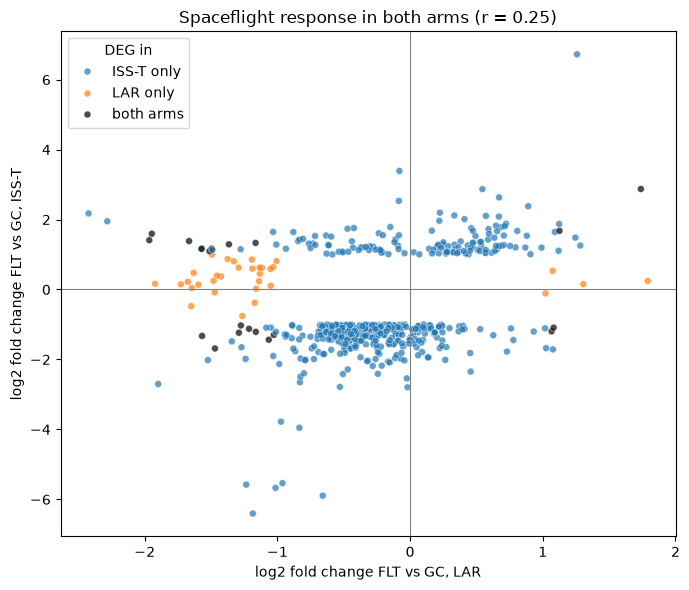

In [43]:
# Spaceflight DEGs (FLT vs GC) per mission arm, final model
lar  = results[(MAIN, 'LAR: FLT vs GC')]
isst = results[(MAIN, 'ISS-T: FLT vs GC')]
deg_lar, deg_isst = set(lar.index[is_deg(lar)]), set(isst.index[is_deg(isst)])
shared = sorted(deg_lar & deg_isst)
concordant = [g for g in shared if np.sign(lar.loc[g, 'log2FoldChange']) == np.sign(isst.loc[g, 'log2FoldChange'])]

print(f"Spaceflight DEGs - LAR: {len(deg_lar)} | ISS-T: {len(deg_isst)} | shared: {len(shared)} "
      f"({len(concordant)} same direction, {len(shared) - len(concordant)} opposite direction)")

# Fold changes in both arms for all genes that are a DEG in at least one arm
union = sorted(deg_lar | deg_isst)
fc = pd.DataFrame({'LAR': lar.loc[union, 'log2FoldChange'], 'ISS-T': isst.loc[union, 'log2FoldChange']})
fc['DEG in'] = np.where(fc.index.isin(shared), 'both arms',
               np.where(fc.index.isin(list(deg_lar)), 'LAR only', 'ISS-T only'))

plt.figure(figsize=(7, 6))
sns.scatterplot(data=fc, x='LAR', y='ISS-T', hue='DEG in', s=25, alpha=0.7,
                palette={'both arms': 'black', 'LAR only': 'tab:orange', 'ISS-T only': 'tab:blue'})
plt.axhline(0, color='grey', lw=0.8)
plt.axvline(0, color='grey', lw=0.8)
plt.xlabel('log2 fold change FLT vs GC, LAR')
plt.ylabel('log2 fold change FLT vs GC, ISS-T')
plt.title(f"Spaceflight response in both arms (r = {fc['LAR'].corr(fc['ISS-T']):.2f})")
plt.tight_layout()
plt.savefig(FIG_DIR / "28_lfc_lar_vs_isst.png", dpi=300, bbox_inches='tight')
plt.show()

In [44]:
# Table of the shared spaceflight DEGs, with gene symbols (MyGene.info, needs internet)
strip = lambda ids: pd.Index(ids).str.replace(r'\.\d+$', '', regex=True)       # remove Ensembl version suffix
hits = mygene.MyGeneInfo().querymany(list(strip(shared)), scopes='ensembl.gene', fields='symbol',
                                     species='mouse', as_dataframe=True, verbose=False)
symbols = hits[~hits.index.duplicated()]['symbol']

shared_tab = pd.DataFrame({
    'symbol':       strip(shared).map(symbols),
    'log2FC LAR':   lar.loc[shared, 'log2FoldChange'].values,
    'padj LAR':     lar.loc[shared, 'padj'].values,
    'log2FC ISS-T': isst.loc[shared, 'log2FoldChange'].values,
    'padj ISS-T':   isst.loc[shared, 'padj'].values,
}, index=shared)
shared_tab['pattern'] = np.where(shared_tab.index.isin(concordant), 'same direction', 'opposite direction')
shared_tab['high-confidence (both arms)'] = [g in robust_degs['LAR: FLT vs GC'] and g in robust_degs['ISS-T: FLT vs GC']
                                             for g in shared]
shared_tab.index.name = 'gene_id'
shared_tab.to_csv(TABLE_DIR / "shared_DEGs_LAR_ISST.csv")
display(shared_tab.sort_values(['pattern', 'log2FC ISS-T']).round(3))

,symbol,log2FC LAR,padj LAR,log2FC ISS-T,padj ISS-T,pattern,high-confidence (both arms)
gene_id,,,,,,,
ENSMUSG00000045672,Col27a1,1.066,0.008,-1.196,0.000,opposite direction,False
ENSMUSG00000072949,Acot1,1.082,0.037,-1.092,0.008,opposite direction,False
ENSMUSG00000027605,Acss2,-1.512,0.021,1.095,0.037,opposite direction,False
ENSMUSG00000078452,Raet1d,-1.572,0.000,1.160,0.000,opposite direction,True
ENSMUSG00000041220,Elovl6,-1.495,0.036,1.167,0.041,opposite direction,False
ENSMUSG00000066441,Rdh11,-1.365,0.001,1.291,0.000,opposite direction,False
ENSMUSG00000032561,Acp3,-1.164,0.016,1.331,0.000,opposite direction,False
ENSMUSG00000037071,Scd1,-1.666,0.016,1.384,0.011,opposite direction,False
ENSMUSG00000022351,Sqle,-1.965,0.000,1.410,0.001,opposite direction,False


**Observation:**
- **The spaceflight response differs strongly between the two arms.** Only 20 genes are DEGs in both LAR (52) and ISS-T (503), and the fold changes of all DEGs correlate only weakly between the arms (r = 0.25). The scatter plot shows this as two separate groups: LAR-only DEGs (orange) barely change at ISS-T, and most ISS-T-only DEGs (blue) barely change at LAR. This matches the significant interaction in ASCA.
- **Half of the shared genes change in opposite directions (10 of 20).** Strikingly, most of these are genes of **lipid and cholesterol synthesis**: *Scd1* and *Elovl6* (fatty-acid synthesis), *Sqle* (cholesterol synthesis), *Acss2* (acetyl-CoA production), *Pnpla3* and *Rdh11*. They are **up-regulated at ISS-T** (dissected in orbit) but **down-regulated at LAR** (after return to Earth). This suggests that lipid synthesis is activated during spaceflight and reverses, potentially hinting at an active re-adaptiation process, after return from orbit.
- **The other 10 genes change in the same direction in both arms**, making them the most consistent spaceflight-responsive genes. They include the circadian clock genes *Bmal1* (up) and *Dbp* (down); major urinary proteins *Mup12* and *Mup16* (down); the inflammation-associated *S100a8* and *S100a9* (down); and the stress-responsive metallothionein *Mt2* (down).
- Four shared genes are high-confidence in both arms (also found without the batch samples): *Bmal1*, *Chka*, *Slc2a5* and *Raet1d*.

One noteworth discussion point is that the circadian clock genes such as *Bmal1* and *Dbp* are strongly influenced by the time of day of dissection. Their consistent change could reflect a real spaceflight effect on the liver clock, but also differences in dissection timing between flight and ground animals; the metadata do not allow us to distinguish the two.

**Conclusion of Section 8:** spaceflight changes the expression of 503 liver genes at ISS-T but only 52 at LAR, mostly through down-regulation and moderate (2- to 6-fold) changes. Correcting for technical covariates increases the number of spaceflight DEGs and removes false housing-effect DEGs caused by the batch. The large effect at ISS-T is robust to removing the batch samples, although the exact gene list is only partly stable; the genes found in both analyses are marked as high-confidence. The two mission arms share only 20 DEGs, and half of these, mainly genes of lipid and cholesterol synthesis, change in opposite directions, suggesting that part of the spaceflight response reverses after return to Earth.

**Next step:** to find out which biological pathways the spaceflight DEGs belong to, we map them onto a protein–protein interaction network and perform pathway enrichment (Section 9).

## 9. Network and pathway analysis (STRING / Cytoscape)
Individual DEGs are hard to interpret one by one. Proteins work together in pathways and complexes, so we place the spaceflight DEGs in a protein–protein interaction network and test which pathways are over-represented. This is done with the **STRING** database (Szklarczyk et al., 2023) via the **stringApp** in **Cytoscape** (Shannon et al., 2003; Doncheva et al., 2019) Cytoscape is an interactive desktop application, so the network steps are performed outside this notebook; the notebook exports the input files and documents the procedure so it can be reproduced.

### 9.1 Export of the network input
For each mission arm we export the spaceflight DEGs (FLT vs GC, final model): a plain gene list to import into STRING, and an attribute table with gene symbol, log2 fold change, p-values, direction and high-confidence status (Section 8.4), which is loaded into Cytoscape to colour and filter the network nodes. We also export the list of all ~13,000 expressed genes that were tested, which can serve as a background for enrichment.

In [45]:
# Export the spaceflight DEGs (FLT vs GC, final model) per mission arm as input for STRING / Cytoscape
NET_DIR = TABLE_DIR / "cytoscape"
NET_DIR.mkdir(exist_ok=True)

# Gene symbols for all DEGs of both arms in one query (MyGene.info, needs internet)
all_ids = strip(sorted(deg_lar | deg_isst))
hits = mygene.MyGeneInfo().querymany(list(all_ids), scopes='ensembl.gene', fields='symbol',
                                     species='mouse', as_dataframe=True, verbose=False)
symbols_all = hits[~hits.index.duplicated()]['symbol']

for arm, c in [('LAR', 'LAR: FLT vs GC'), ('ISST', 'ISS-T: FLT vs GC')]:
    res = results[(MAIN, c)]
    r = res[is_deg(res)]
    out = pd.DataFrame({
        'gene_id':         strip(r.index),
        'symbol':          strip(r.index).map(symbols_all),
        'log2FoldChange':  r['log2FoldChange'].values,
        'pvalue':          r['pvalue'].values,
        'padj':            r['padj'].values,
        'direction':       np.where(r['log2FoldChange'] > 0, 'up', 'down'),
        'high_confidence': r.index.isin(list(robust_degs[c])),
    })
    out.to_csv(NET_DIR / f"string_attributes_{arm}.csv", index=False)                     # node attributes for Cytoscape
    out['gene_id'].to_csv(NET_DIR / f"string_genelist_{arm}.txt", index=False, header=False)   # input list for STRING
    print(f"{arm}: {len(out)} genes ({(out.direction == 'up').sum()} up, {(out.direction == 'down').sum()} down, "
          f"{out.high_confidence.sum()} high-confidence)")

# All tested (expressed) genes, usable as enrichment background
pd.Series(strip(de_input_counts.columns)).to_csv(NET_DIR / "background_expressed_genes.txt", index=False, header=False)

LAR: 52 genes (8 up, 44 down, 38 high-confidence)
ISST: 503 genes (151 up, 352 down, 243 high-confidence)


### 9.2 Network construction and enrichment in Cytoscape
The following steps were performed in Cytoscape 3.10.5 with the stringApp, separately for LAR and ISS-T:

1. **Import:** *File → Import → Network from Public Databases → STRING: protein query*, species *Mus musculus*, pasting the gene list (`string_genelist_LAR.txt` / `string_genelist_ISST.txt`). The **confidence cutoff was set to 0.4** (STRING's default "medium confidence"): only interactions with a combined evidence score ≥ 0.4 are included. No additional interactors were added, so the network contains only our DEGs.
2. **Node attributes:** the attribute table (`string_attributes_*.csv`) was imported via *File → Import → Table from File* and matched on the Ensembl ID, so nodes can be coloured/shaped by log2 fold change (red = up, blue = down) and high-confidence genes can be highlighted.
3. **Enrichment:** *STRING Enrichment → Retrieve functional enrichment*, keeping pathways from **KEGG** (Kanehisa et al., 2023) and **WikiPathways** (Agrawal et al., 2024) with a false discovery rate below 0.05.
4. **Export:** the enrichment tables were saved to `results/tables/cytoscape/` and the networks as images to `results/figures/`.

## References
- Agrawal, A., et al. (2024). WikiPathways 2024: next generation pathway database. *Nucleic Acids Research*, 52(D1), D679–D689. https://doi.org/10.1093/nar/gkad960
- Anders, S., & Huber, W. (2010). Differential expression analysis for sequence count data. *Genome Biology*, 11, R106. https://doi.org/10.1186/gb-2010-11-10-r106
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: a practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B*, 57(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x
- Doncheva, N. T., Morris, J. H., Gorodkin, J., & Jensen, L. J. (2019). Cytoscape StringApp: network analysis and visualization of proteomics data. *Journal of Proteome Research*, 18(2), 623–632. https://doi.org/10.1021/acs.jproteome.8b00702
- Fang, Z., Liu, X., & Peltz, G. (2023). GSEApy: a comprehensive package for performing gene set enrichment analysis in Python. *Bioinformatics*, 39(1), btac757. https://doi.org/10.1093/bioinformatics/btac757
- Freedman, D., & Lane, D. (1983). A nonstochastic interpretation of reported significance levels. *Journal of Business & Economic Statistics*, 1(4), 292–298. https://doi.org/10.1080/07350015.1983.10509354
- Kanehisa, M., Furumichi, M., Sato, Y., Kawashima, M., & Ishiguro-Watanabe, M. (2023). KEGG for taxonomy-based analysis of pathways and genomes. *Nucleic Acids Research*, 51(D1), D587–D592. https://doi.org/10.1093/nar/gkac963
- Kuleshov, M. V., et al. (2016). Enrichr: a comprehensive gene set enrichment analysis web server 2016 update. *Nucleic Acids Research*, 44(W1), W90–W97. https://doi.org/10.1093/nar/gkw377
- Love, M. I., Huber, W., & Anders, S. (2014). Moderated estimation of fold change and dispersion for RNA-seq data with DESeq2. *Genome Biology*, 15, 550. https://doi.org/10.1186/s13059-014-0550-8
- Muzellec, B., Teleńczuk, M., Cabeli, V., & Andreux, M. (2023). PyDESeq2: a python package for bulk RNA-seq differential expression analysis. *Bioinformatics*, 39(9), btad547. https://doi.org/10.1093/bioinformatics/btad547
- NASA Open Science Data Repository. OSD-245. https://osdr.nasa.gov/bio/repo/data/studies/OSD-245
- Shannon, P., et al. (2003). Cytoscape: a software environment for integrated models of biomolecular interaction networks. *Genome Research*, 13(11), 2498–2504. https://doi.org/10.1101/gr.1239303
- Smilde, A. K., Jansen, J. J., Hoefsloot, H. C. J., Lamers, R.-J. A. N., van der Greef, J., & Timmerman, M. E. (2005). ANOVA-simultaneous component analysis (ASCA): a new tool for analyzing designed metabolomics data. *Bioinformatics*, 21(13), 3043–3048. https://doi.org/10.1093/bioinformatics/bti476
- Szklarczyk, D., et al. (2023). The STRING database in 2023: protein–protein association networks and functional enrichment analyses for any sequenced genome of interest. *Nucleic Acids Research*, 51(D1), D638–D646. https://doi.org/10.1093/nar/gkac1000
- Thiel, M., Féraud, B., & Govaerts, B. (2017). ASCA+ and APCA+: Extensions of ASCA and APCA in the analysis of unbalanced multifactorial designs. *Journal of Chemometrics*, 31(6), e2895. https://doi.org/10.1002/cem.2895
- Xin, J., et al. (2016). High-performance web services for querying gene and variant annotation. *Genome Biology*, 17, 91. https://doi.org/10.1186/s13059-016-0953-9
- Yu, Y., Mai, Y., Zheng, Y., & Shi, L. (2024). Assessing and mitigating batch effects in large-scale omics studies. *Genome Biology*, 25, 254. https://doi.org/10.1186/s13059-024-03401-9